# Assignment 5: Autoencoders
Date: 

Report produced by:  
COMP 3705 Group 3

## Data Preprocessing

### Data Loading

In [ ]:
import pandas as pd
import numpy as np
import math as m
import tensorflow as tf
from sklearn.model_selection import train_test_split as tts
from keras.models import Model
from keras.layers import Input, Dense
import matplotlib.pyplot as plt
# Set TensorFlow deprication warnings to False
import tensorflow.python.util.deprecation as deprecation
deprecation._PRINT_DEPRECATION_WARNINGS = False

# Load the Dataset and Check Shape
df = pd.read_csv("csvImages 10k x 784.csv")
df_clean = df.copy()
print("Data Shape:", df_clean.shape)

Data Shape: (9999, 784)


The data was obtained from Kaggle, and downloaded form [Learn](https://learn.rrc.ca/d2l/le/content/759307/Home). It was said to contain 10,000 images of size 28x28 (784 pixels), with each image being flattened as a 1D-array. The individual values were said to be recorded as grayscale so we expected there to be exactly 784 columns. Upon inspecting the shape of the data, we can confirm that there are 784 columns, coincidign with our assumptions of it being grayscale and will proceed accordingly. Of the 10,000 rows, we found that one was missing. As we still have enough data for training our encoder, this will not cause any problems going forward.

### Check Data Integrity

In [ ]:
print("Min value across all columns:",df_clean.min().min())
print("Max value across all columns:",df_clean.max().max())
print("Number of Duplicate Rows:",df_clean.duplicated().sum())
print("Number of missing values in data:",df_clean.isna().sum().sum())

Number of Duplicate Rows: 1
Min value across all columns: 0
Max value across all columns: 255
Number of missing values in data: 0


Since our data is supposed to contain pixel data for grayscale images, the values should naturally fall within the range of [0,255]. To check this, we checked the minimum and maximum values in each column, and then took the maximum and minimum value from this set. This gives us an accurate representation for our value ranges as no column will have a value larger than the absolute max or lower than the absolute min. As we had expected, the data across all columns did fall within the range of [0,255], so we can determine that there are no unexpected grayscale values.  
Next, we checked whether any images had been duplicated. Images with the same exact pixel information could cause our encoder to disproportionately value them and overadjust it's weights. Since only 2 rows contained the same pixel data, we will be removing one of them to preserve the quality of our data.  
Finally, we checked if any column contained missing values. Since this also returned no missing pixel values across all the images recorded in the data, we can continue with the dataset without further cleaning.  

In [72]:
df_clean = df_clean.drop_duplicates()
print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (9998, 784)


### Reshape for Visualizations

In [73]:
# Convert DataFrame to Numpy Array and Normalize Values
img_data = df_clean.values/255
img_data = img_data.reshape((-1,28,28))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 28, 28)
Shape of Each Row: (28, 28)


After checking the data, we converted the DataFrame into a NumPy array and normalized the pixel values by dividing them by 255. This changed the value range from 0–255 to  0–1. Normalization was done to help the neural network train more effectively by ensuring no one pixel disproportionately influences the model.  
Next, we reshaped each image from 784 values into a 28 × 28 image. We did this because each row contains 784 points, each pertaining to a pixel in a 28x28 image. Reshaping the data allows us to display the images using Matplotlib before training the autoencoder.

### Pre-Encoding Visualizations

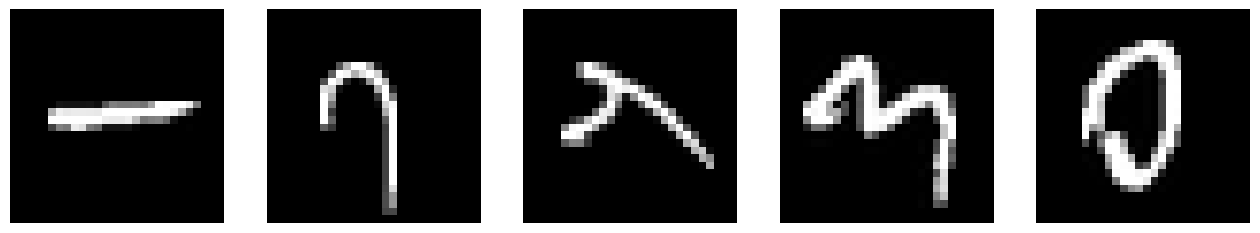

In [74]:
plt.figure(figsize=(16,10))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(img_data[i],cmap="gray")
    plt.axis("off")

We plotted the first five images using using a grayscale colormap. These original images serve as the baseline we will compare the decoded images against when judging the autoencoder.  
Each image shows a light digit stroke on a dark background, roughly centred in the frame. Most pixels, especially around the edges, are 0 (black) and carry no information about the digit.  
Much of each image is "empty" space, which suggests the images can be compressed substantially without losing the digit itself.

### Reshape for Data Encoding

In [75]:
img_data = img_data.reshape((-1,28**2))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 784)
Shape of Each Row: (784,)


We flattened each 28×28 image back into a one-dimensional array of 784 values. Keras `Dense` layers take one-dimensional input, so the autoencoder's input layer expects 784 values per image.  
The data shape is back to **(9998, 784)**, with values between 0 and 1, which is ready to feed into the network. 

In [76]:
# Dummy Cell - Used for Run All Above - Remove Before Submission

## Model Selection

In [ ]:
def compile_autoencoder(data,autoencoder,weights,validation=None,optimizer="adadelta",loss="binary_crossentropy",epochs=50):
    if weights != None:
        autoencoder["decoded"].set_weights(weights)
    
    autoencoder["decoded"].compile(optimizer=optimizer,loss=loss)
    autoencoder["decoded"].fit(data,data,validation_data=validation,epochs=epochs)

def create_autoencoder(data,activation_function="relu",activation_final="sigmoid",loss_function="binary_crossentropy",optimizer="adadelta",weights = None, epochs=50):
    tf.random.set_seed(42)
    autoencoder = dict()
    train_data, test_data = tts(data,train_size=0.9,test_size=0.1,random_state=42)
    # Define Input Layer
    input_layer = Input(shape=(784,))
    # Define Encoding Layers
    hidden_encoding1 = Dense(1024,activation=act)(input_layer)
    hidden_encoding2 = Dense(512,activation=act)(hidden_encoding1)
    hidden_encoding3 = Dense(256,activation=act)(hidden_encoding2)
    hidden_encoding4 = Dense(128,activation=act)(hidden_encoding3)
    hidden_encoding5 = Dense(64,activation=act)(hidden_encoding4)
    hidden_encoding6 = Dense(32,activation=act)(hidden_encoding5)
    # Final Encoding Layer
    encoding_stage = Dense(16,activation=act)(hidden_encoding6)
    # Define Decoding Layers
    hidden_decoding1 = Dense(32,activation=act)(encoding_stage)
    hidden_decoding2 = Dense(64,activation=act)(hidden_decoding1)
    hidden_decoding3 = Dense(128,activation=act)(hidden_decoding2)
    hidden_decoding4 = Dense(256,activation=act)(hidden_decoding3)
    hidden_decoding5 = Dense(512,activation=act)(hidden_decoding4)
    hidden_decoding6 = Dense(1024,activation=act)(hidden_decoding5)
    # Final Decoding Layer
    decoding_stage = Dense(784,activation=act_fnl)(hidden_decoding6)
    # Define Autoencoder Model
    autoencoder = {"encoded": Model(input_layer,encoding_stage),
                    "decoded": Model(input_layer,decoding_stage),
                    "Final Activation": activation_final,
                    "Hidden Activation": activation_function,
                    "Loss Function": loss_function,
                    "Optimizer": optimizer,
                    "Epochs": epochs,
    }
    # Set Starting Weights
    initial_weights = weights
        
    # Compile and Train Model
    compile_autoencoder(train_data,autoencoder,initial_weights,optimizer=optimizer,loss=loss,epochs=epochs)
    autoencoder["Loss"] = autoencoder["decoded"].evaluate(test_data,test_data,verbose=0)
    return autoencoder

def plot_images(data, autoencoders,num_img=5):
    data = data.reshape((-1,28**2))
    for key in autoencoders:
        encoded_img = autoencoders[key]["encoded"].predict(data[:num_img]).reshape((-1,4,4))
        decoded_img = autoencoders[key]["decoded"].predict(data[:num_img]).reshape((-1,28,28))
        loss = autoencoders[key]["Loss Function"]
        hidden_act = autoencoders[key]["Hidden Activation"]
        final_act = autoencoders[key]["Final Activation"]
        data = data.reshape((-1,28,28))
        # print("Autoencoder ID:",i)
        plt.figure(figsize=(16,10))
        for j in range(num_img):
            plt.subplot(3,num_img,j+1)
            plt.imshow(data[j],cmap="gray")
            plt.axis("off")

            plt.subplot(3,num_img,j+1+num_img)
            plt.imshow(encoded_img[j],cmap="gray")
            plt.axis("off")

            plt.subplot(3,num_img,j+1+num_img*2)
            plt.imshow(decoded_img[j],cmap="gray")
            plt.axis("off")
        data = data.reshape((-1,28**2))

Before settling on our current architecture, we first tested four different encoders in separate files. The first three were to determine whether more, equal, or less neurons in the first layer resulted in better reconstruction quality. The results were that by a very slim margin, having more neurons in the first layer and last layer than in the input and output produced slightly better reconstructions overall. Afterwards, we tested a fourth architecture to find out how small we could get our bottleneck. In this fourth test file, we tested a latent size of 32, and when that produced good reconstructions we reduced it further to 16, resulting in our current autoencoder architecture.

Since we managed to reduce our latent dimension to 16, equivalent to a 4x4 representation when reshaped, we decided against testing encoders with convolution layers. Our existing Dense encoder architecture had already achieved a sufficiently small encoded representation while maintaining great reconstruction quality. Therefore, we determined that experimenting further with convolutional layers was unnecessary given that our objectives were to minimize encoded size and maximizing reconstruction quality.

## Iteration 1

In [ ]:
activation_function = ["relu","sigmoid"]
activation_final = ["sigmoid","softmax"]
loss_functions = ["binary_crossentropy","mean_squared_error","mean_absolute_error"]
optimizer = ["adadelta"]
autoencoders1 = dict()
i=0
for act in activation_function:
    for act_fnl in activation_final:
        for loss in loss_functions:
            for opti in optimizer:
                autoencoders1[i] = create_autoencoder(img_data,act,act_fnl,loss,opti)
                i += 1
df_encoded_pars1 = pd.DataFrame(autoencoders1).transpose().drop(columns=["decoded","encoded"])

Epoch 1/50
8998/8998 [==============================] - 12s 1ms/step - loss: 0.3331
Epoch 2/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.2290
Epoch 3/50
8998/8998 [==============================] - 11s 1ms/step - loss: 0.2277
Epoch 4/50
8998/8998 [==============================] - 11s 1ms/step - loss: 0.2263
Epoch 5/50
8998/8998 [==============================] - 12s 1ms/step - loss: 0.2168
Epoch 6/50
8998/8998 [==============================] - 11s 1ms/step - loss: 0.2086
Epoch 7/50
8998/8998 [==============================] - 11s 1ms/step - loss: 0.2047
Epoch 8/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.2019
Epoch 9/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1993
Epoch 10/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1965
Epoch 11/50
8998/8998 [==============================] - 10s 1ms/step - loss: 0.1943
Epoch 12/50
8998/8998 [==============================] - 10s 1ms/step - lo

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.137855,binary_crossentropy,adadelta
1,50,sigmoid,relu,0.0226843,mean_squared_error,adadelta
2,50,sigmoid,relu,0.0509161,mean_absolute_error,adadelta
3,50,softmax,relu,0.5302,binary_crossentropy,adadelta
4,50,softmax,relu,0.0839628,mean_squared_error,adadelta
5,50,softmax,relu,0.100815,mean_absolute_error,adadelta
6,50,sigmoid,sigmoid,0.241193,binary_crossentropy,adadelta
7,50,sigmoid,sigmoid,0.0599586,mean_squared_error,adadelta
8,50,sigmoid,sigmoid,0.101745,mean_absolute_error,adadelta
9,50,softmax,sigmoid,0.601837,binary_crossentropy,adadelta


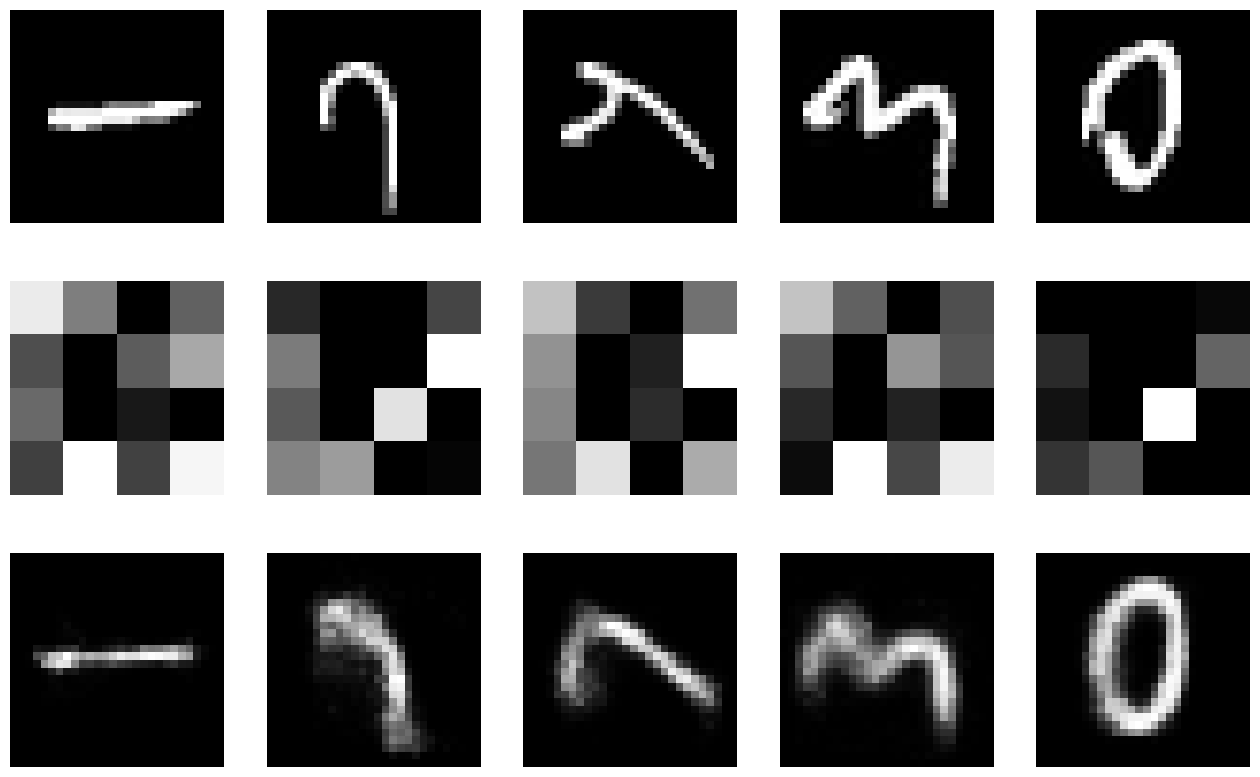

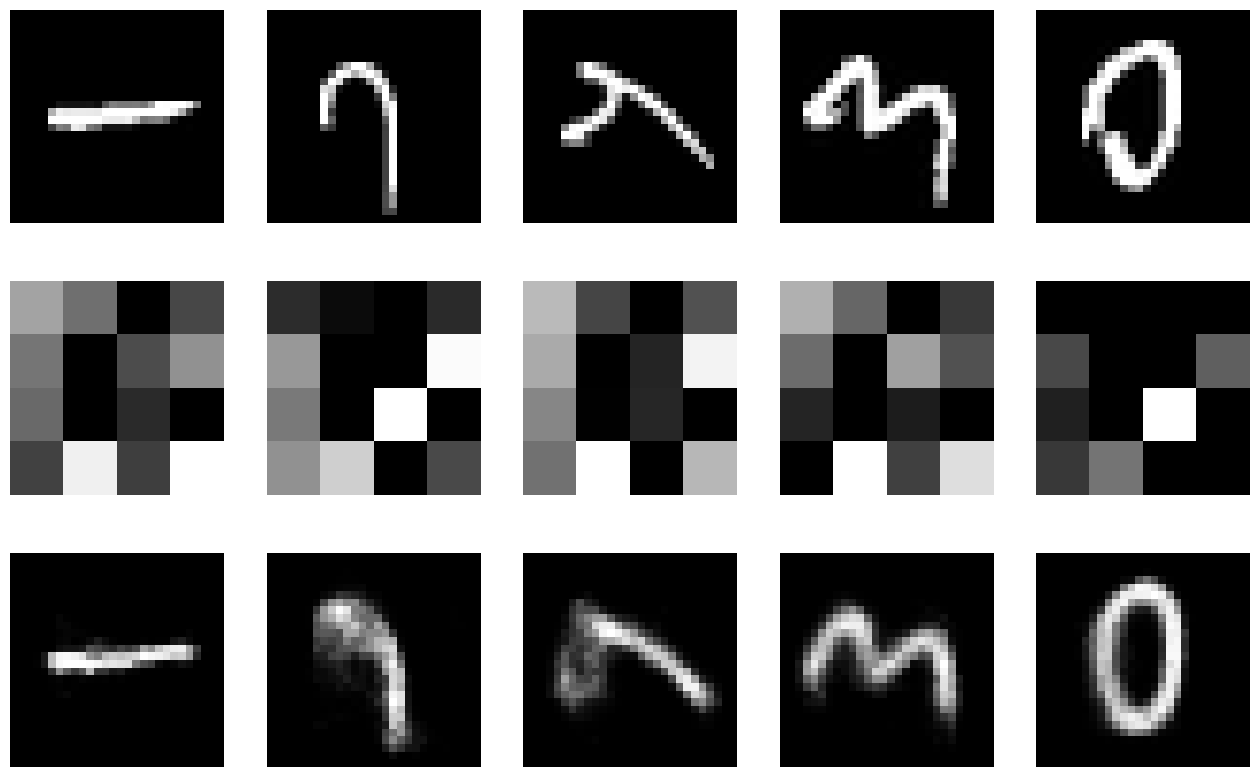

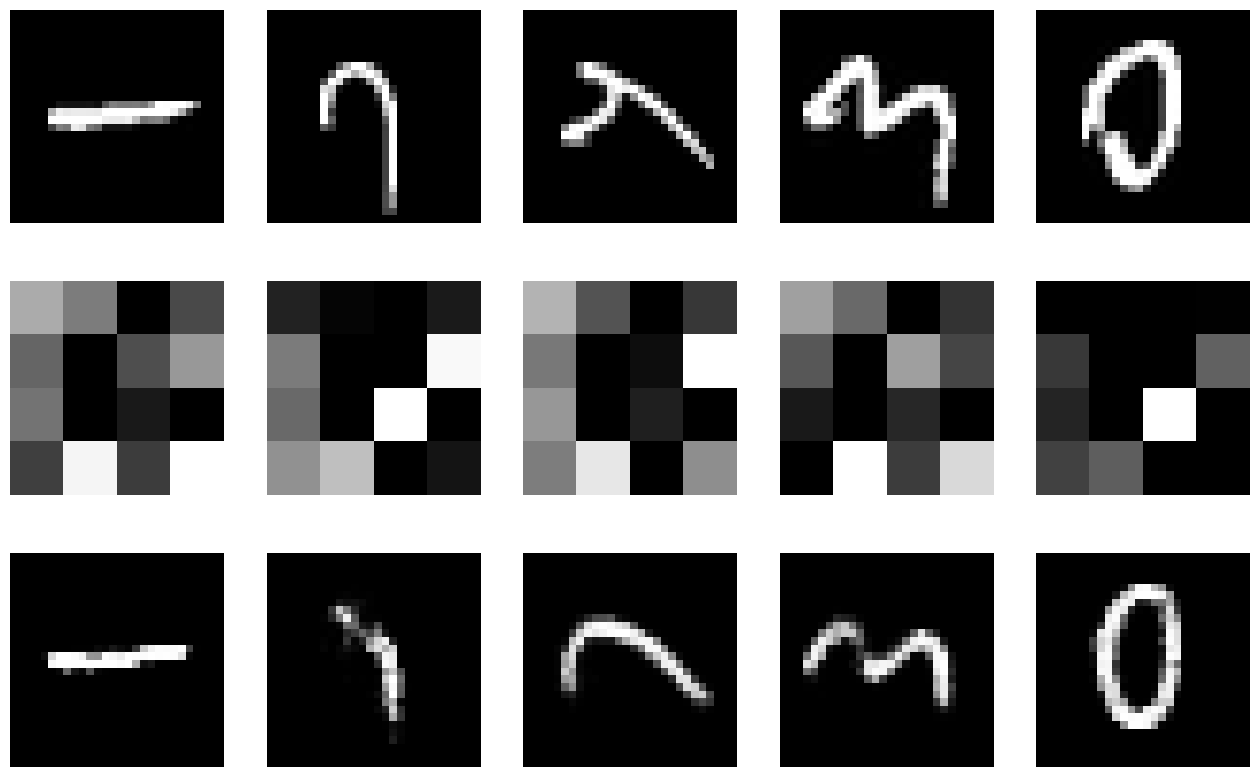

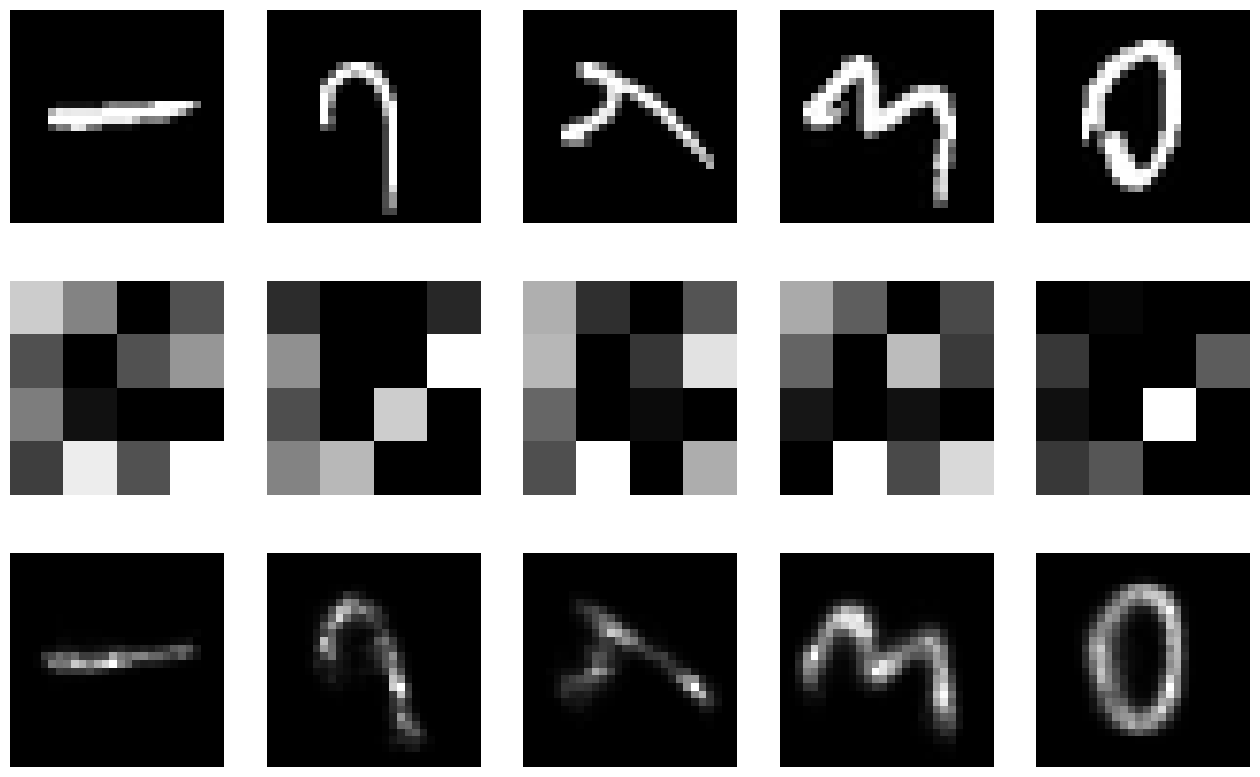

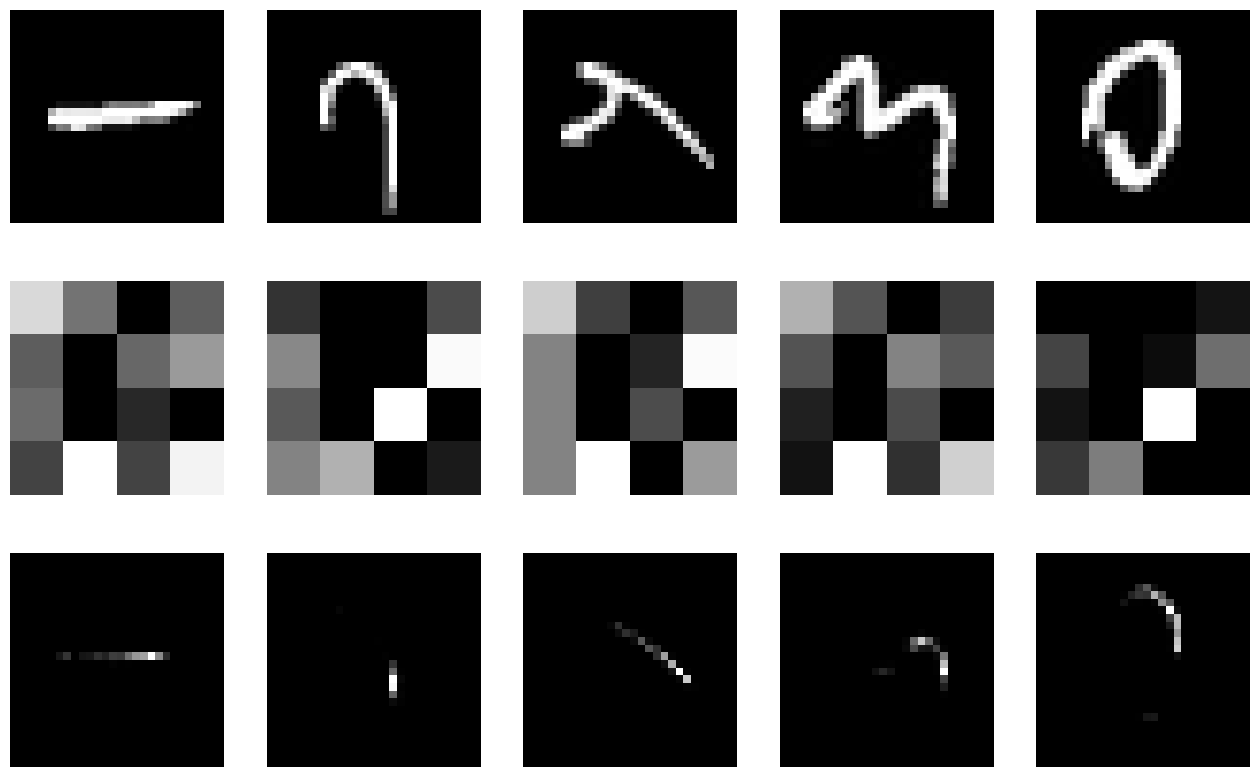

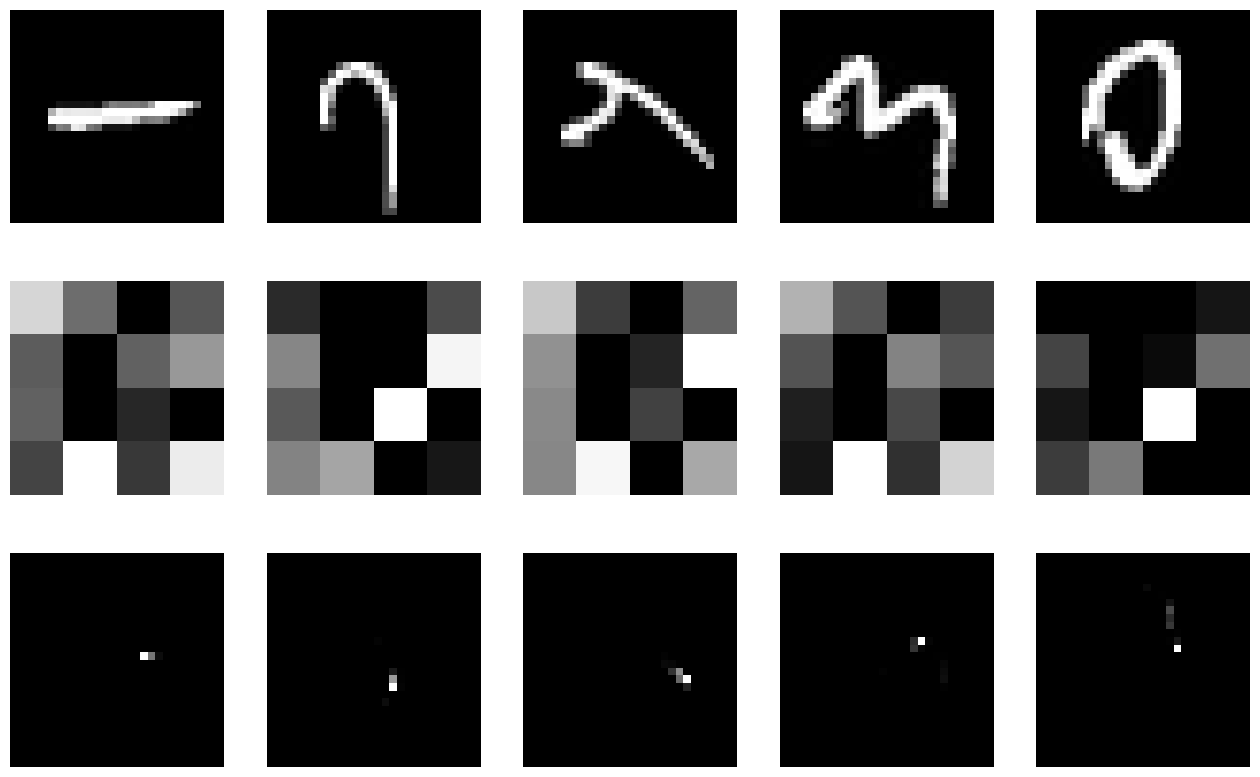

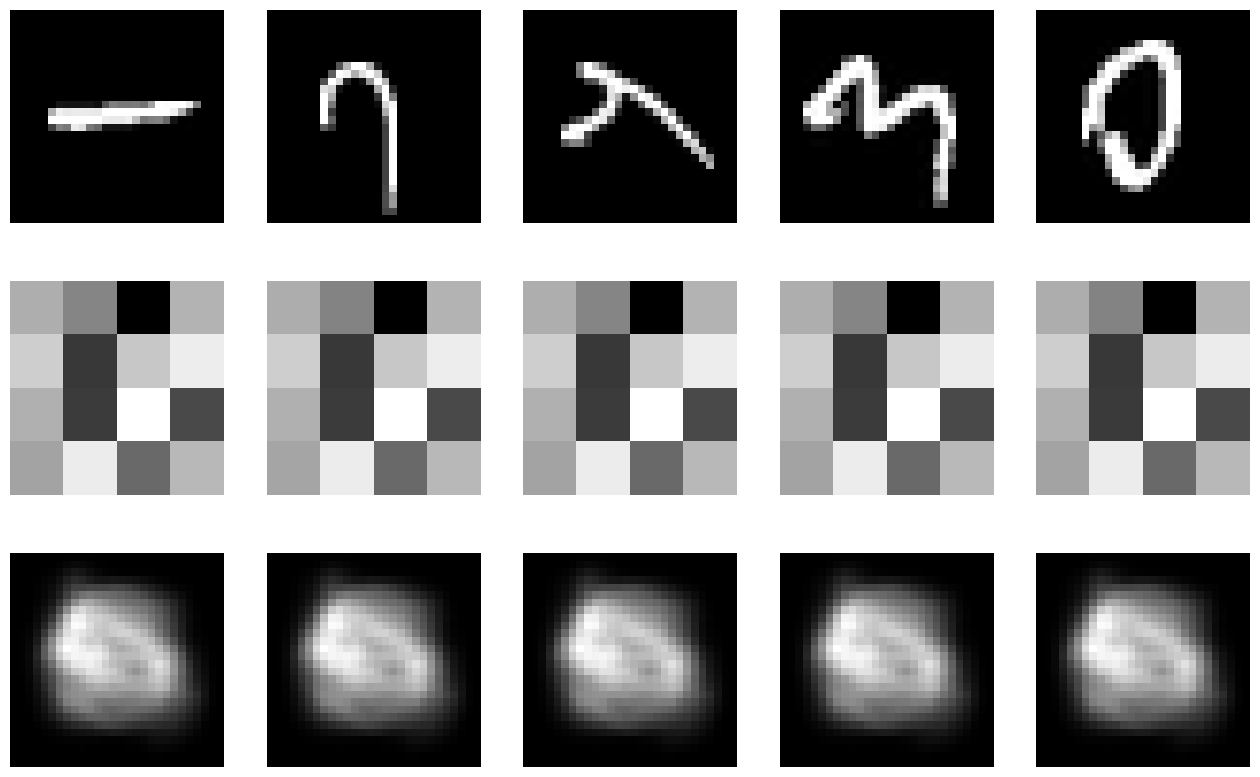

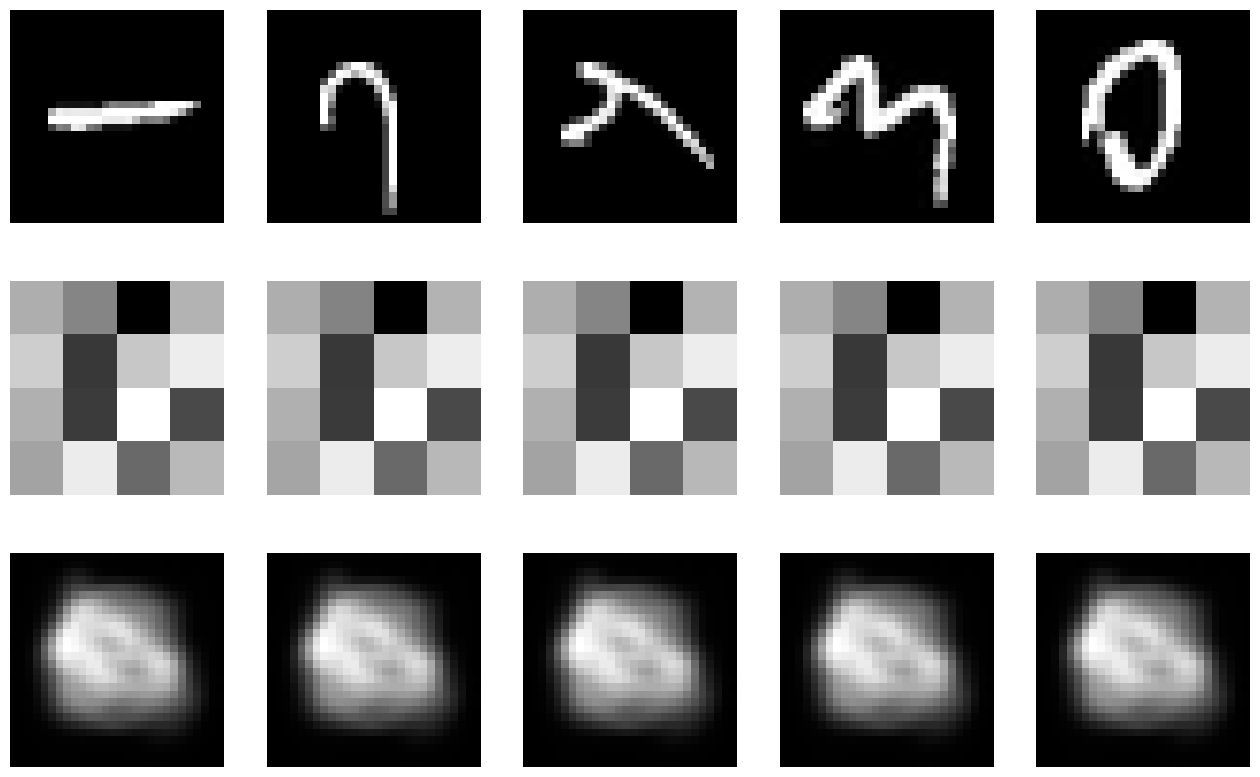

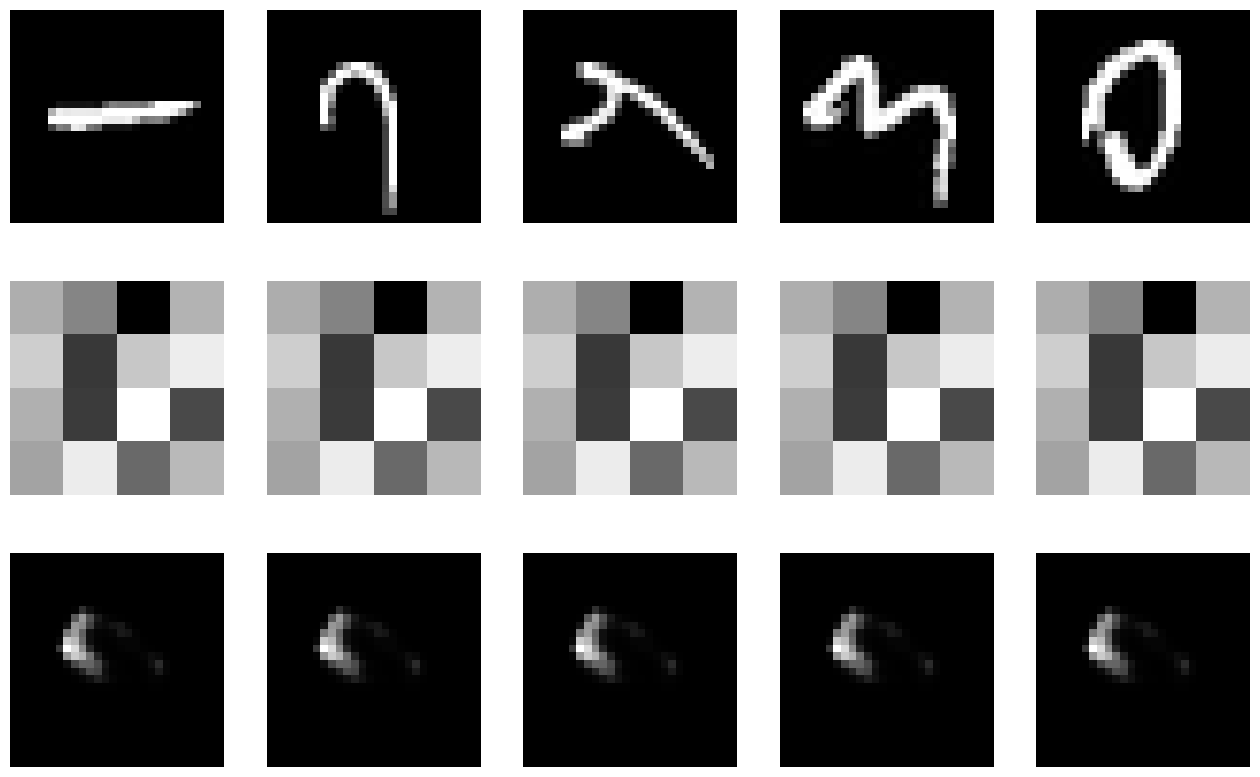

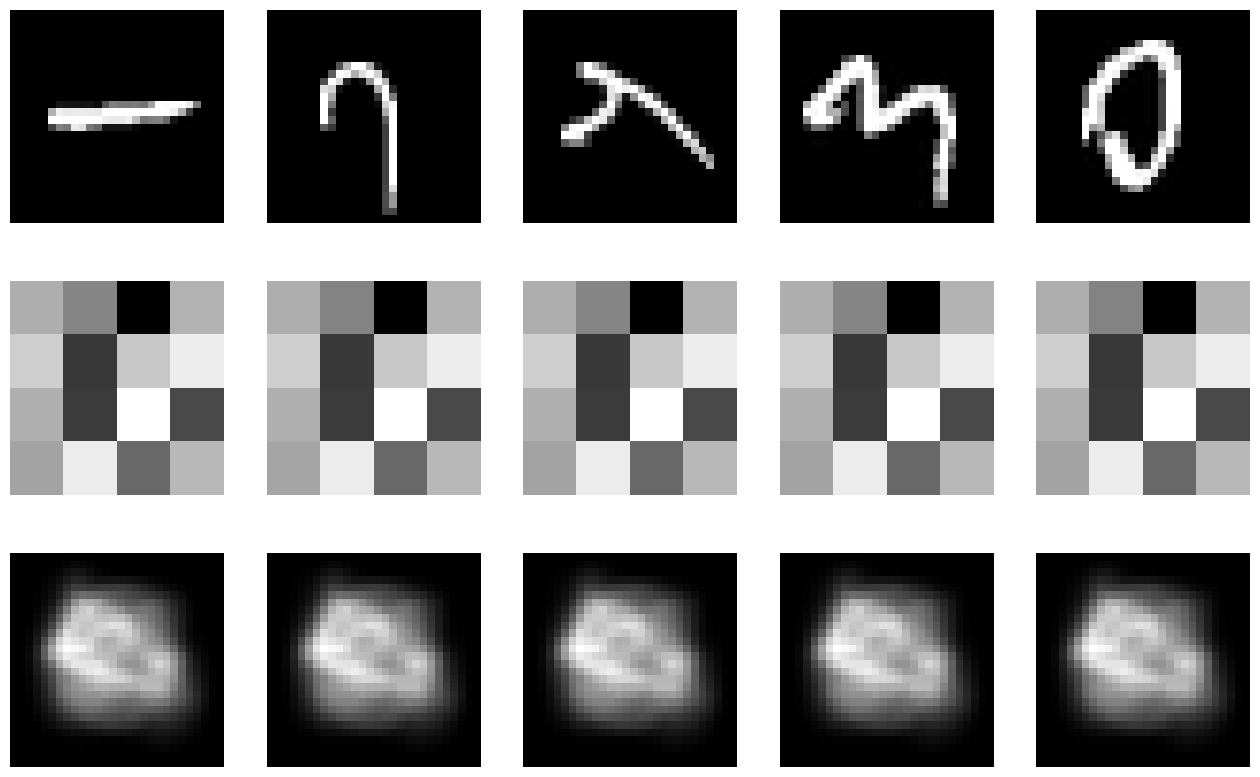

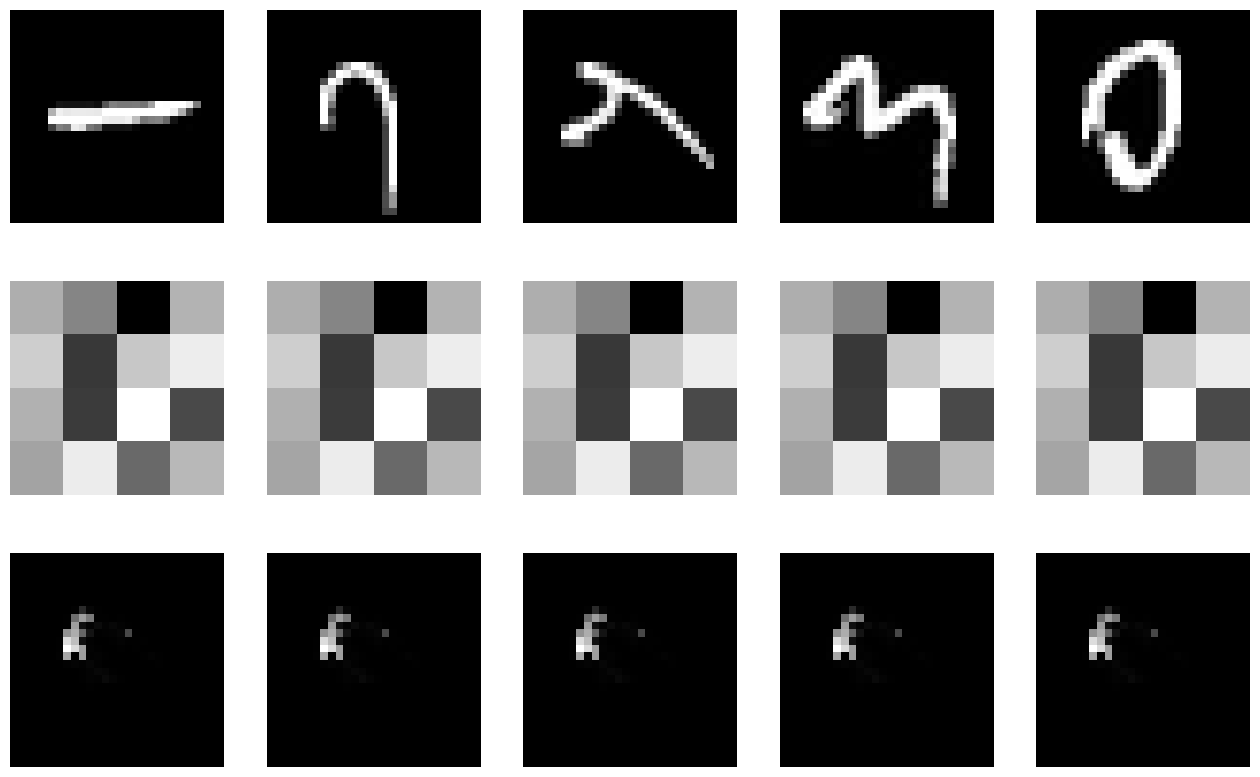

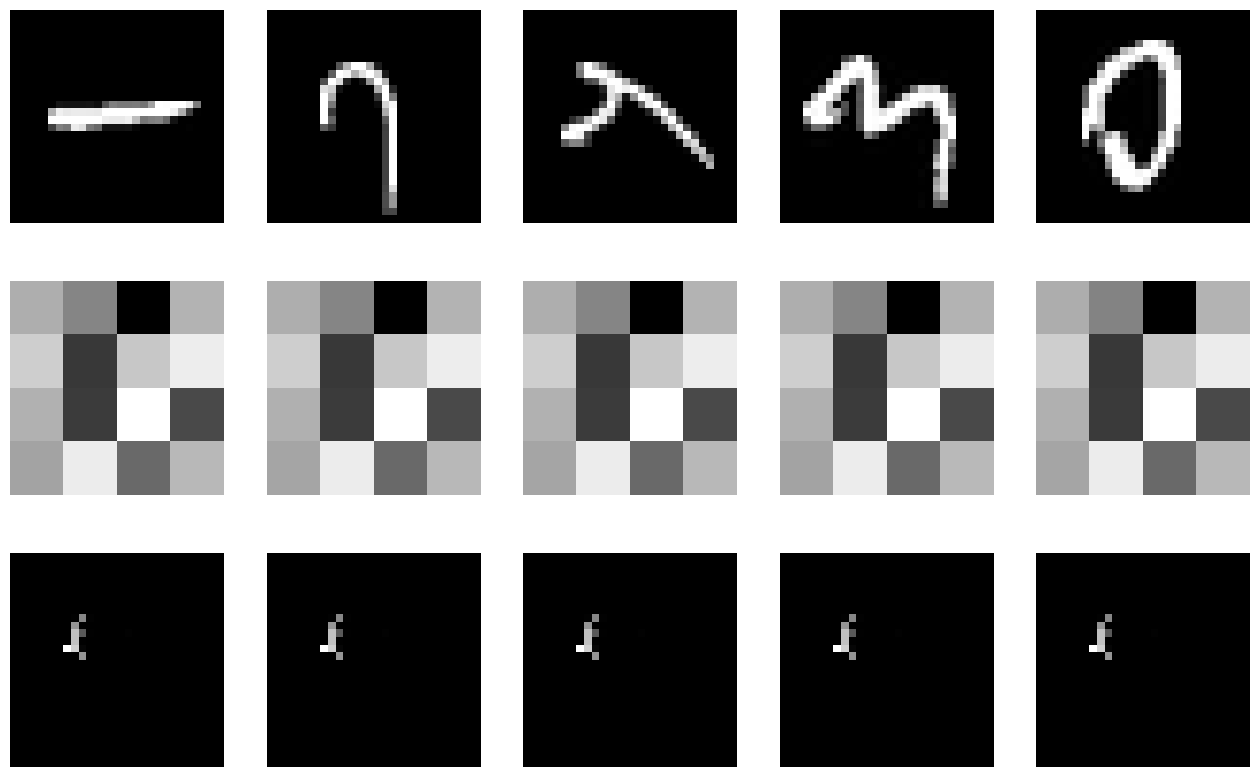

In [79]:
plot_images(img_data,autoencoders1)
df_encoded_pars1

We tested 12 autoencoder models using different combinations of hidden-layer activation functions, final-layer activation functions, and loss functions.  
The hidden-layer activation functions were RELU and Sigmoid. The final-layer activation functions were Sigmoid and Softmax. We also tested Binary Crossentropy, Mean Squared Error (MSE), and Mean Absolute Error (MAE) as the different loss functions.

### Autoencoder 0: ReLU / Sigmoid / Binary Cross-Entropy
This model combined ReLU in the hidden layers with a Sigmoid output layer and used Binary Cross-Entropy as its loss function.
Training loss fell from **0.3220** to **0.1164** over 50 epochs, and the test loss was **0.1256**. The loss stayed around 0.22–0.23 for the first few epochs, then began dropping steadily and was still decreasing at epoch 50. This was the only model trained from randomly initialized weights. In the plot, the decoded row reproduces the general shape and placement of each original digit, although the strokes are smoother and less defined. The encoded row shows each image reduced to a 4×4 grid of light and dark squares, which is a compressed summary rather than a picture of the digit. We accepted this model because the loss improved consistently, the test loss is close to the training loss, and the reconstructions are recognizable. ReLU limits the vanishing gradient problem, so the deeper layers can keep learning. Sigmoid outputs values between 0 and 1, matching our normalized pixels. Binary Cross-Entropy treats each pixel's brightness as a value between 0 and 1 and penalizes predictions that are far from it, which suits this type of image data.
 
### Autoencoder 1: ReLU / Sigmoid / Mean Squared Error
This model used ReLU for the hidden layers and Sigmoid for the output layer, with Mean Squared Error as the loss function.
Training loss decreased from **0.0196** to **0.0170** over 50 epochs and the test loss was **0.0210**. In the plot, the decoded digits keep the general outline and position of the originals, although the strokes are thicker and less sharp. The encoded row shows each image compressed into a 4×4 grid of shaded squares, and we accepted this model because the loss improved consistently and the reconstructions remain recognizable. MSE squares each pixel error, so large mistakes are penalized more than small ones, which pushes the model to get the overall digit shape right. The test loss is close to the final training loss, which suggests the model generalizes to images it did not see during training.
 
### Autoencoder 2: ReLU / Sigmoid / Mean Absolute Error
This model kept the ReLU hidden layers and Sigmoid output, but switched the loss function to Mean Absolute Error.
Over 50 epochs, training loss went down from **0.0469** to **0.0417**, with a test loss of **0.0487**. The decrease was gradual and had not levelled off by the final epoch, so more training may improve it further. In the plot, the reconstructed digits are still identifiable and sit in the same position as the originals, though fine details along the edges are a bit blurry. We accepted this model because it kept learning throughout training and produced readable reconstructions. Unlike MSE, MAE treats every pixel error equally, so it is less affected by a few very wrong pixels. This can lead to slightly blurrier strokes but more consistent results across the image.
 
### Autoencoder 3: ReLU / Softmax / Binary Cross-Entropy
This model used ReLU in the hidden layers, Softmax on the output layer, and Binary Cross-Entropy as the loss function.
Training loss only fell slightly, from **0.5138** to **0.5051**, and the test loss was **0.5271**. This is much higher than Autoencoder 0, which used the same loss function but a Sigmoid output (test loss **0.1256**). In the plot, an outline of each digit can still be seen in the decoded row, and the encoded row shows the 4×4 compressed grids. We accepted this model with reservations, because its reconstructions keep the basic digit shapes and its loss did not get worse. However, Softmax makes all 784 output pixels add up to 1, so each pixel ends up with a very small value instead of a true brightness between 0 and 1. The digits look clearer in the plot than they really are because `imshow` automatically stretches each image's brightness range. This makes Softmax a weaker choice than Sigmoid for rebuilding images.

### Rejected Autoencoders
After comparing the original and reconstructed images, we found that Autoencoders 4 through 11 did not perform well.  

**Models 4:**
- These models used RELU in the hidden layers and Softmax in the final layer. The reconstructed images were almost completely black, with only a few faint white lines and small bright spots visible. Some of these lines slightly resembled parts of the original handwritten digits, but most of the original shapes were missing. The lines were also very thin and difficult to see compared to the originals. We rejected these models because they failed to reconstruct complete and recognizable handwritten digits using our model architecture and training.  

**Models 6, 7, and 9**
- These models used Sigmoid for both the hidden layers and the final layer. Model 6 used Binary Crossentropy as the loss function while Model 7 used MSE. Model 9 also had sigmoid in the hidden layer but used softmax as the final layers activation function. like Model 6, it used Binary Crossentropy as the loss function. The reconstructed images produced by these models were very blurry, and some looked like bright, cloudy shapes instead of handwritten digits. The original lines and curves were difficult to see. Another problem was that several reconstructed images looked almost identical, even though the original digits were different. This showed that the models were not preserving enough information to distinguish between the digits. We rejected these models because they produced blurry and similar-looking images rather than clear reconstructions of each original digit.

**Models 8, 10, and 11**
- These models used Sigmoid in the hidden layers. Model 8 used Sigmoid in the final layer with Mean Absolute Error (MAE), while Models 10 and 11 used Softmax in the final layer with Mean Squared Error (MSE) and Mean Absolute Error (MAE), respectively. The reconstructed images were almost completely black, with only a small cluster of white pixels visible. Model 8 produced a more detailed cluster with faint white pixels, Model 10 showed a more concentrated group of bright pixels, and Model 11 produced only a few tiny white marks. These 3 encoders' reconstructions looked like lower resolution images of each others. Another problem was that the reconstructed images looked almost identical, even though the original images contained different handwritten digits. The original lines, curves, and shapes were missing, making it impossible to identify the digits from the reconstructed images. We rejected these models because they failed to preserve the important features of the original images. The results showed that these combinations of activation functions and loss functions did not work well with our autoencoder architecture.
 

### Overall Results
For the initial set of hyperparameter, we tested the differences that occured from changing the hidden layer's activation function, the final layer's activation function, and the loss function. These were tested with ***Adadelta*** as the optimizer. Now that we've narrowed down our model selection to 3 sets of activation functions that resulted in viable image reconstructions, we will be testing these with different optimizers to determine the best possible autoencoder.

In [80]:
for key in range(4,12):
    if key in autoencoders1:
        autoencoders1.pop(key)
        df_encoded_pars1.drop(key,inplace=True)
df_encoded_pars1

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.137855,binary_crossentropy,adadelta
1,50,sigmoid,relu,0.0226843,mean_squared_error,adadelta
2,50,sigmoid,relu,0.0509161,mean_absolute_error,adadelta
3,50,softmax,relu,0.5302,binary_crossentropy,adadelta


## Iteration 2

For this Iteration, we will be testing and comparing the best models from iteration 1 using the different Optimizers.  
After compiling the models with Optimizers **Adam** and **Adagrad**, we will then compare the results with Iteration 1's best encoders to continue testing.

In [ ]:
activation_function = ["relu"]
activation_final = ["sigmoid","softmax"]
loss_functions = ["binary_crossentropy","mean_squared_error","mean_absolute_error"]
optimizer = ["adam","adagrad"]
autoencoders2 = dict()
i = 0
for act in activation_function:
    for act_fnl in activation_final:
        for loss in loss_functions:
            for opti in optimizer:
                if act_fnl == "softmax" and loss != "binary_crossentropy":
                    continue
                autoencoders2[i] = create_autoencoder(img_data,act,act_fnl,loss,opti)
                i += 1
df_encoded_pars2 = pd.DataFrame(autoencoders2).transpose().drop(columns=["decoded","encoded"])

Epoch 1/50
8998/8998 [==============================] - 19s 2ms/step - loss: 0.2367
Epoch 2/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1934
Epoch 3/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1710
Epoch 4/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1532
Epoch 5/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1395
Epoch 6/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1317
Epoch 7/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1266
Epoch 8/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1228
Epoch 9/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1198
Epoch 10/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1174
Epoch 11/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1154
Epoch 12/50
8998/8998 [==============================] - 14s 2ms/step - lo

In [82]:
df_encoded_pars2

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.104627,binary_crossentropy,adam
1,50,sigmoid,relu,0.107018,binary_crossentropy,adagrad
2,50,sigmoid,relu,0.0175399,mean_squared_error,adam
3,50,sigmoid,relu,0.0168356,mean_squared_error,adagrad
4,50,sigmoid,relu,0.0397032,mean_absolute_error,adam
5,50,sigmoid,relu,0.0375938,mean_absolute_error,adagrad
6,50,softmax,relu,0.51745,binary_crossentropy,adam
7,50,softmax,relu,0.515706,binary_crossentropy,adagrad


As there are a lot of viable models, we want to test how epoch count will affect the reconstructions. As such we will be taking the best version of each model (final activation, hidden activation, loss function) and testing them with higher epoch values. This is to ensure our model performs best regardless of train time.

In [83]:
softmax_pars = {
    f"Iter 1.{model_num}": model
    for model_num, model in autoencoders1.items() if model["Final Activation"]=="softmax"    
}
softmax_pars.update({
    f"Iter 2.{model_num}": model
    for model_num, model in autoencoders2.items() if model["Final Activation"]=="softmax"    
})
df_softmax = pd.DataFrame(softmax_pars).transpose().drop(columns=["decoded","encoded"])

sigmoid_pars = {
    f"Iter 1.{model_num}": model
    for model_num, model in autoencoders1.items() if model["Final Activation"]=="sigmoid"    
}
sigmoid_pars.update({
    f"Iter 2.{model_num}": model
    for model_num, model in autoencoders2.items() if (model["Final Activation"]=="sigmoid" and model["Optimizer"]=="adagrad")
})
sigmoid_pars.update({
    f"Iter 2.{model_num}": model
    for model_num, model in autoencoders2.items() if (model["Final Activation"]=="sigmoid" and model["Optimizer"]=="adam")
})
df_sigmoid = pd.DataFrame(sigmoid_pars).transpose().drop(columns=["decoded","encoded"])

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
Iter 1.3,50,softmax,relu,0.5302,binary_crossentropy,adadelta
Iter 2.6,50,softmax,relu,0.51745,binary_crossentropy,adam
Iter 2.7,50,softmax,relu,0.515706,binary_crossentropy,adagrad


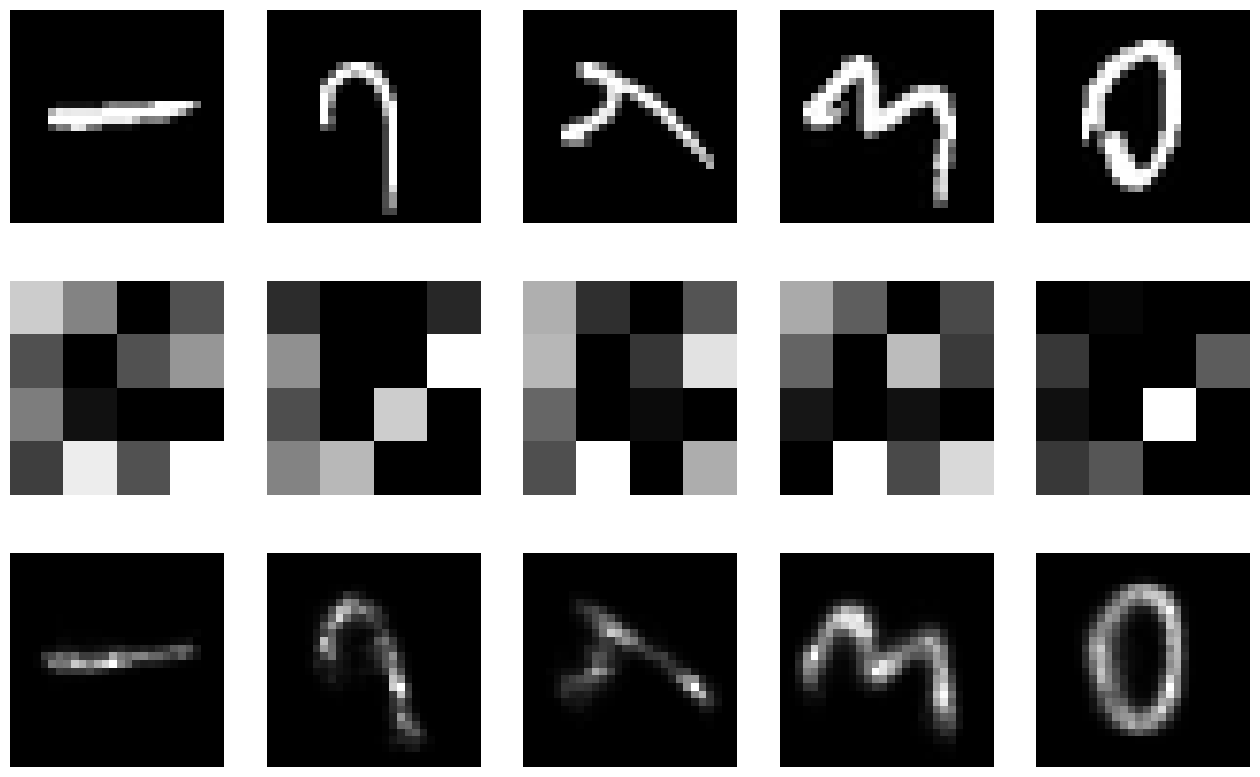

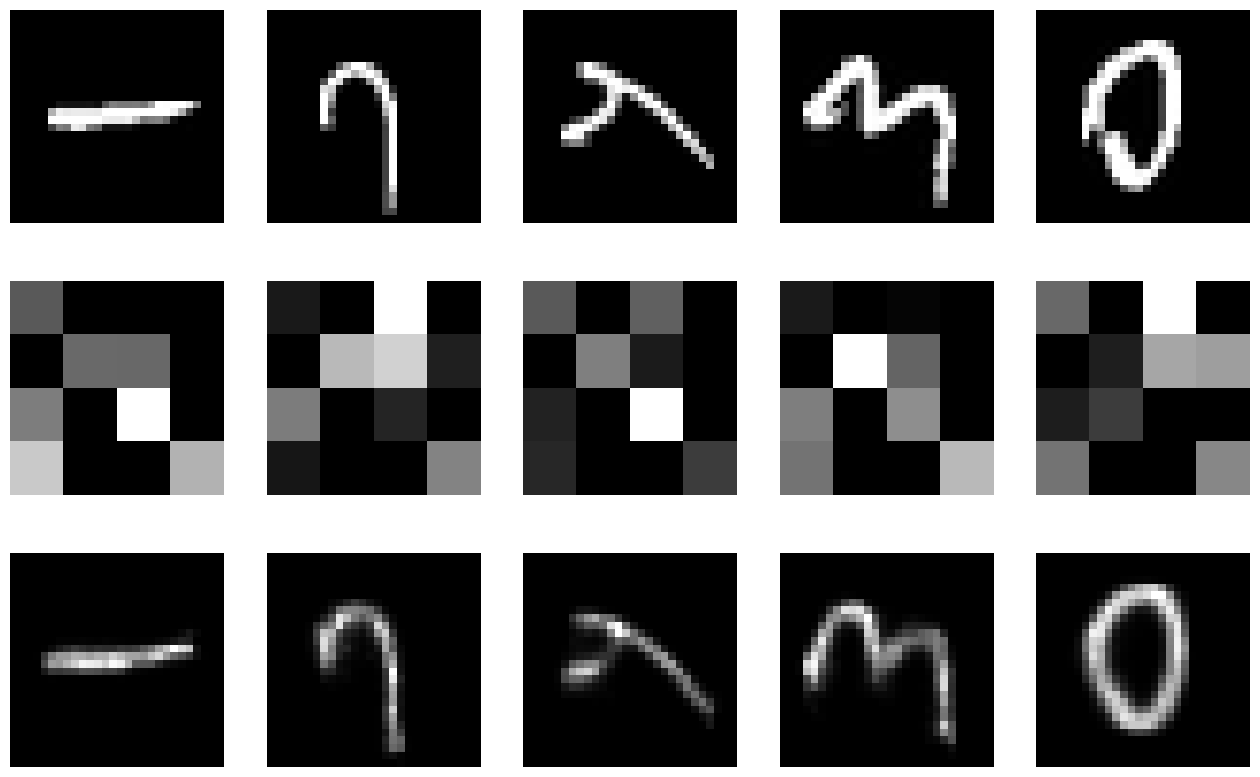

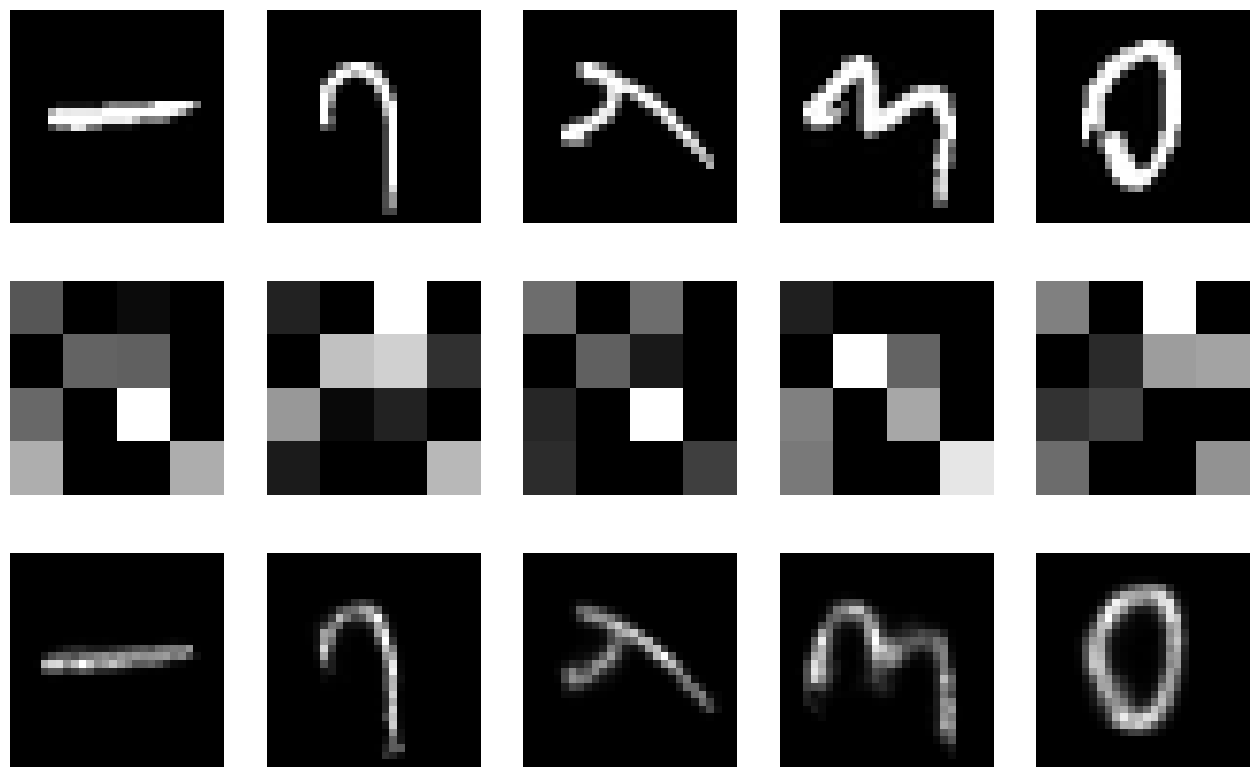

In [84]:
plot_images(img_data,softmax_pars)
df_softmax

For the combination of **Softmax** and **ReLu**, the Optimizers that performed the best were **Adagrad** and **Adam**. Although the model using **Adagrad** better reconstructs the white pixels, we will be proceeding with both versions into the next Iteration to test whether training time will affect these results.

For the **Sigmoid** and **ReLu** encoders, we will chose the best versions of each optimizer separately to test in the next Iteration. This will allow us to test which hyperparameters are best and how varying epochs affects our image reconstructions. From this new selection, we will select a final model that produces the best reconstructions given the current neural network architecture.

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
Iter 1.0,50,sigmoid,relu,0.137855,binary_crossentropy,adadelta
Iter 1.1,50,sigmoid,relu,0.0226843,mean_squared_error,adadelta
Iter 1.2,50,sigmoid,relu,0.0509161,mean_absolute_error,adadelta


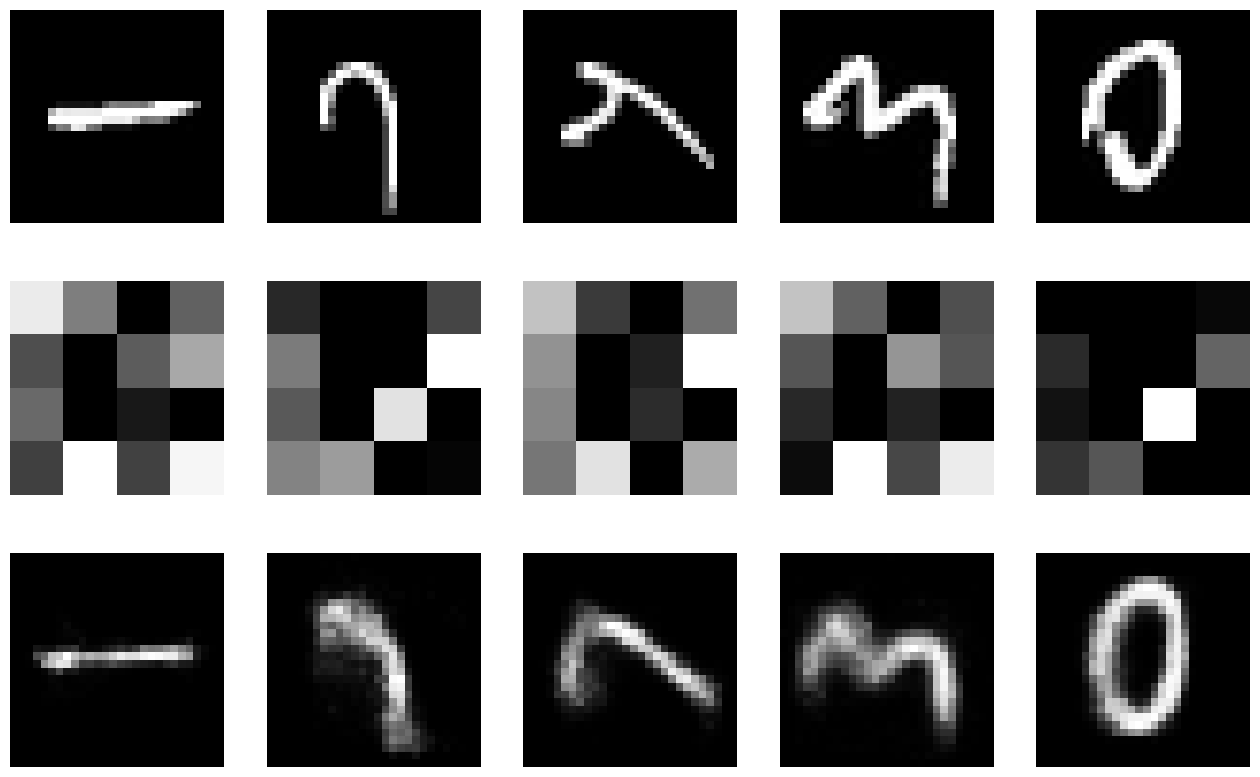

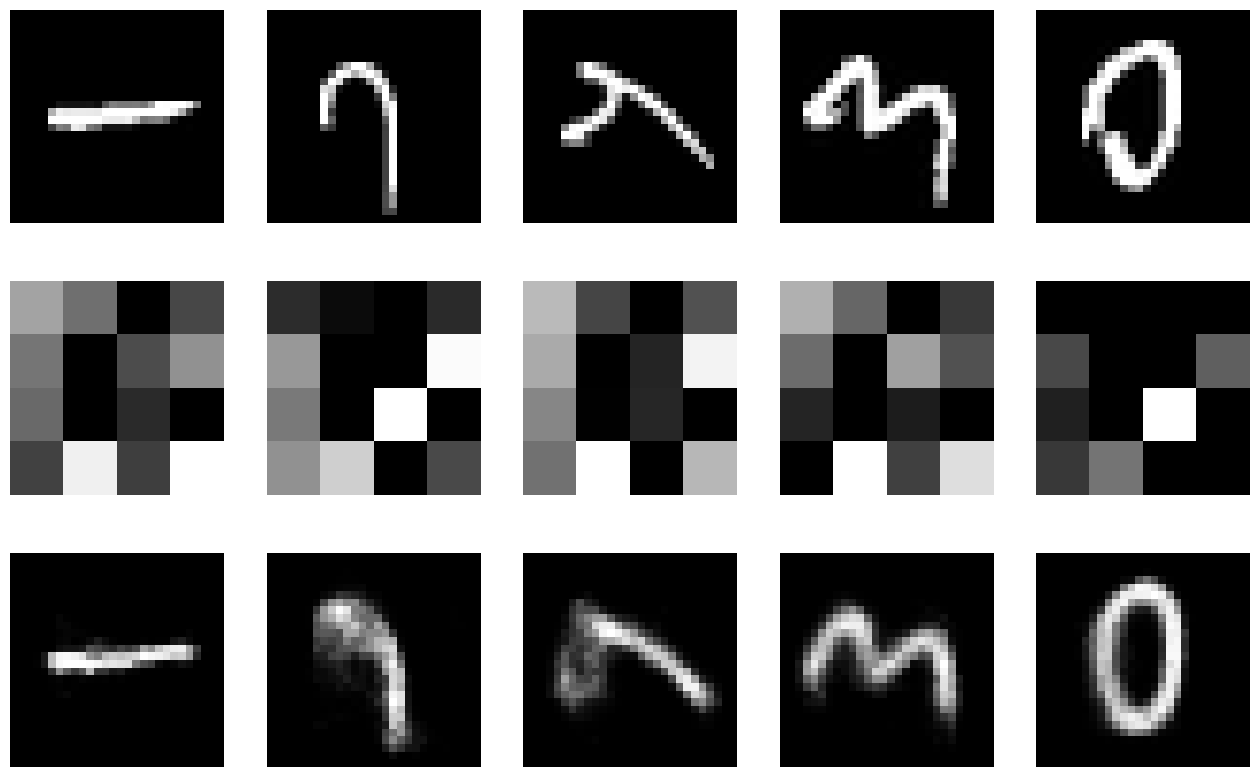

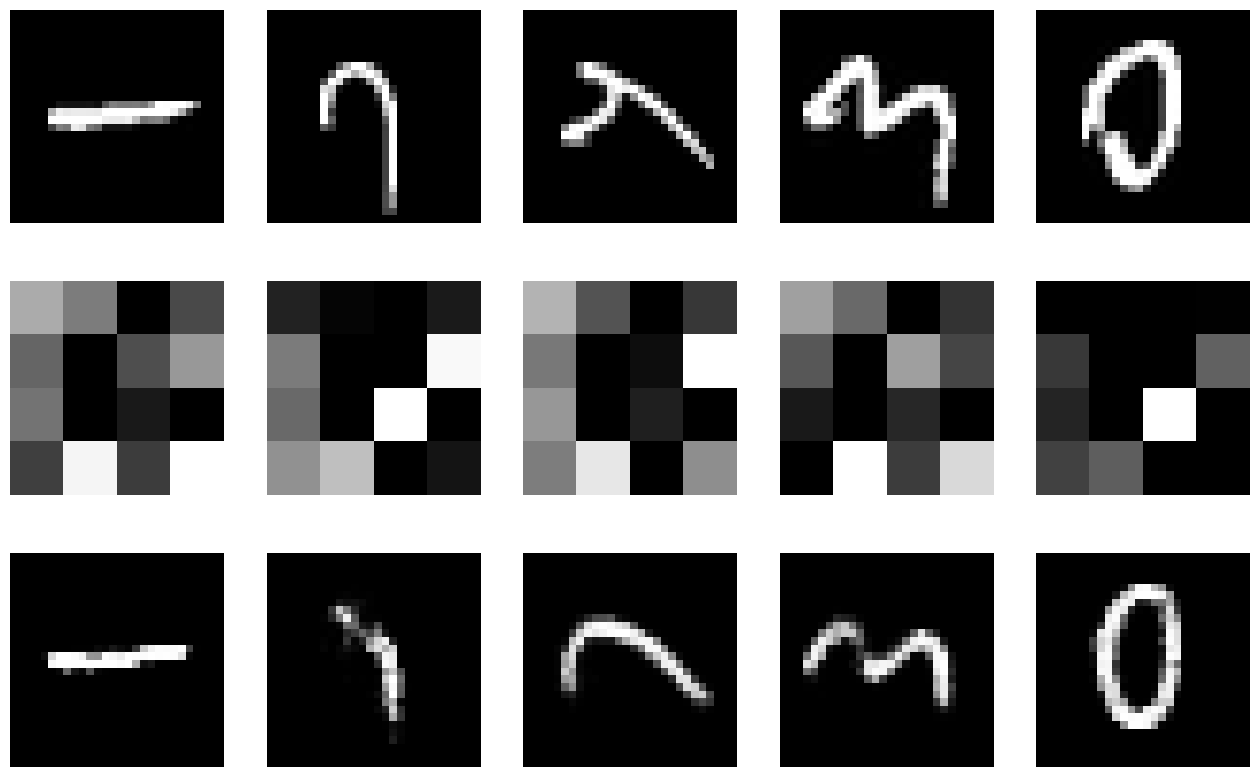

In [85]:
plot_images(img_data,dict(list(sigmoid_pars.items())[0:3]))
df_sigmoid[df_sigmoid["Optimizer"]=="adadelta"]

From the **Sigmoid/ReLu** models using the **Adadelta** Optimizer, we selected to proceed with the encoder that used **MSE** for the loss function (*Image 2*). Although none of these versions produced viable reconstructions, we wanted to ensure that this wasn't due to a lack of training time. As such when moving to Iteration 3 where we test varying epochs, we will be including the parameters from Iteration 1.1, which best captured the overall shape compared to the other **Sigmoid/ReLu/Adadelta** models.

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
Iter 2.1,50,sigmoid,relu,0.107018,binary_crossentropy,adagrad
Iter 2.3,50,sigmoid,relu,0.0168356,mean_squared_error,adagrad
Iter 2.5,50,sigmoid,relu,0.0375938,mean_absolute_error,adagrad


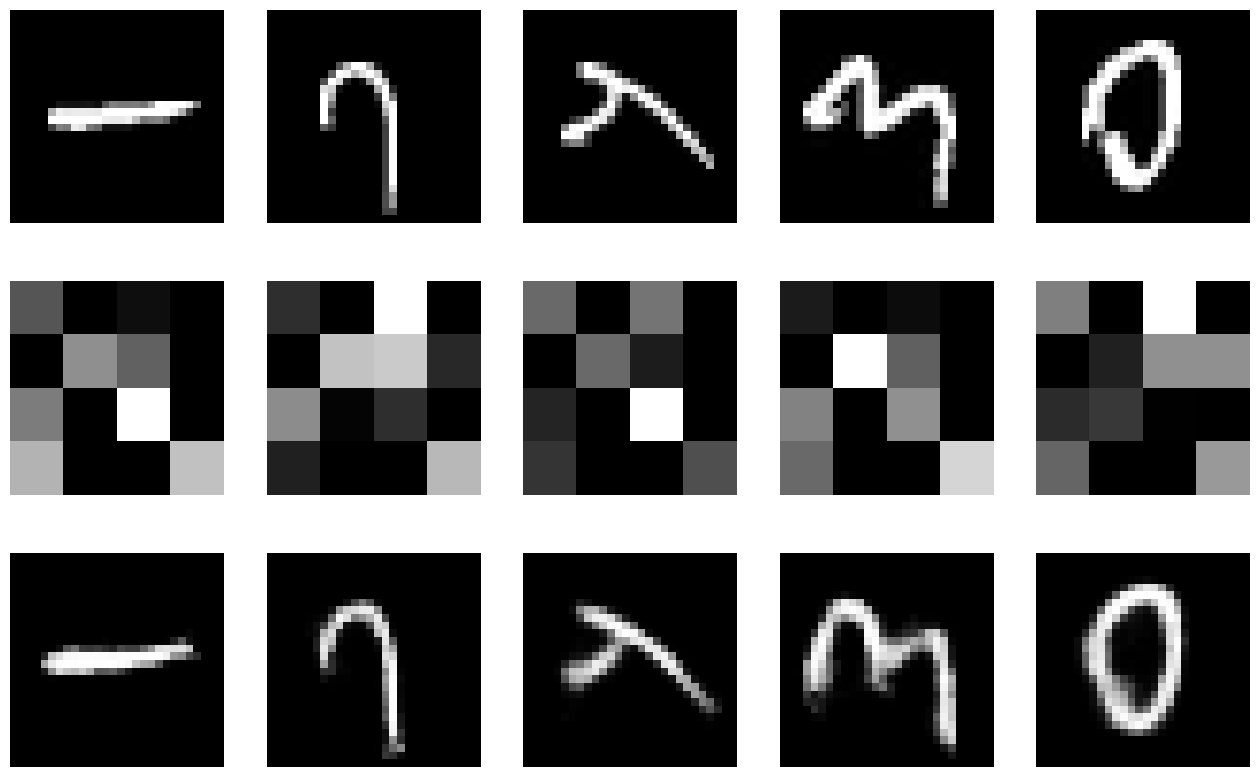

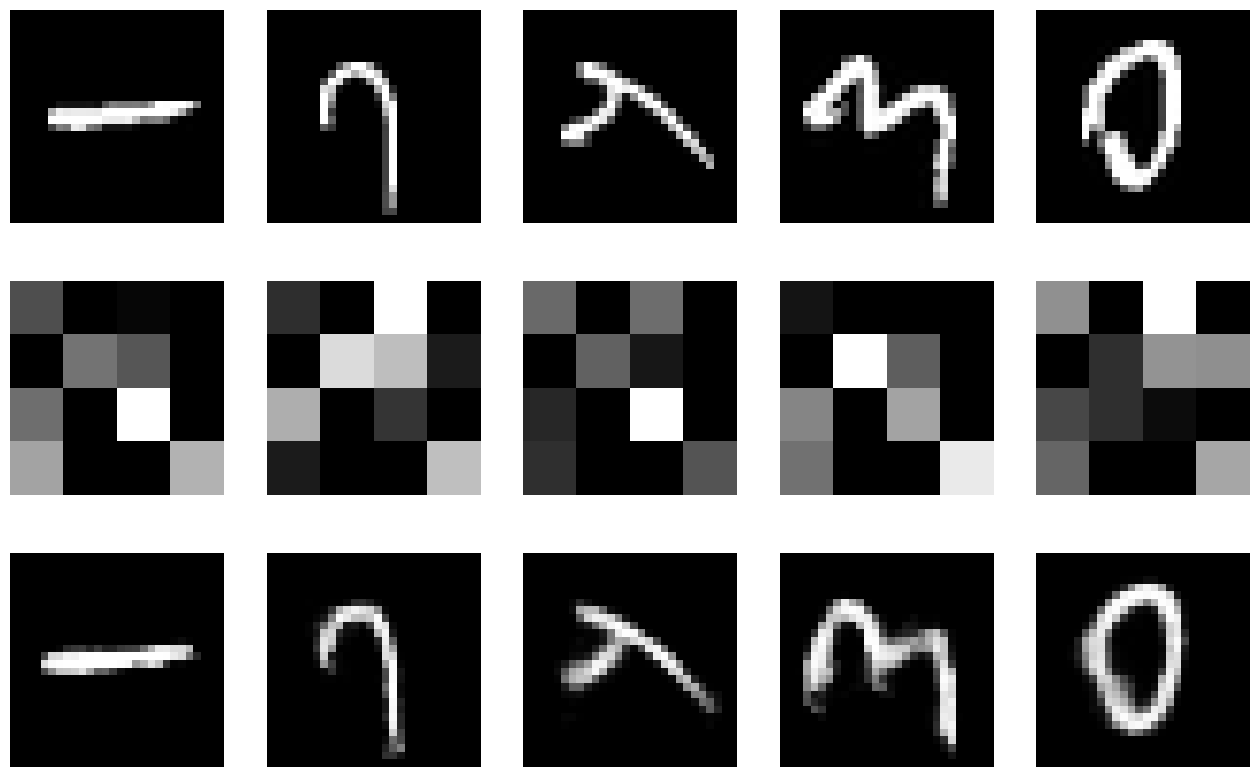

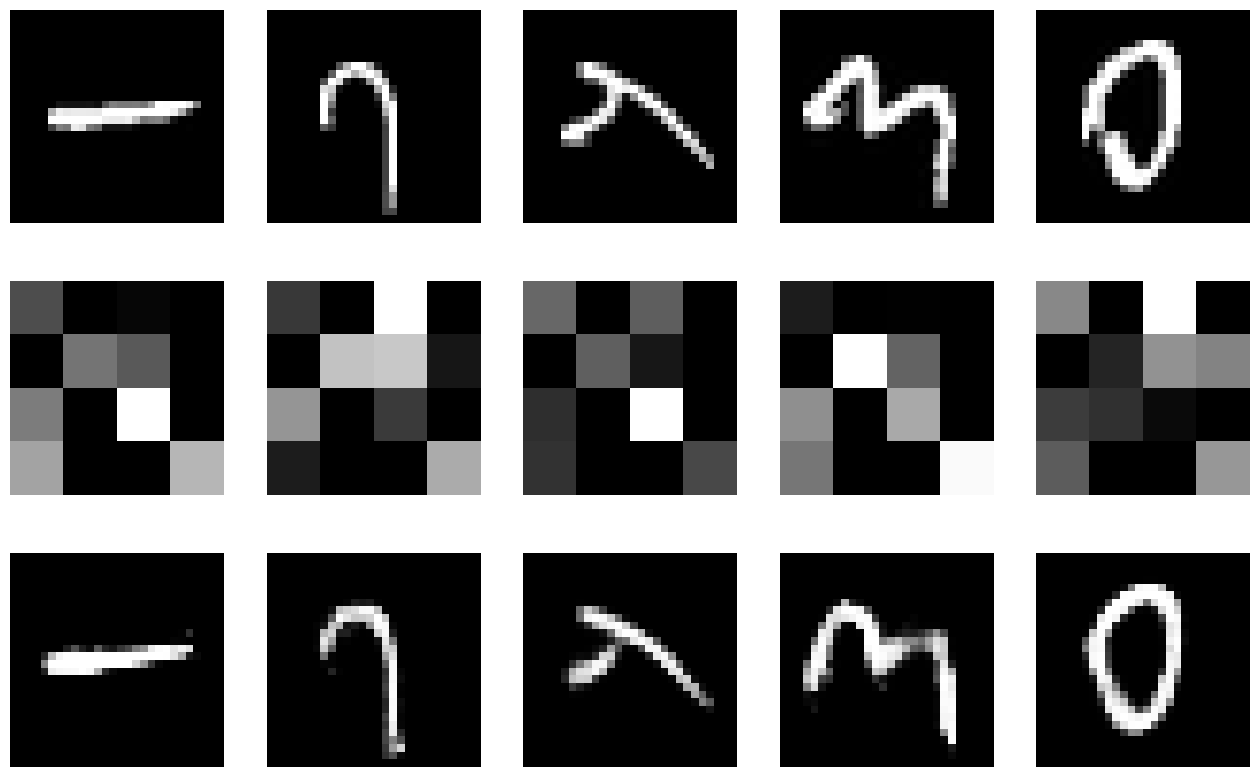

In [86]:
plot_images(img_data,dict(list(sigmoid_pars.items())[3:6]))
df_sigmoid[df_sigmoid["Optimizer"]=="adagrad"]

The above batch of encoders tested **Sigmoid/ReLu/Adagrad** with the loss functions **Binary Crossentropy**, **MSE**, and **MAE**. Since these combinations produced the best results under 50 epochs out of all encoders we tested, we decided to continue with the best 2 versions to test how epoch variation affected the reconstruction capabilities. These ended up being Iteration 2.1 and 2.3. Although the last encoder that used **MAE** also produced great reconstructions, the second image in particular appeared to be missing some pixel data. For these reasons in the next iteration we will be selecting Iterations 2.1 and 2.3 from the **Adagrad** batch of **Sigmoid** encoders.

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
Iter 2.0,50,sigmoid,relu,0.104627,binary_crossentropy,adam
Iter 2.2,50,sigmoid,relu,0.0175399,mean_squared_error,adam
Iter 2.4,50,sigmoid,relu,0.0397032,mean_absolute_error,adam


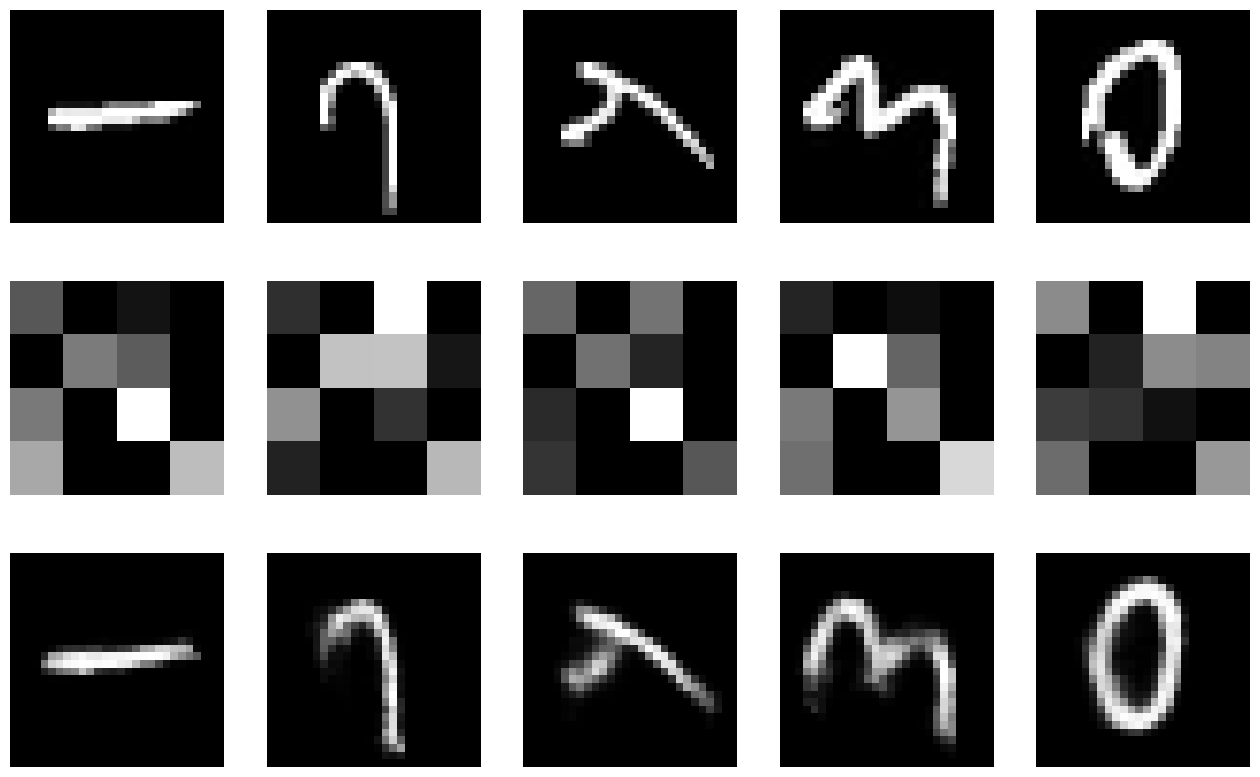

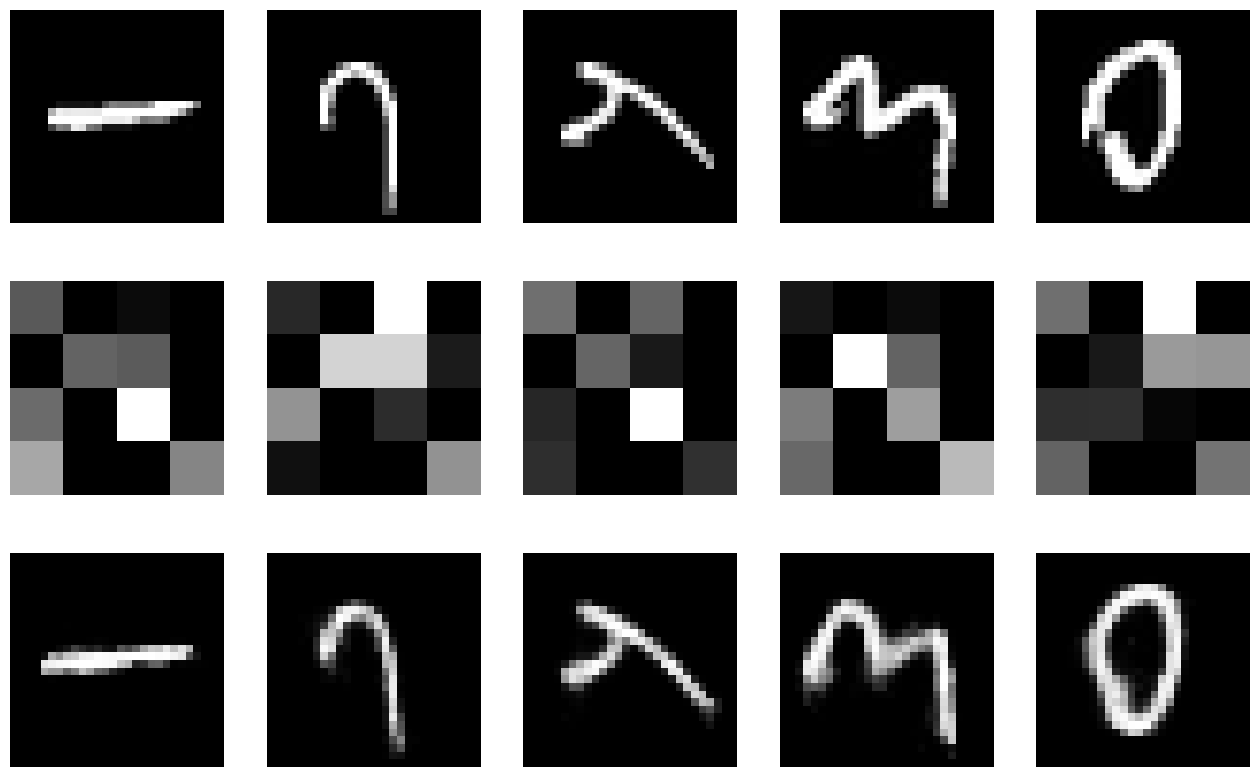

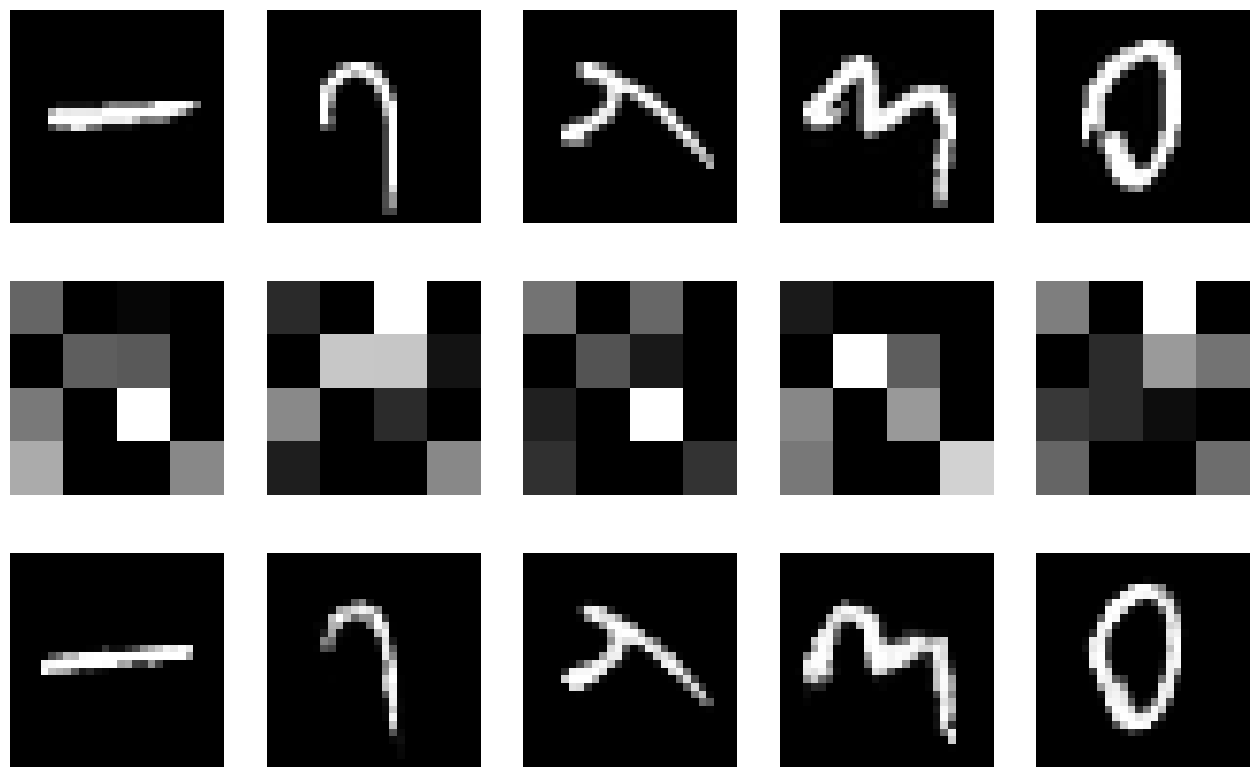

In [87]:
plot_images(img_data,dict(list(sigmoid_pars.items())[6:9]))
df_sigmoid[df_sigmoid["Optimizer"]=="adam"]

This batch of models was trained using **Sigmoid** as the final activation function, **ReLu** in the hidden layers, and **Adam** for the optimizer. For the loss functions, we tested **Binary Crossentropy**, **MSE**, and **MAE**. From this group, the model using **Binary Crossentropy** produced reconstructed imgaes that appeared blurry and washed out. Both **MSE** and **MAE** versions resulted in clear, vibrant reconstructions, however the **MSE** model had slightly better defined shapes. For this reason we will be continuing with only the **MSE** version from this batch in Iteration 3.

## Iteration 3

In [90]:
activation_function = ["relu"]
activation_final = ["sigmoid","softmax"]
loss_functions = ["binary_crossentropy","mean_squared_error"]
optimizer = ["adadelta","adagrad","adam"]
epochs = [50,100,150]
autoencoders3 = dict()
i = 0
for act in activation_function:
    for act_fnl in activation_final:
        for loss in loss_functions:
            for opti in optimizer:
                for epoch in epochs:
                    if act_fnl == "softmax" and (loss != "binary_crossentropy" or opti == "adadelta"):
                        continue
                    elif act_fnl == "sigmoid" and opti != "adagrad" and loss == "binary_crossentropy":
                        continue
                    autoencoders3[i] = create_autoencoder(img_data,act,act_fnl,loss,opti,epochs=epoch)
                    i += 1
df_encoded_pars3 = pd.DataFrame(autoencoders3).transpose().drop(columns=["decoded","encoded"])

Epoch 1/50
8998/8998 [==============================] - 15s 2ms/step - loss: 0.2610
Epoch 2/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1822
Epoch 3/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1670
Epoch 4/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1592
Epoch 5/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1511
Epoch 6/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1450
Epoch 7/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1406
Epoch 8/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1369
Epoch 9/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1329
Epoch 10/50
8998/8998 [==============================] - 14s 2ms/step - loss: 0.1299
Epoch 11/50
8998/8998 [==============================] - 13s 1ms/step - loss: 0.1269
Epoch 12/50
8998/8998 [==============================] - 14s 2ms/step - lo

In [91]:
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.104482,binary_crossentropy,adagrad
1,100,sigmoid,relu,0.0977855,binary_crossentropy,adagrad
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
3,50,sigmoid,relu,0.0167825,mean_squared_error,adadelta
4,100,sigmoid,relu,0.0171126,mean_squared_error,adadelta
5,150,sigmoid,relu,0.0158725,mean_squared_error,adadelta
6,50,sigmoid,relu,0.0144542,mean_squared_error,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam


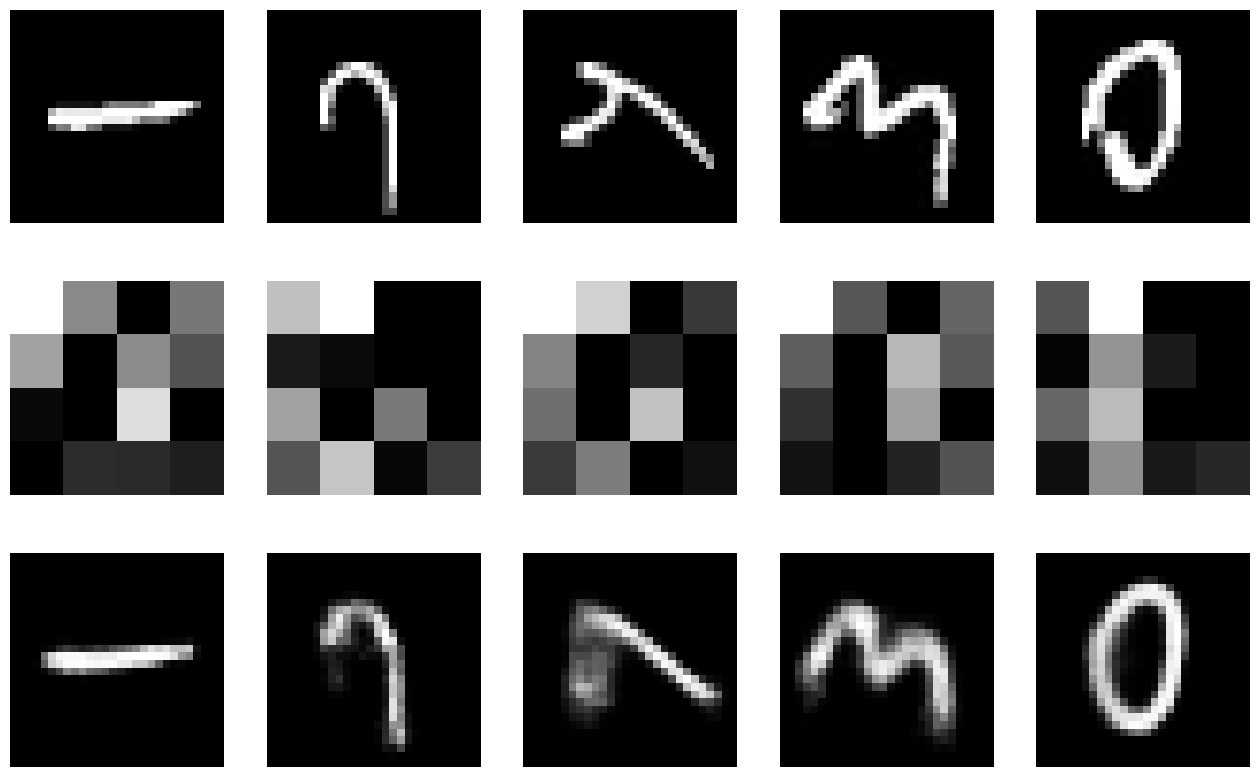

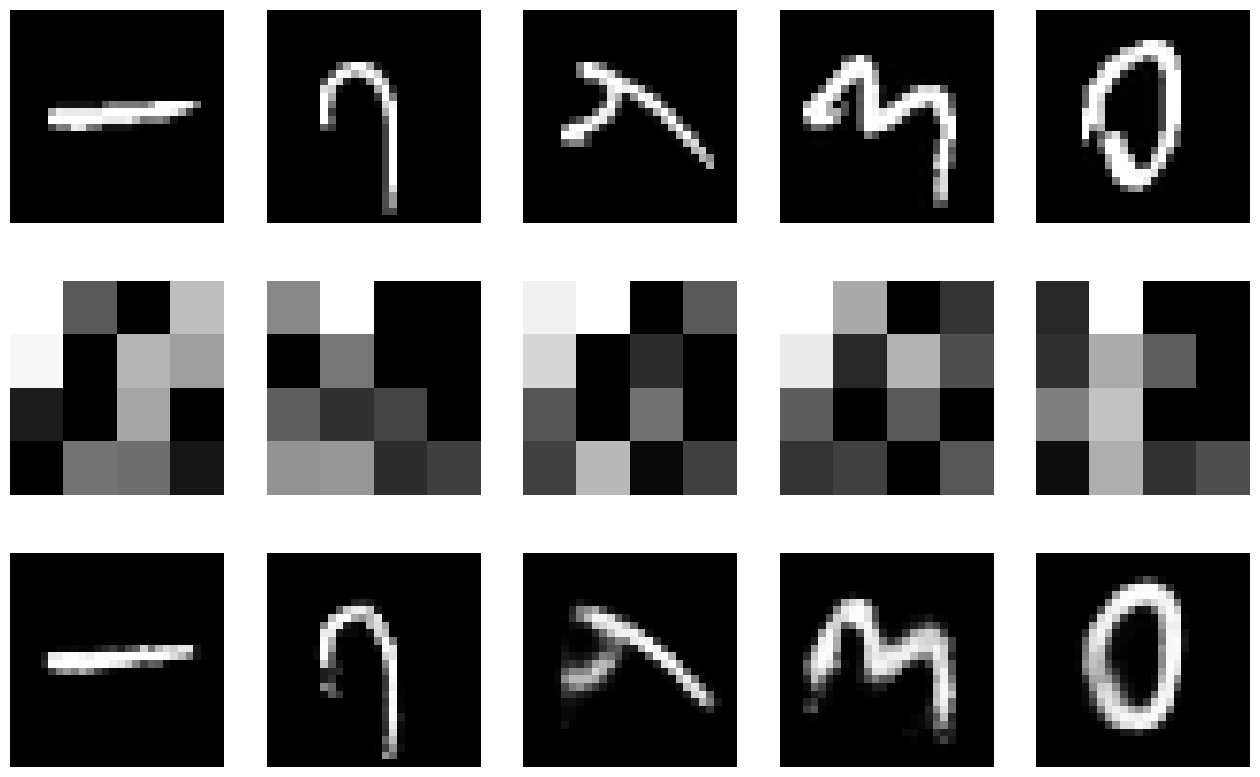

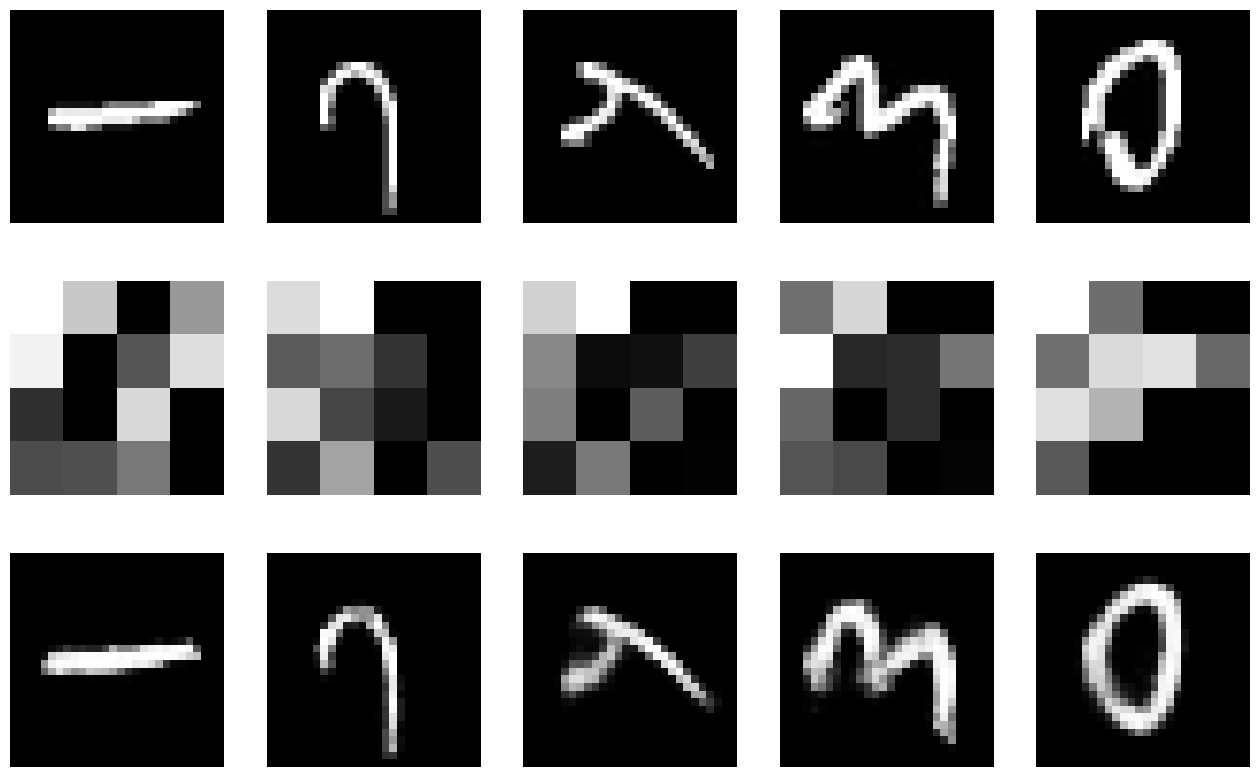

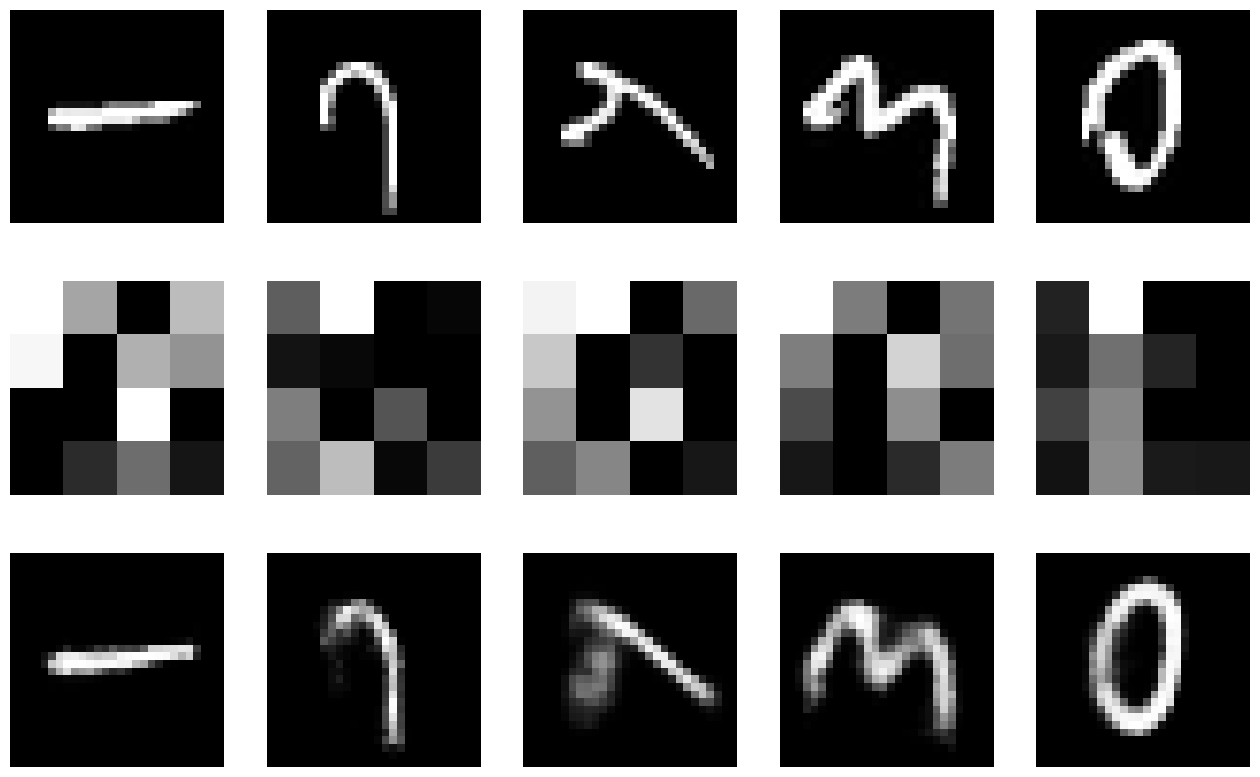

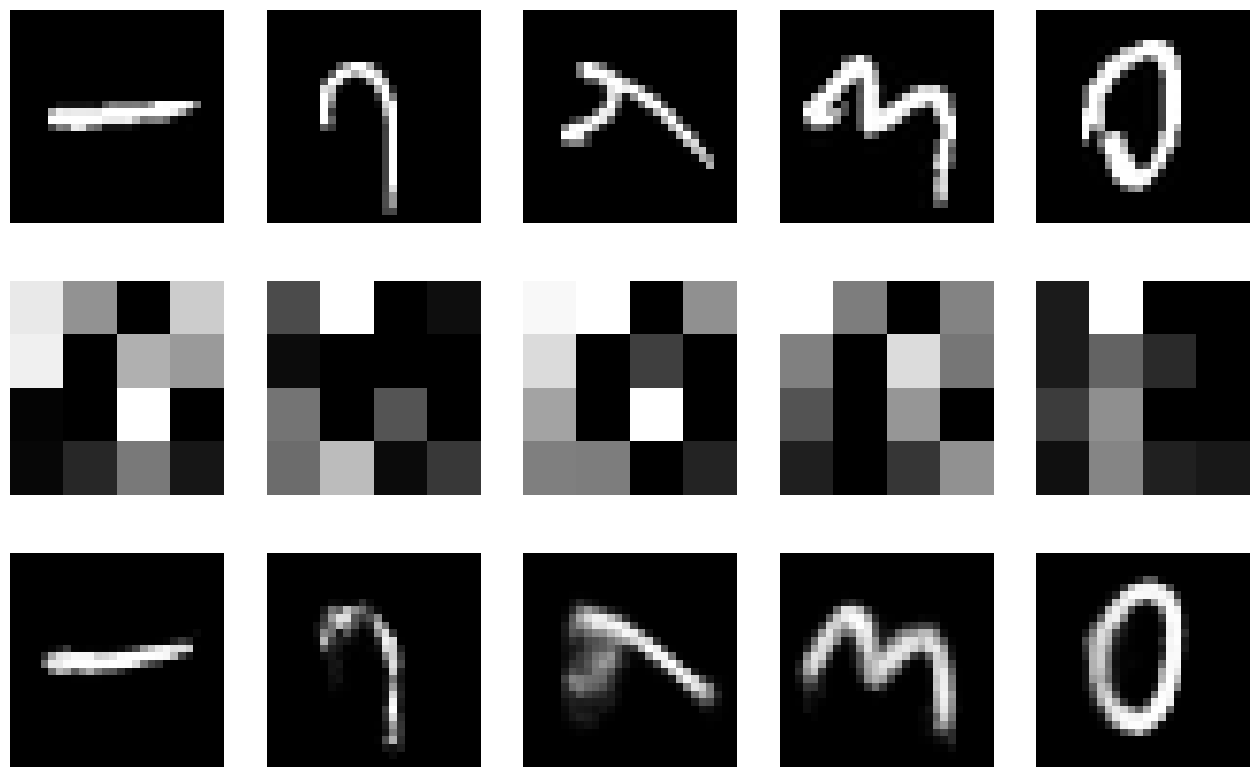

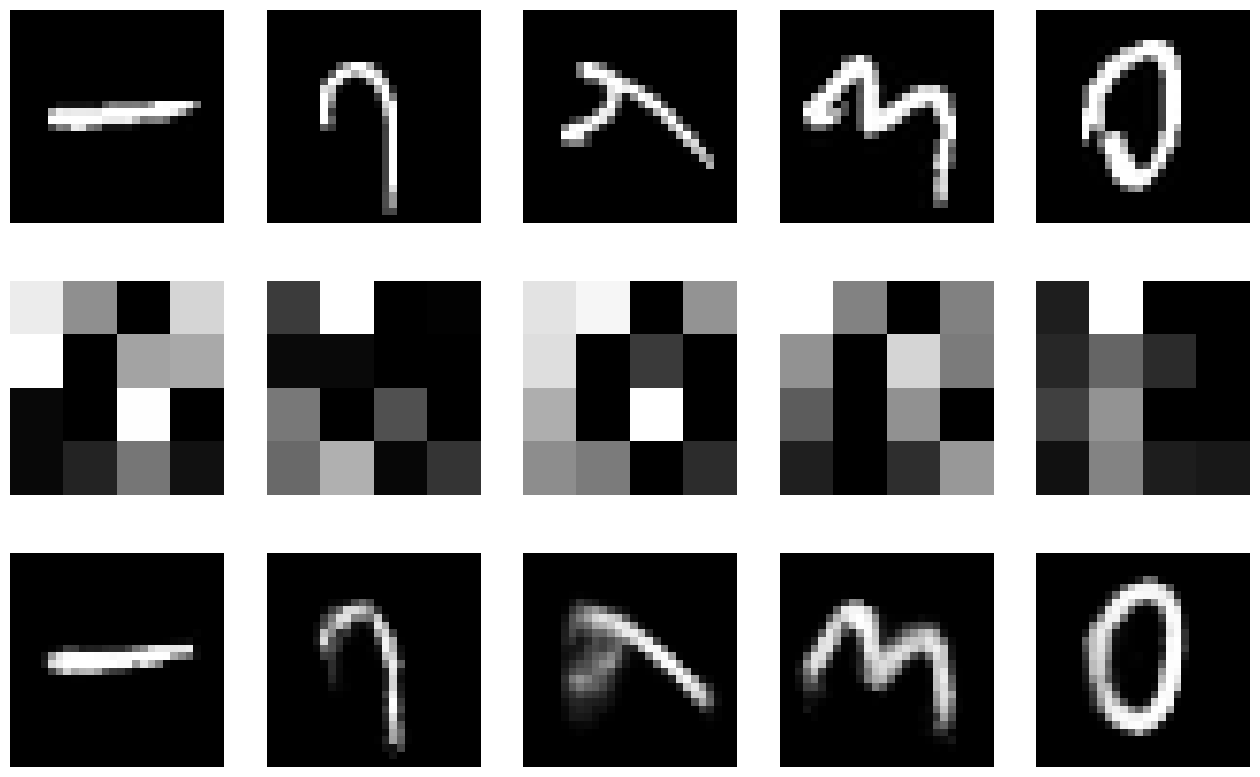

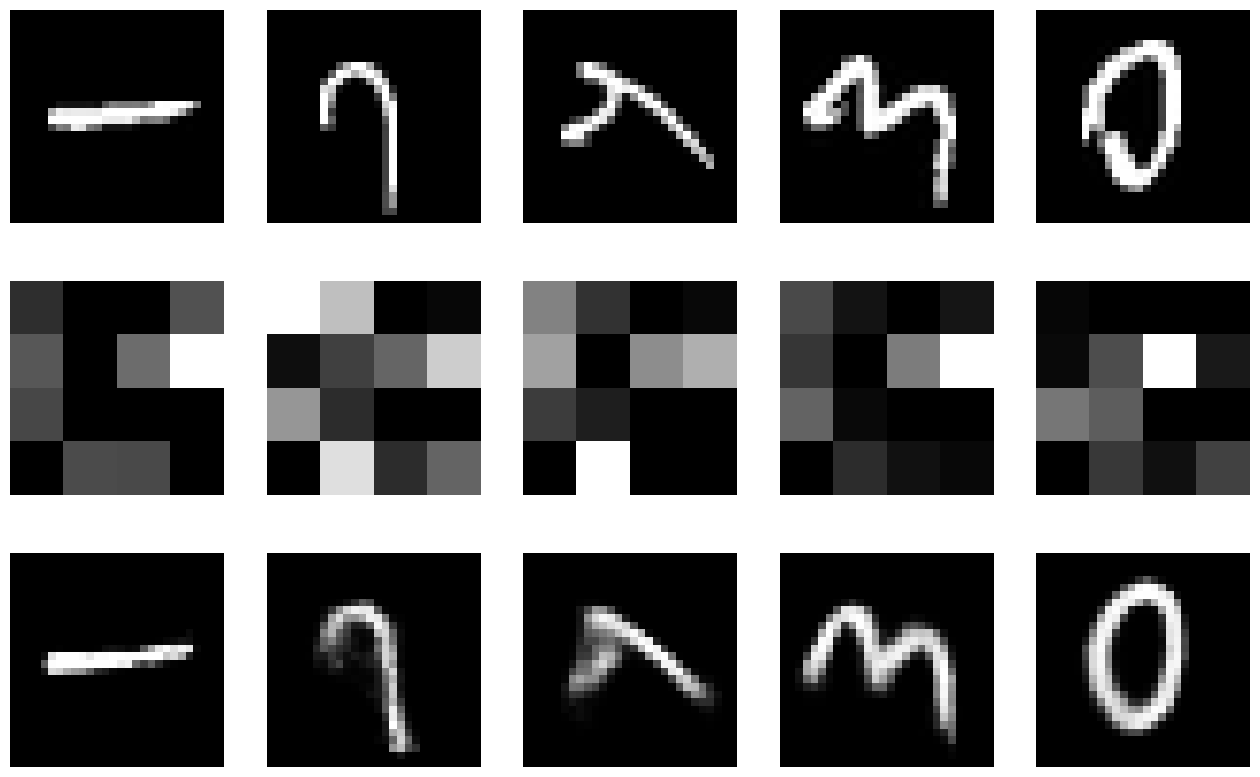

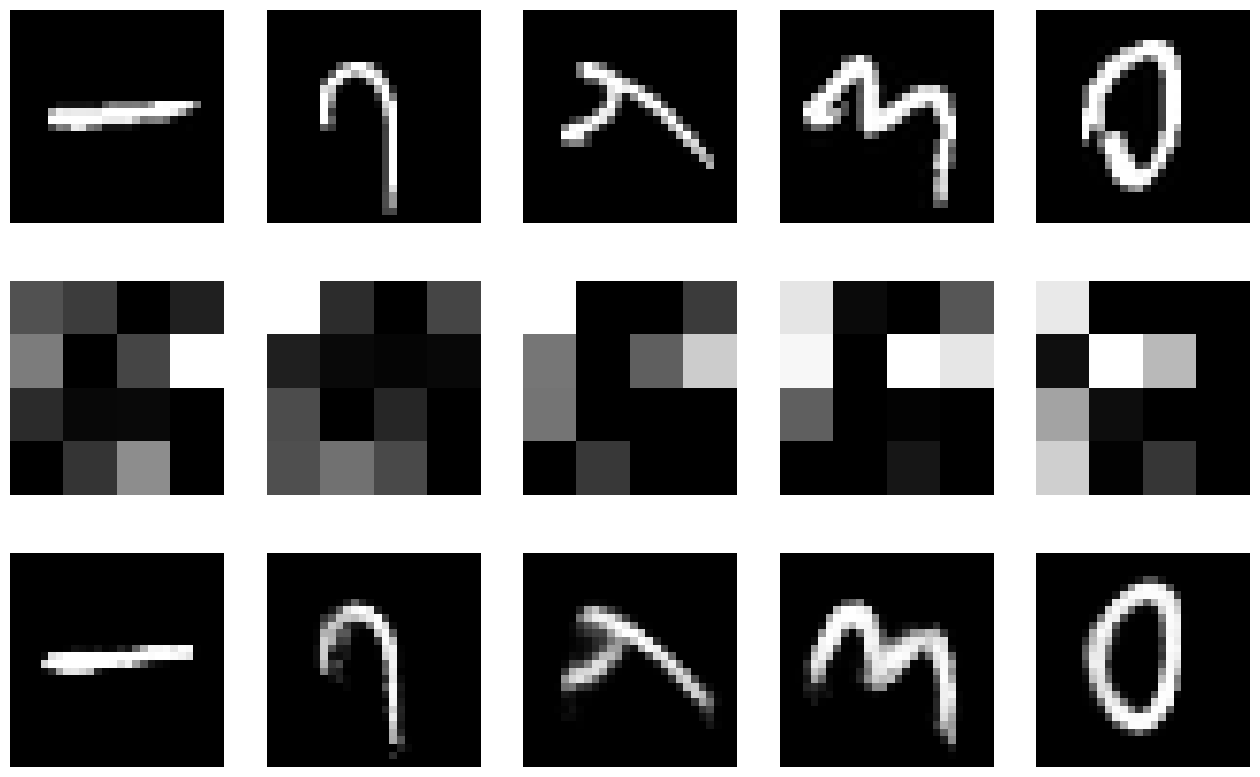

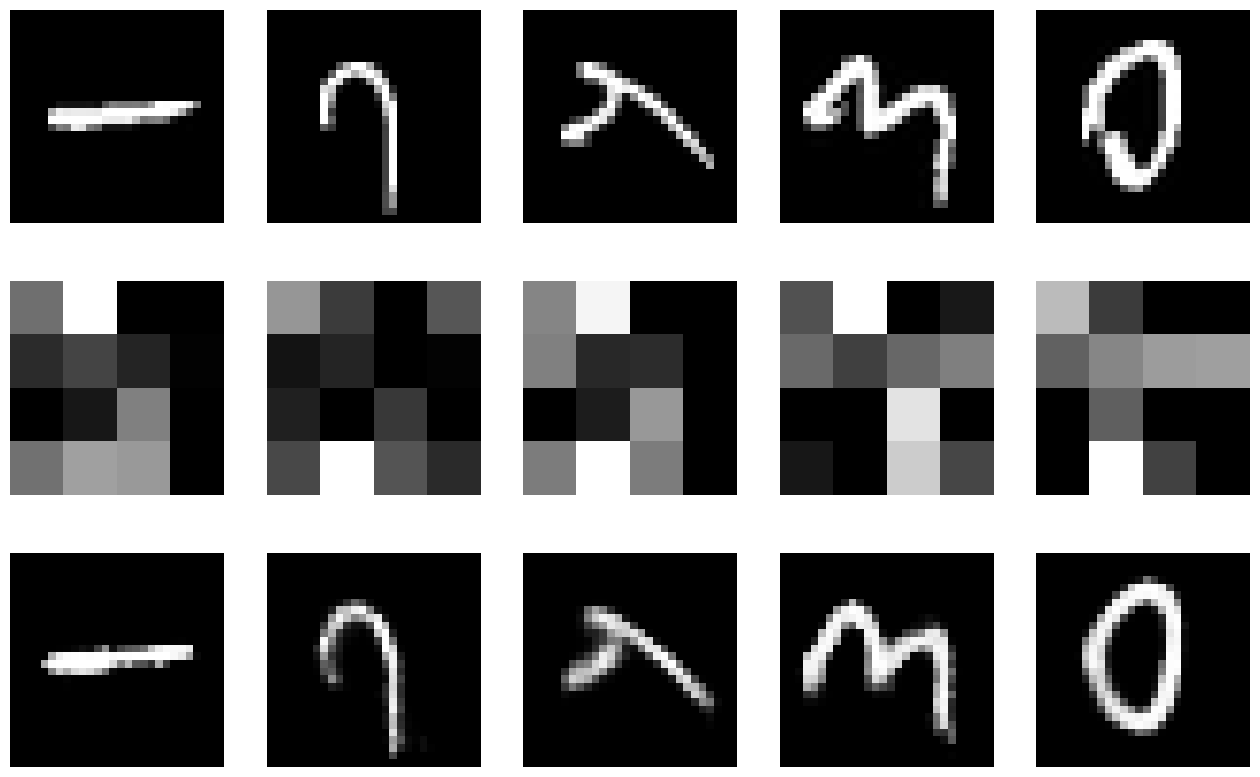

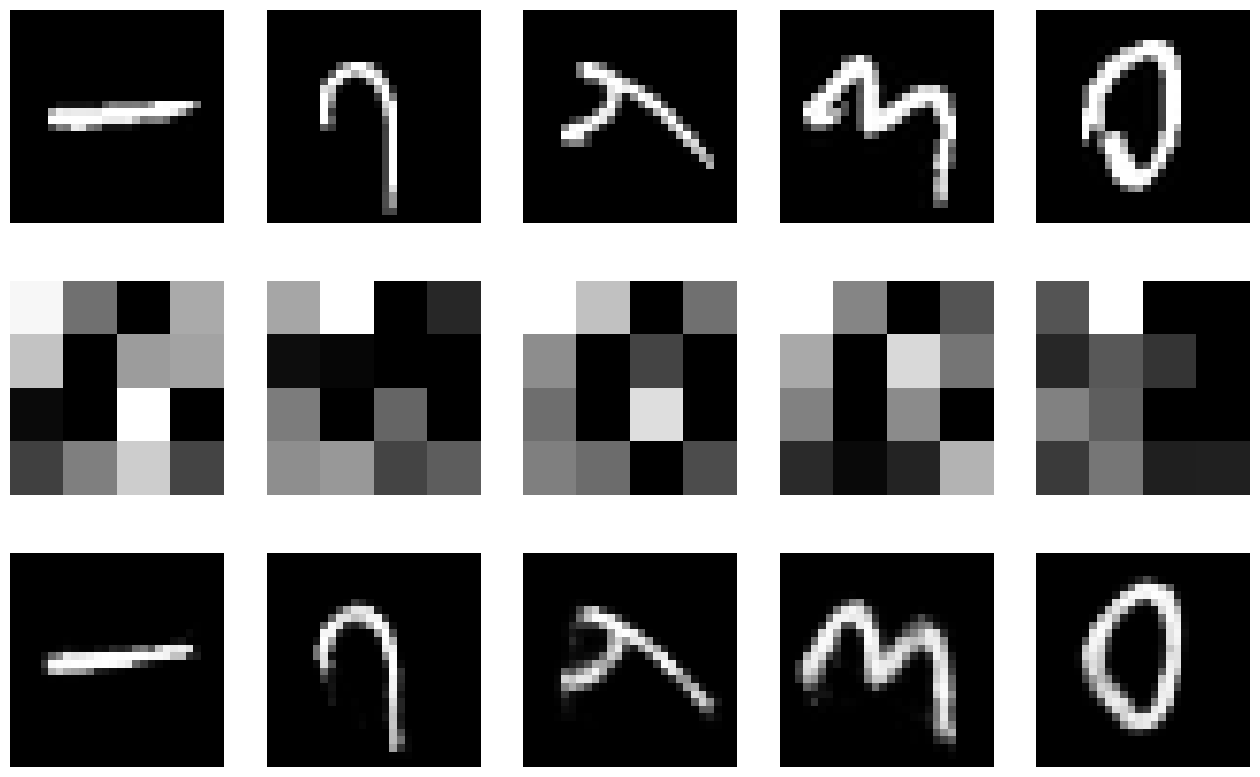

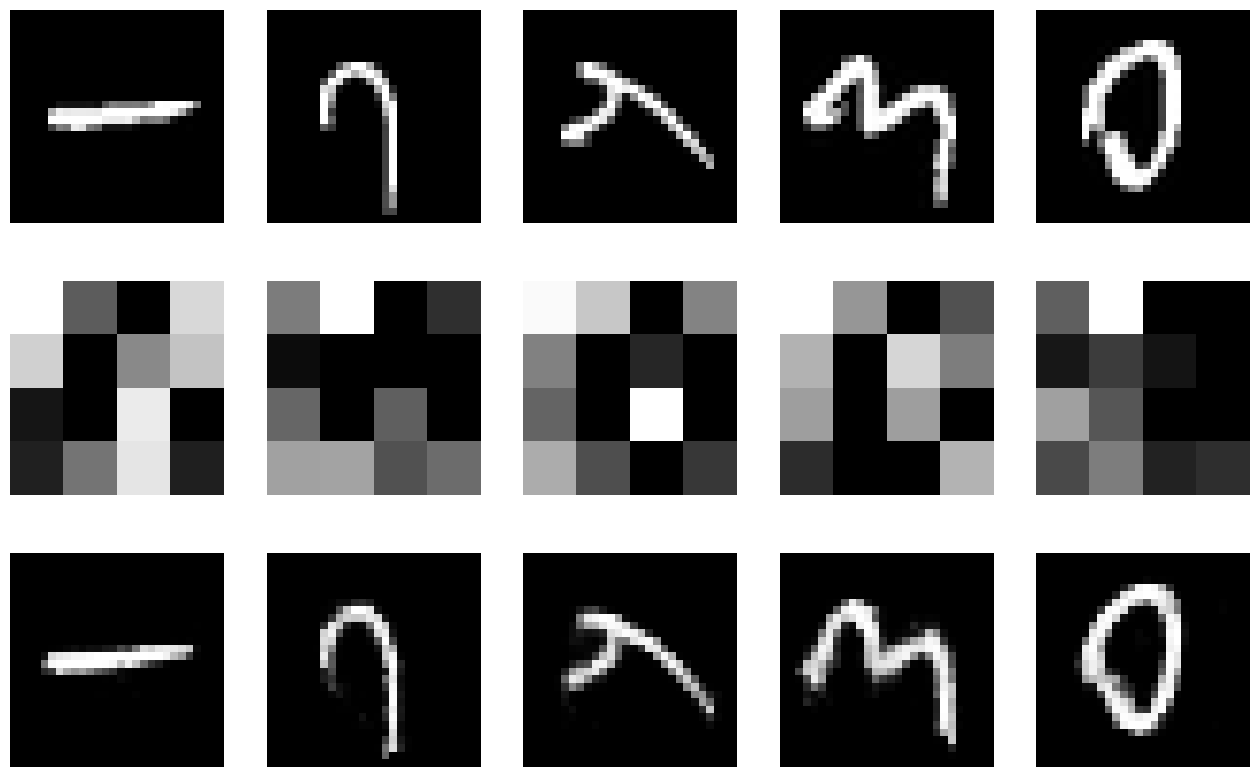

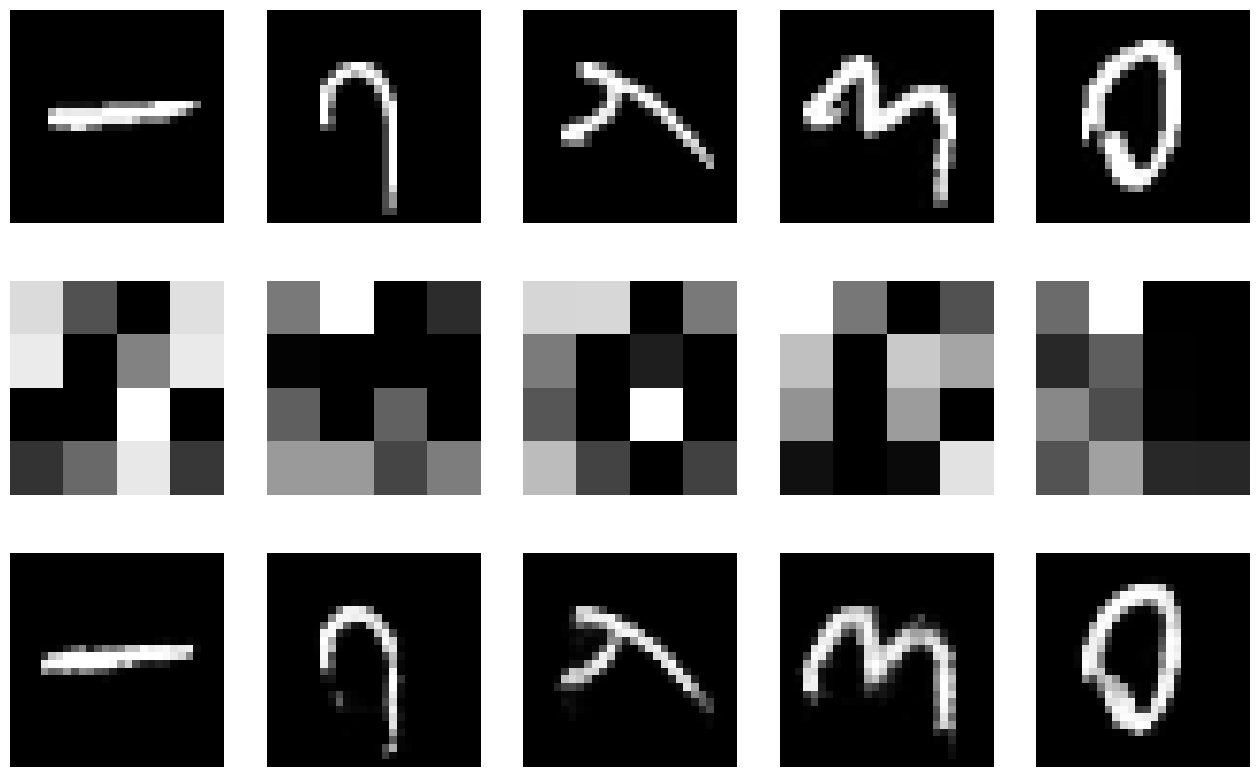

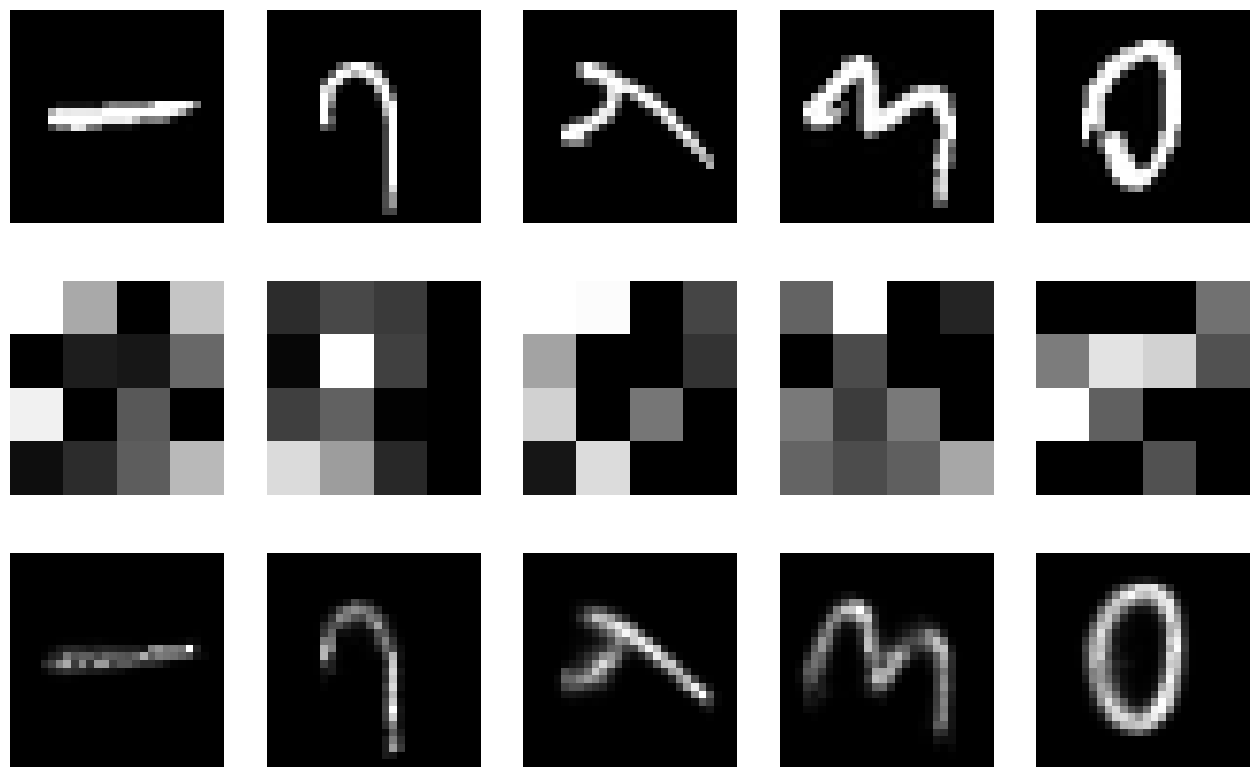

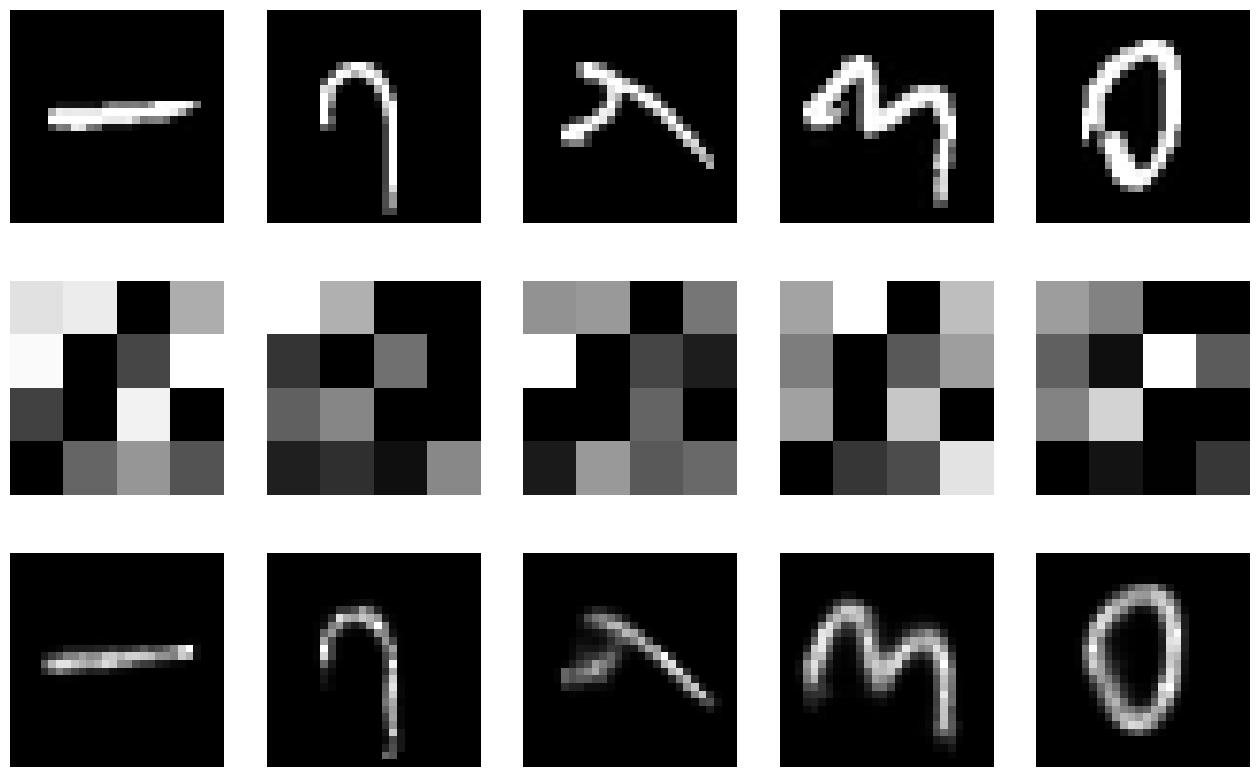

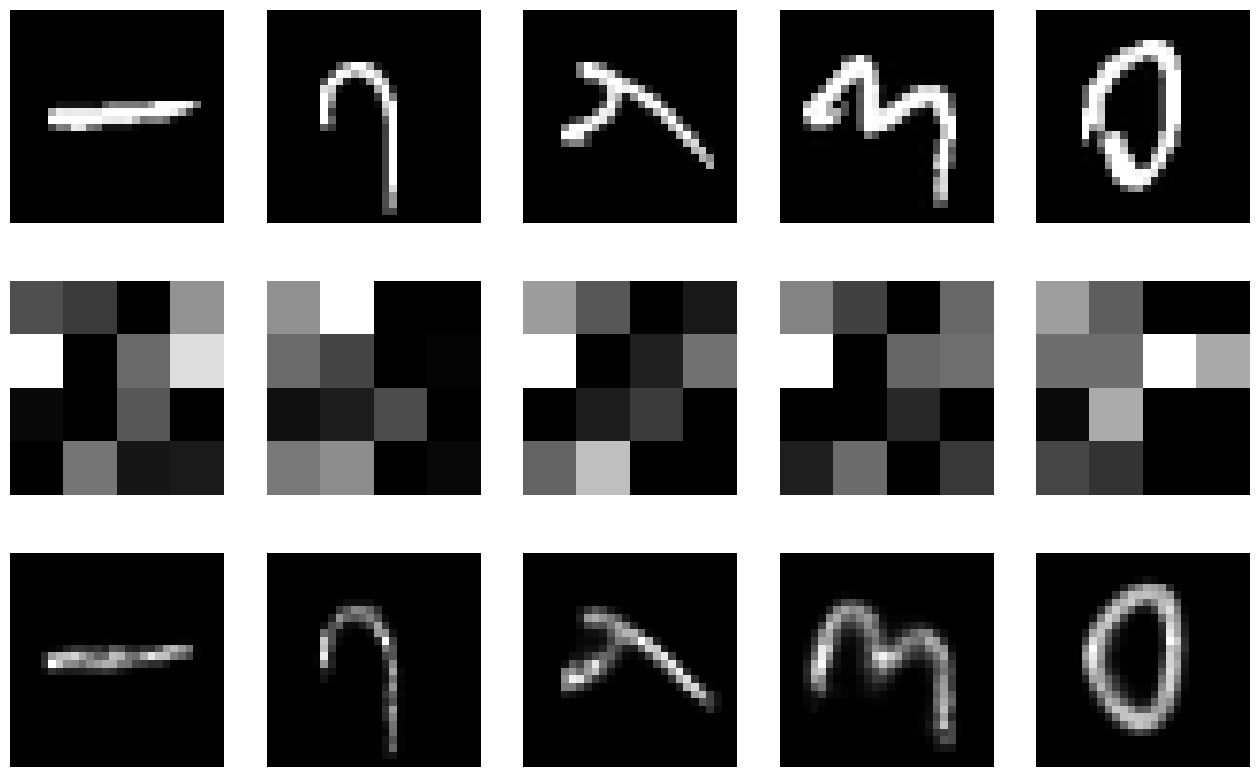

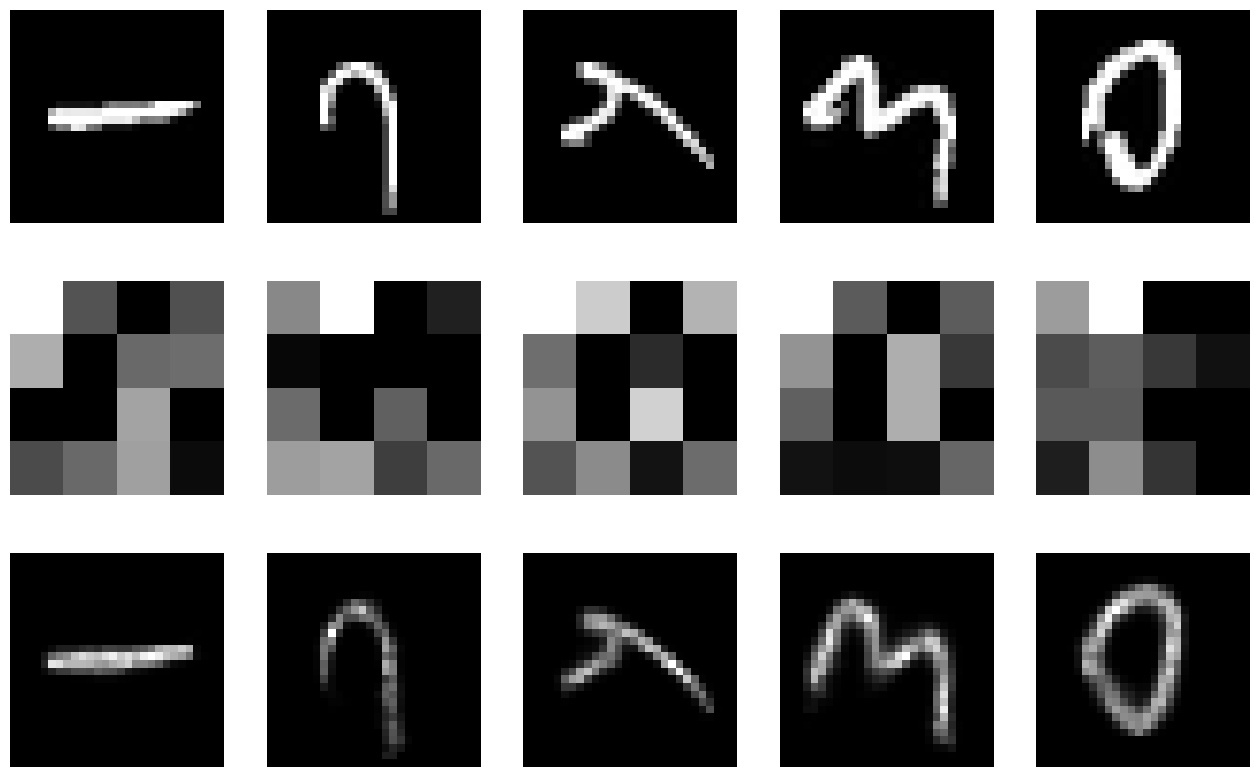

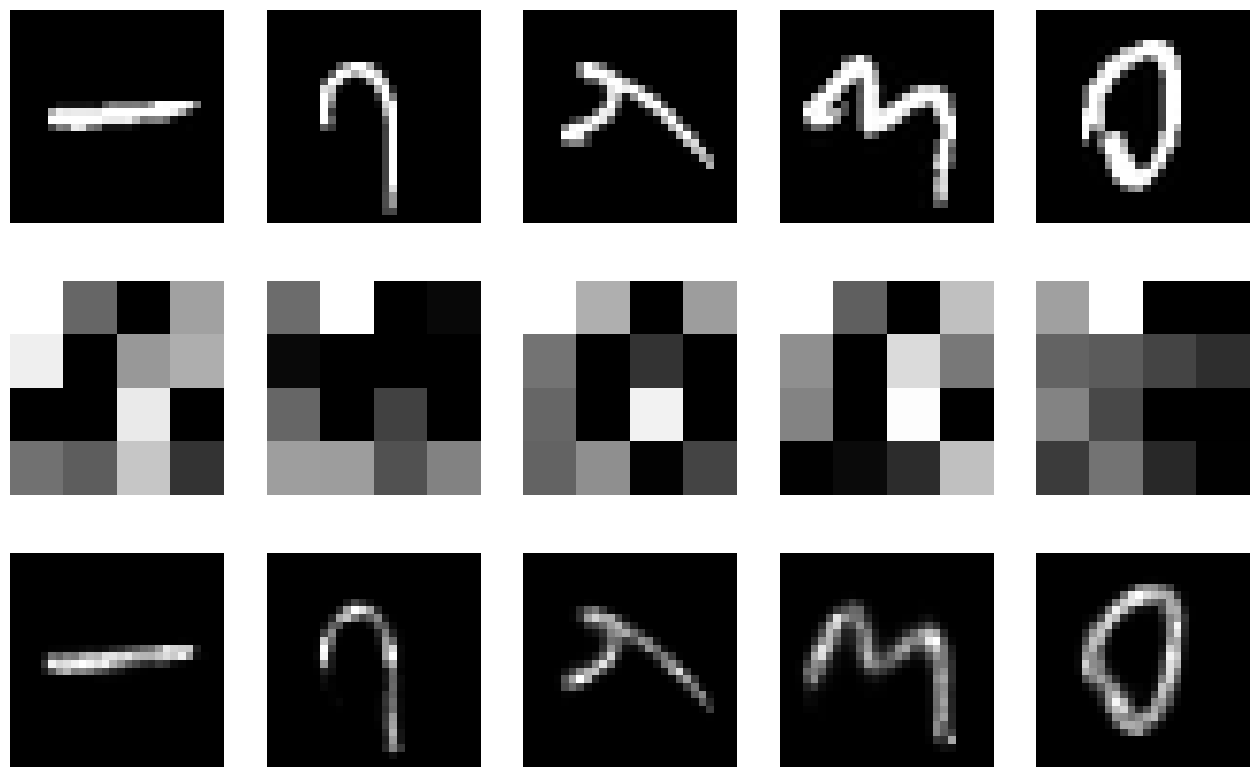

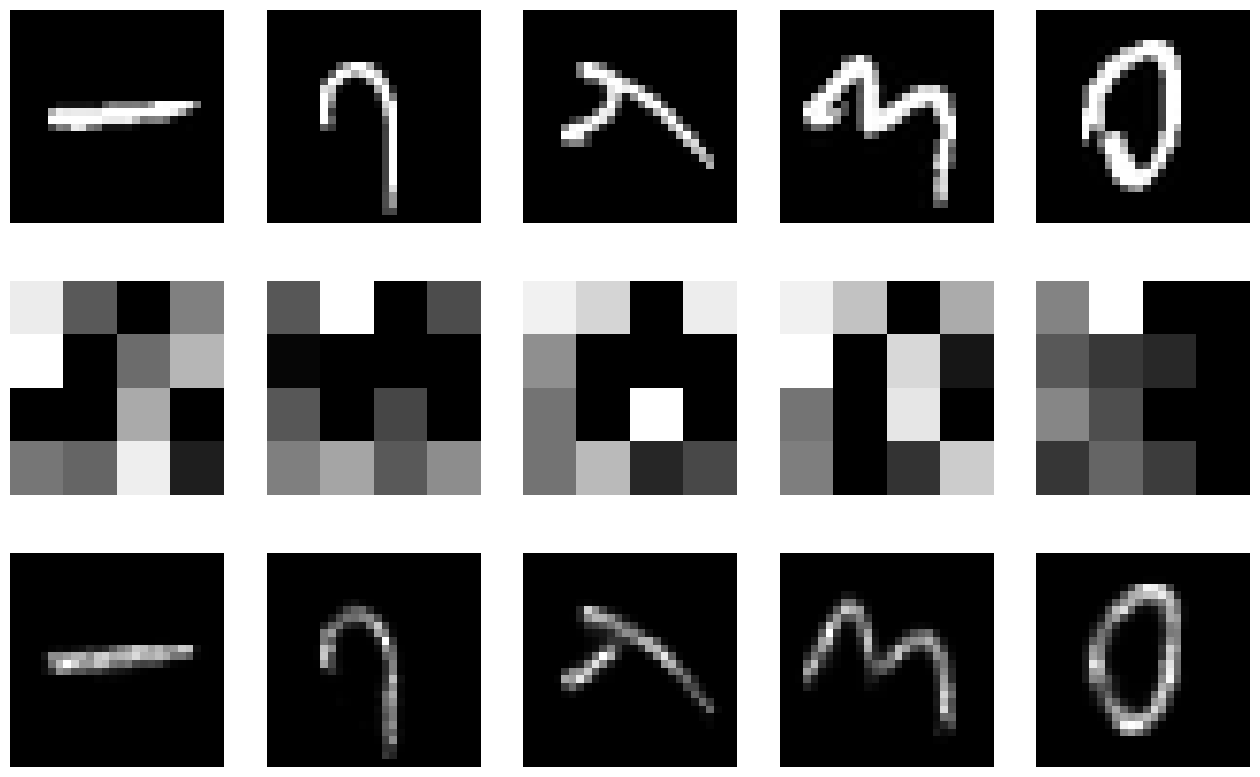

In [96]:
plot_images(img_data,autoencoders3)

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
12,50,softmax,relu,0.513103,binary_crossentropy,adagrad
13,100,softmax,relu,0.512235,binary_crossentropy,adagrad
14,150,softmax,relu,0.511436,binary_crossentropy,adagrad
15,50,softmax,relu,0.51123,binary_crossentropy,adam
16,100,softmax,relu,0.513127,binary_crossentropy,adam
17,150,softmax,relu,0.514961,binary_crossentropy,adam


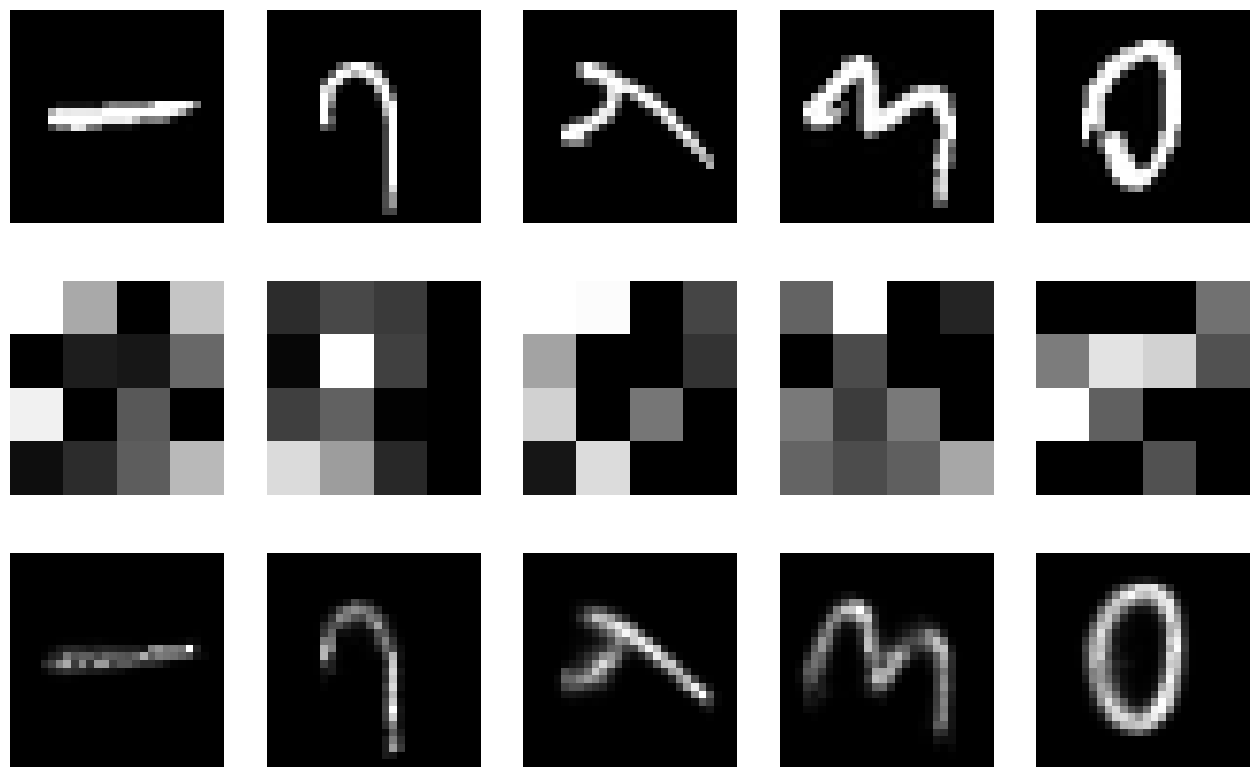

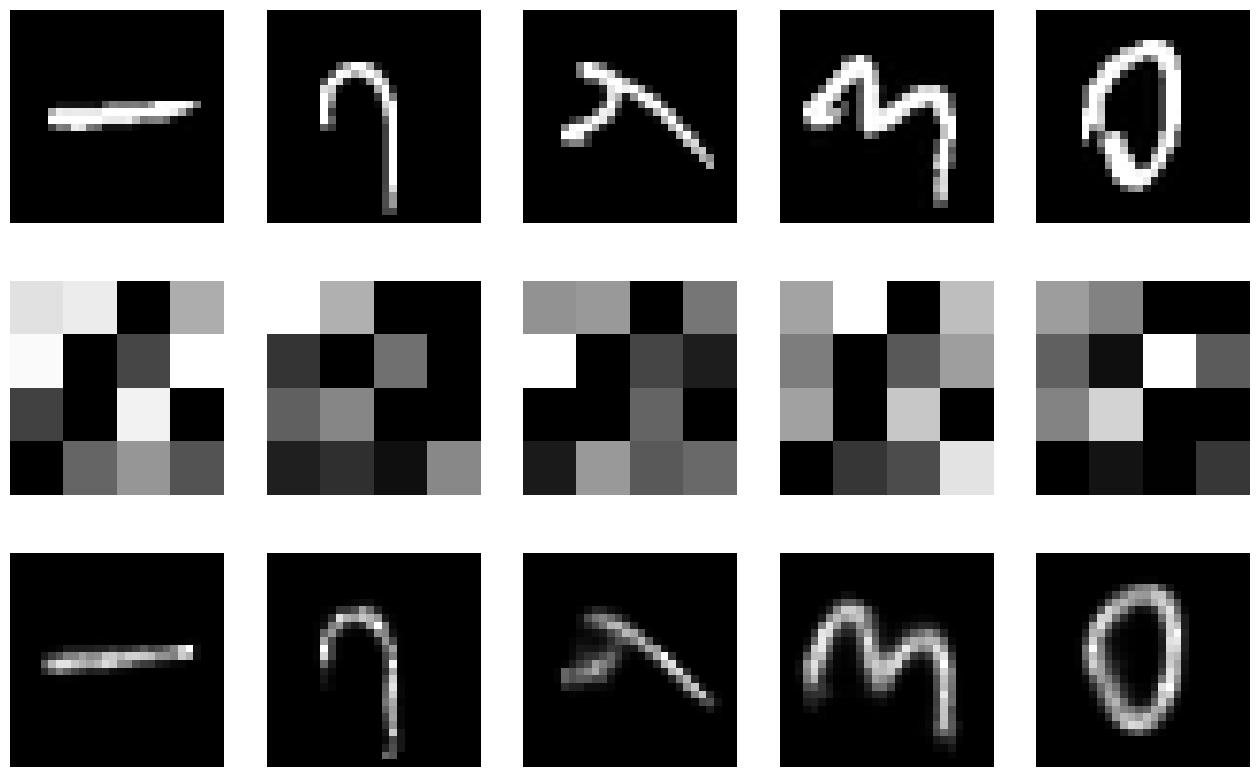

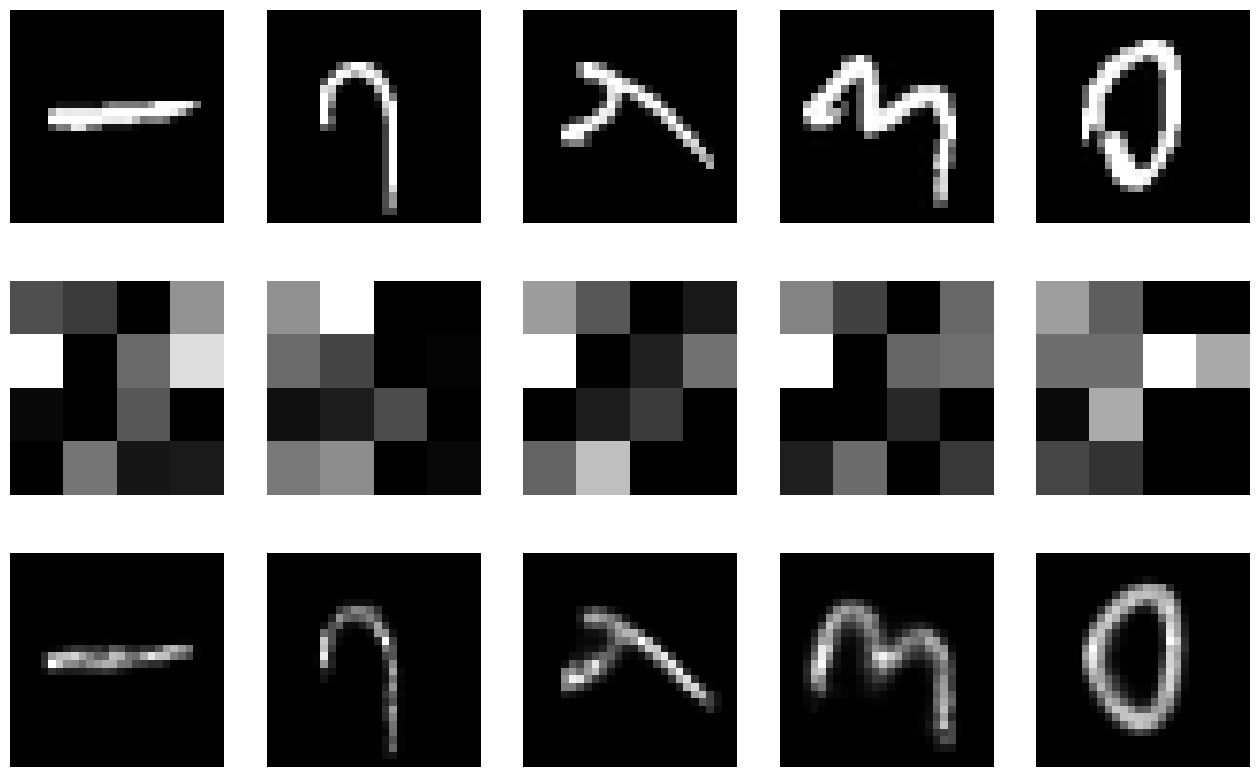

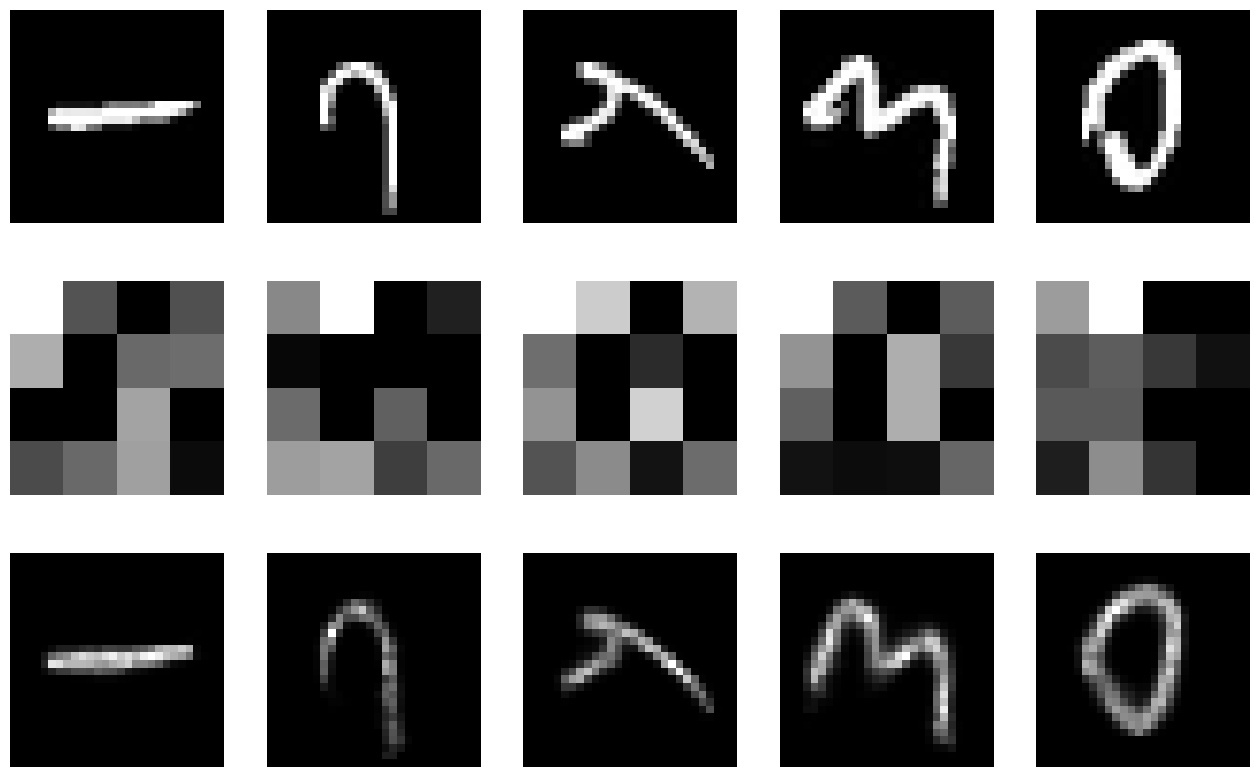

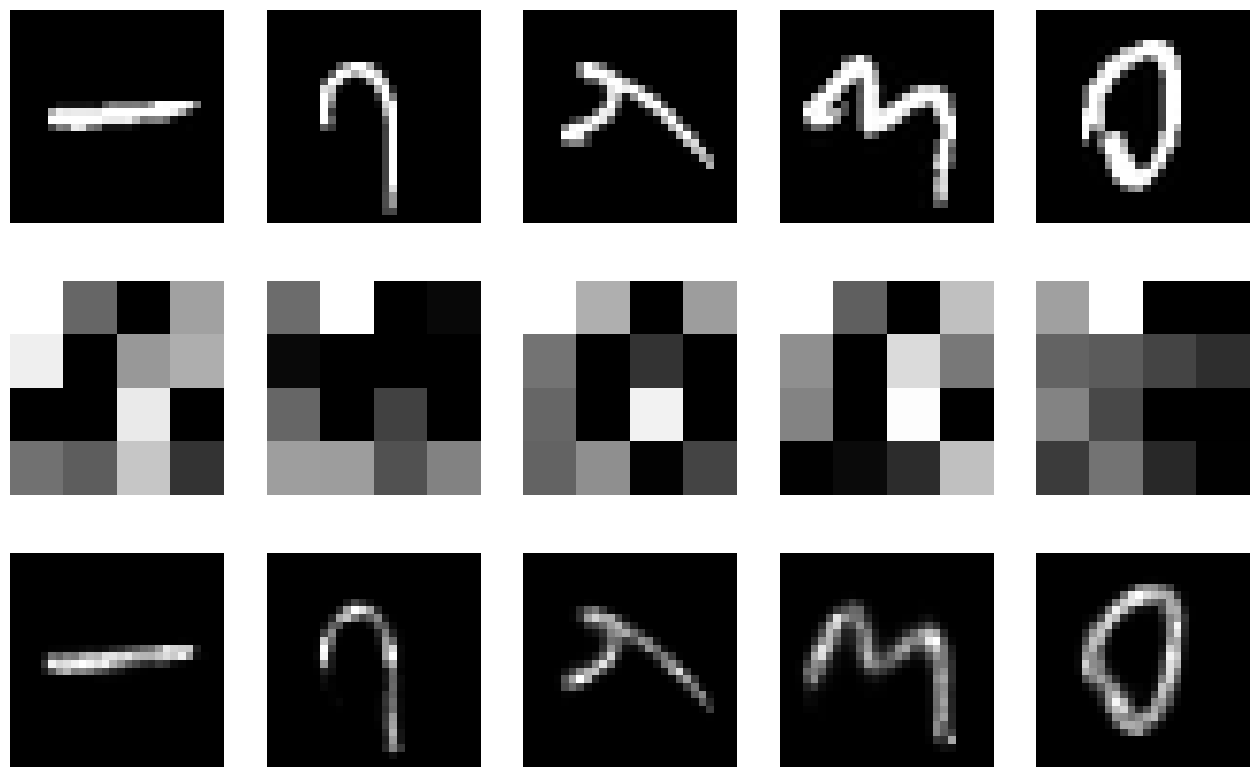

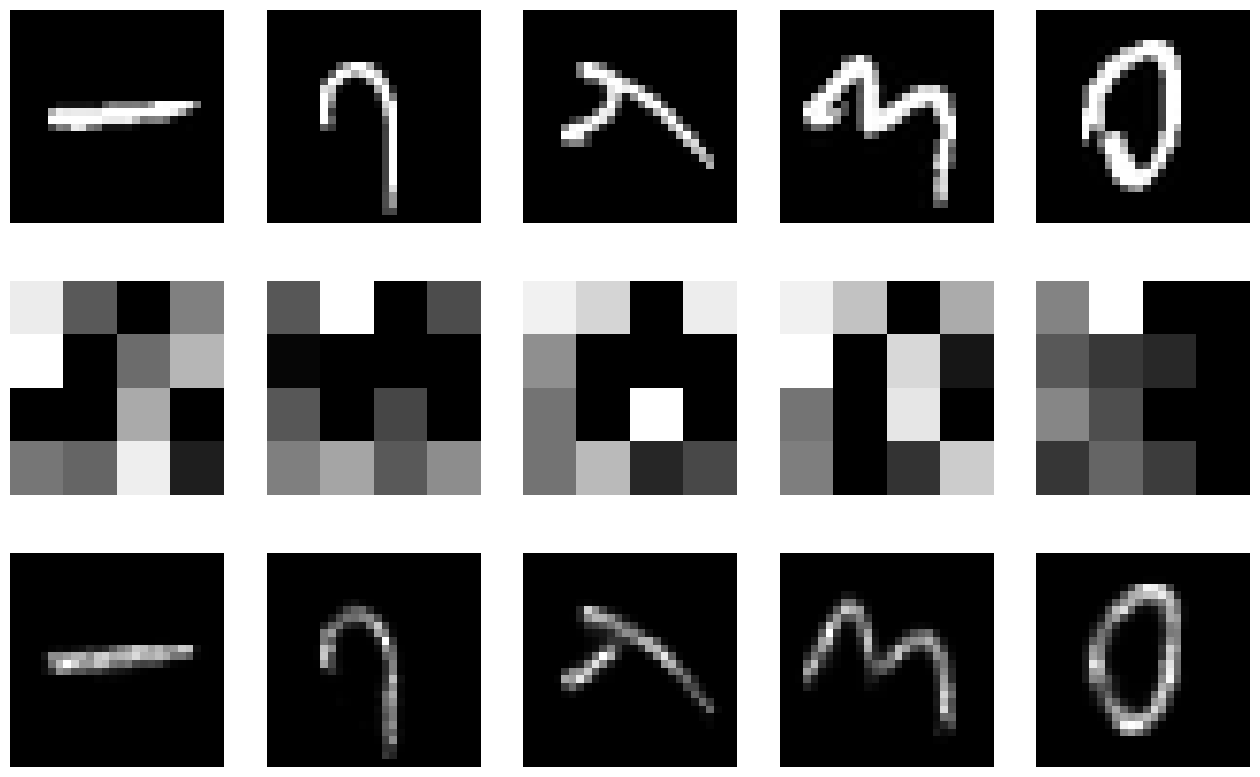

In [ ]:
plot_images(img_data,dict(list(autoencoders3.items())[-6:]))
df_encoded_pars3[df_encoded_pars3["Final Activation"]=="softmax"]

Given softmax still produced blurry images, these iterations will be rejected as some of the sigmoid encoders produced much better results.

In [100]:
for key in range(12,18):
    if key in autoencoders3:
        autoencoders3.pop(key)
        df_encoded_pars3.drop(key,inplace=True)
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.104482,binary_crossentropy,adagrad
1,100,sigmoid,relu,0.0977855,binary_crossentropy,adagrad
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
3,50,sigmoid,relu,0.0167825,mean_squared_error,adadelta
4,100,sigmoid,relu,0.0171126,mean_squared_error,adadelta
5,150,sigmoid,relu,0.0158725,mean_squared_error,adadelta
6,50,sigmoid,relu,0.0144542,mean_squared_error,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam


,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
0,50,sigmoid,relu,0.104482,binary_crossentropy,adagrad
1,100,sigmoid,relu,0.0977855,binary_crossentropy,adagrad
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad


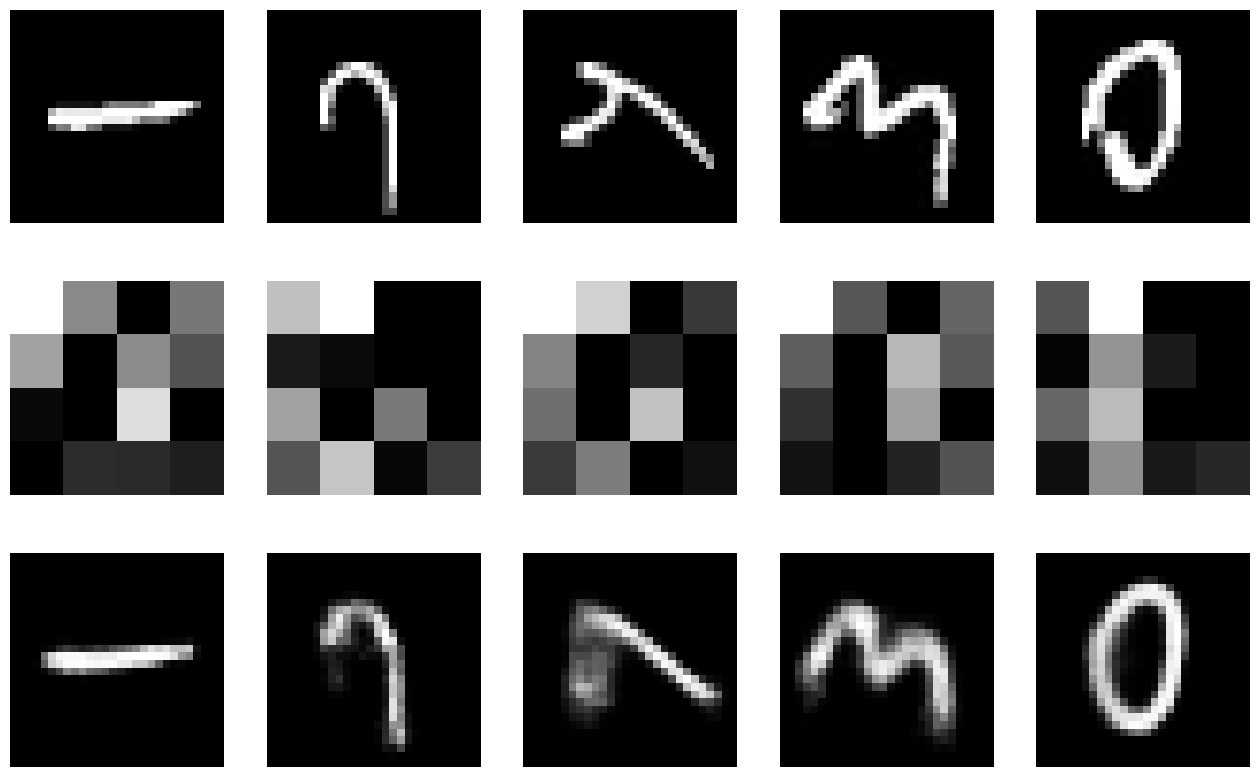

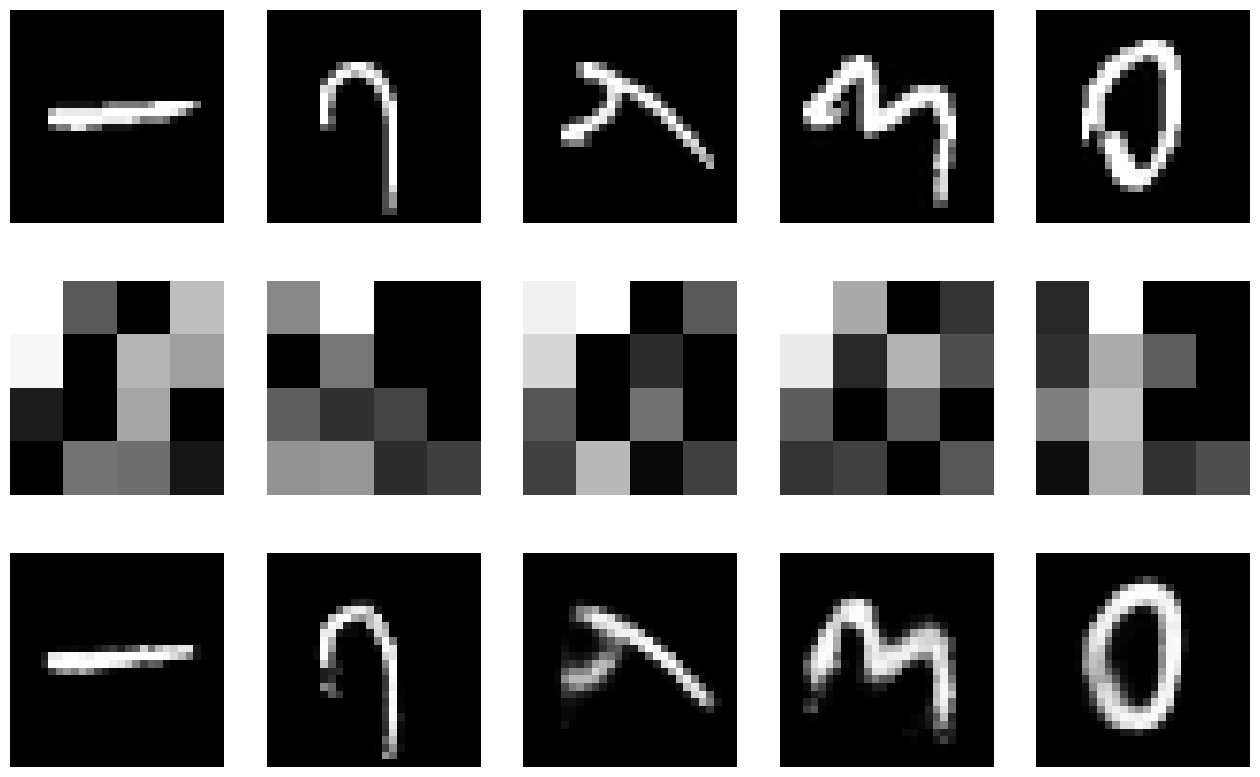

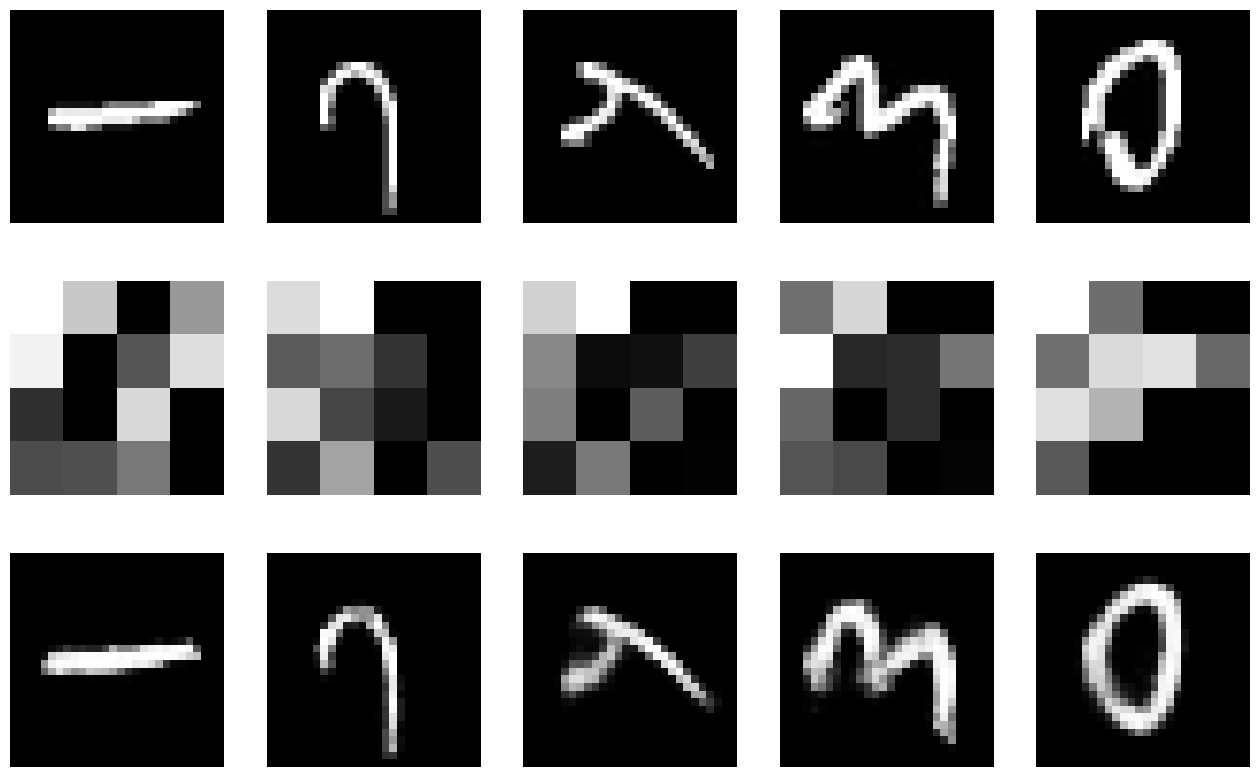

In [101]:
plot_images(img_data,dict(list(autoencoders3.items())[0:3]))
df_encoded_pars3[df_encoded_pars3["Loss Function"]=="binary_crossentropy"]

For the encoders using **Binary Crossentropy**, the last one that trained over 150 epochs produced great quality reconstruction, so only this version will continue to the next round of eliminations.

In [102]:
for key in range(0,2):
    if key in autoencoders3:
        autoencoders3.pop(key)
        df_encoded_pars3.drop(key,inplace=True)
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
3,50,sigmoid,relu,0.0167825,mean_squared_error,adadelta
4,100,sigmoid,relu,0.0171126,mean_squared_error,adadelta
5,150,sigmoid,relu,0.0158725,mean_squared_error,adadelta
6,50,sigmoid,relu,0.0144542,mean_squared_error,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam
11,150,sigmoid,relu,0.0168335,mean_squared_error,adam


,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
3,50,sigmoid,relu,0.0167825,mean_squared_error,adadelta
4,100,sigmoid,relu,0.0171126,mean_squared_error,adadelta
5,150,sigmoid,relu,0.0158725,mean_squared_error,adadelta
6,50,sigmoid,relu,0.0144542,mean_squared_error,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam
11,150,sigmoid,relu,0.0168335,mean_squared_error,adam


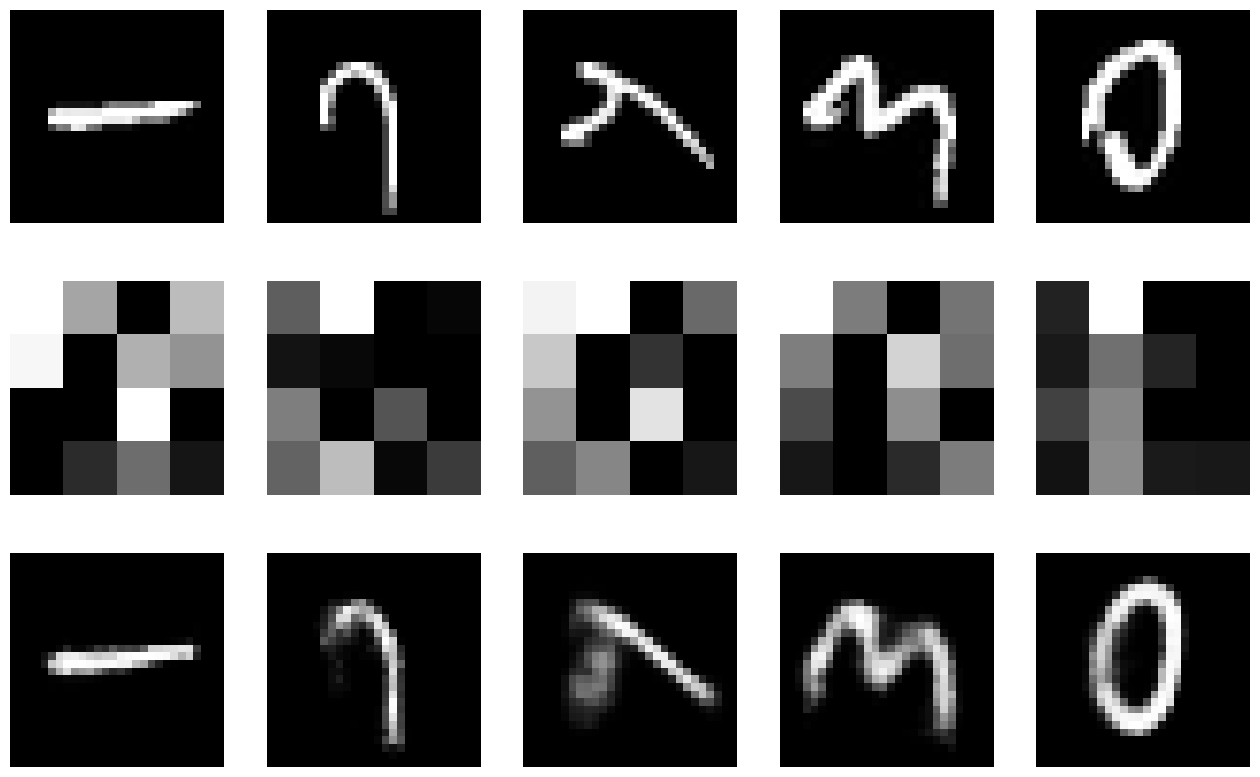

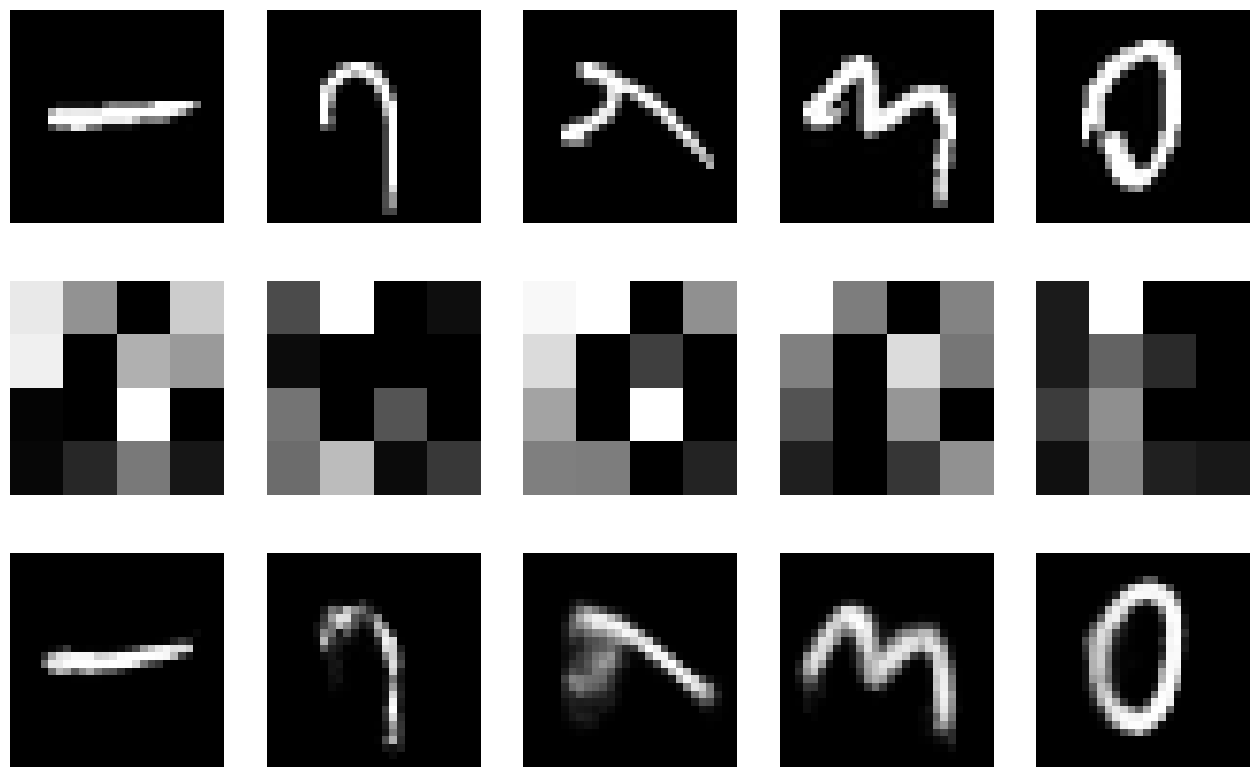

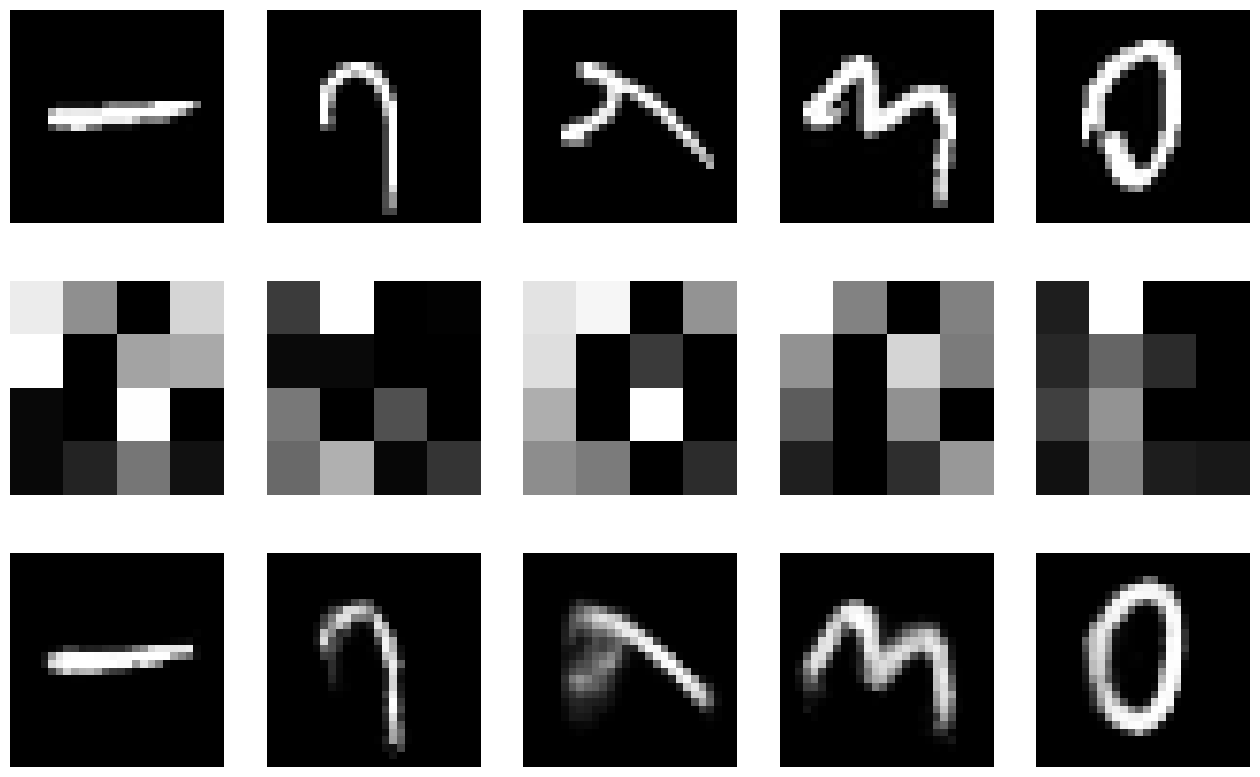

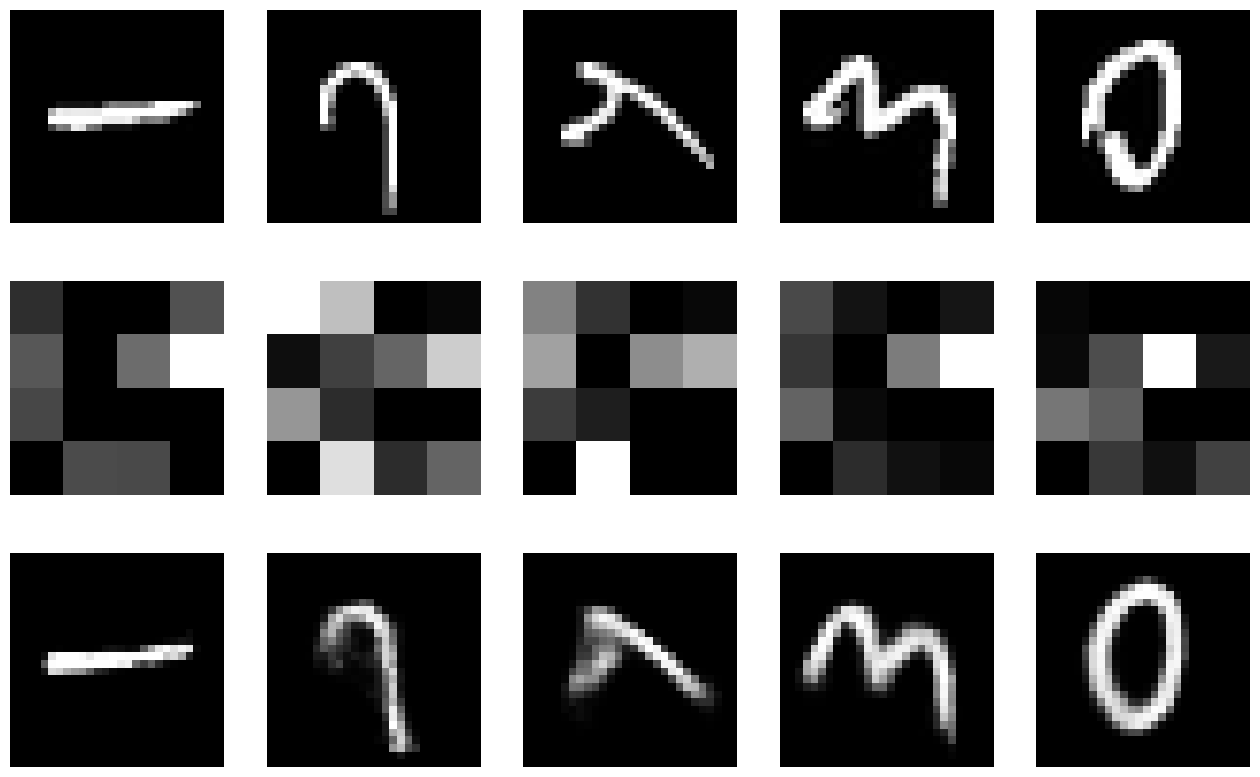

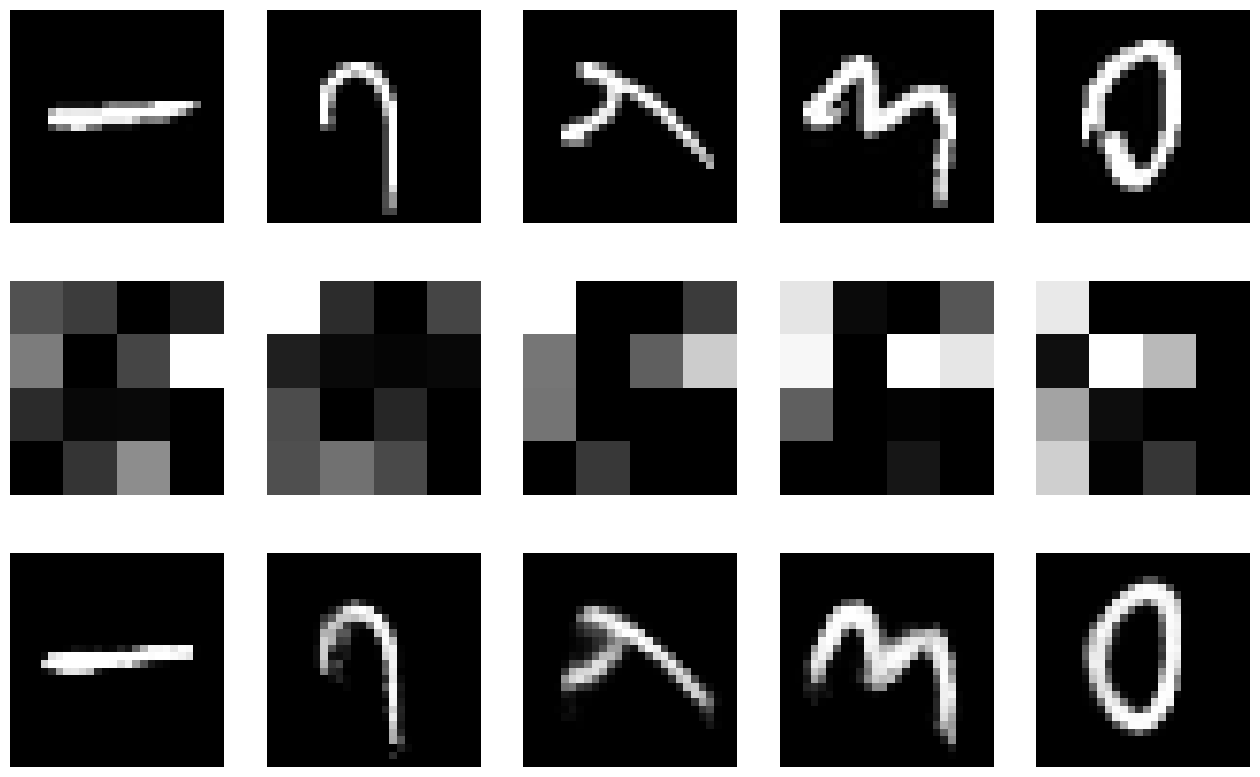

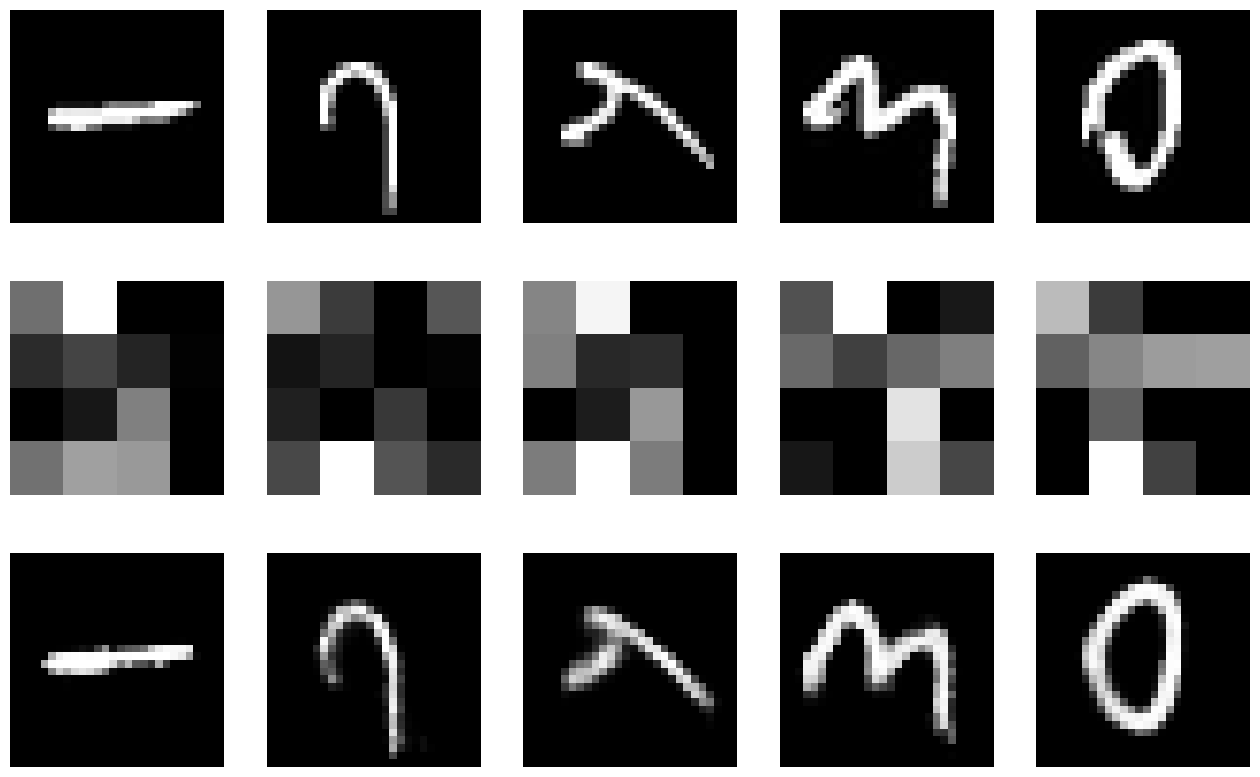

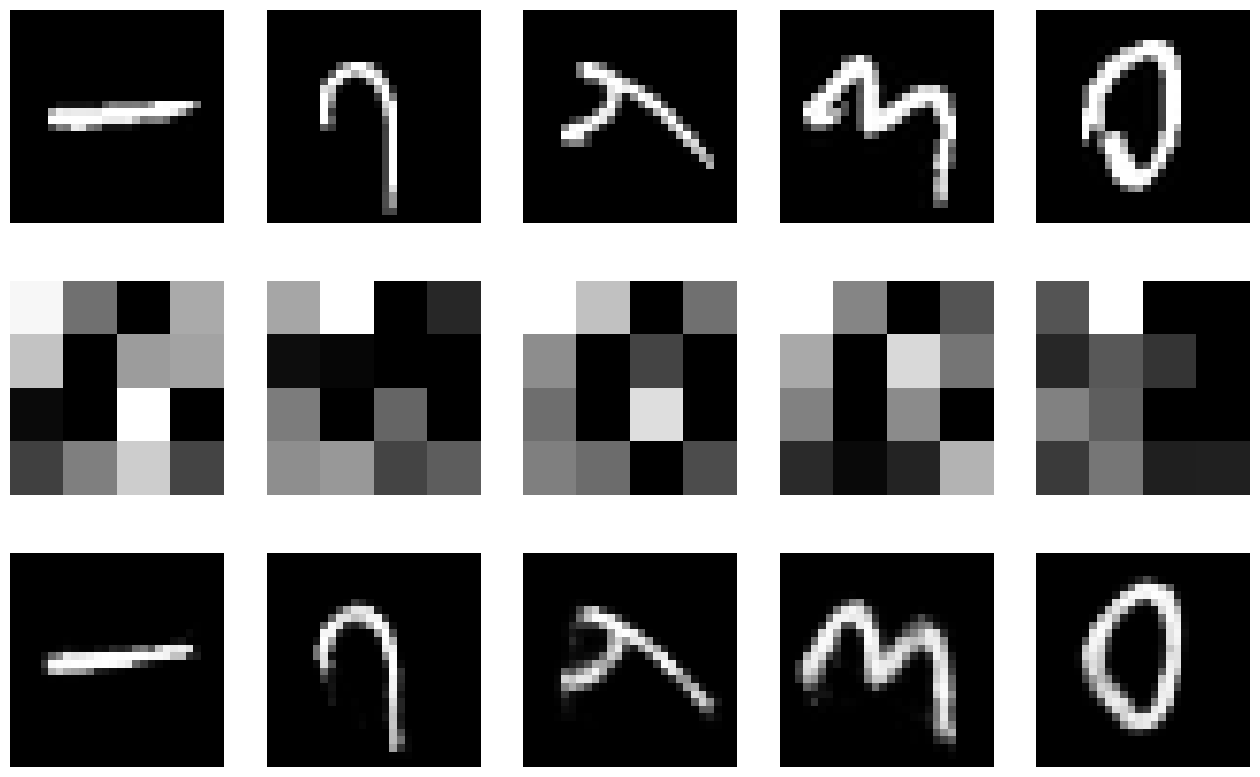

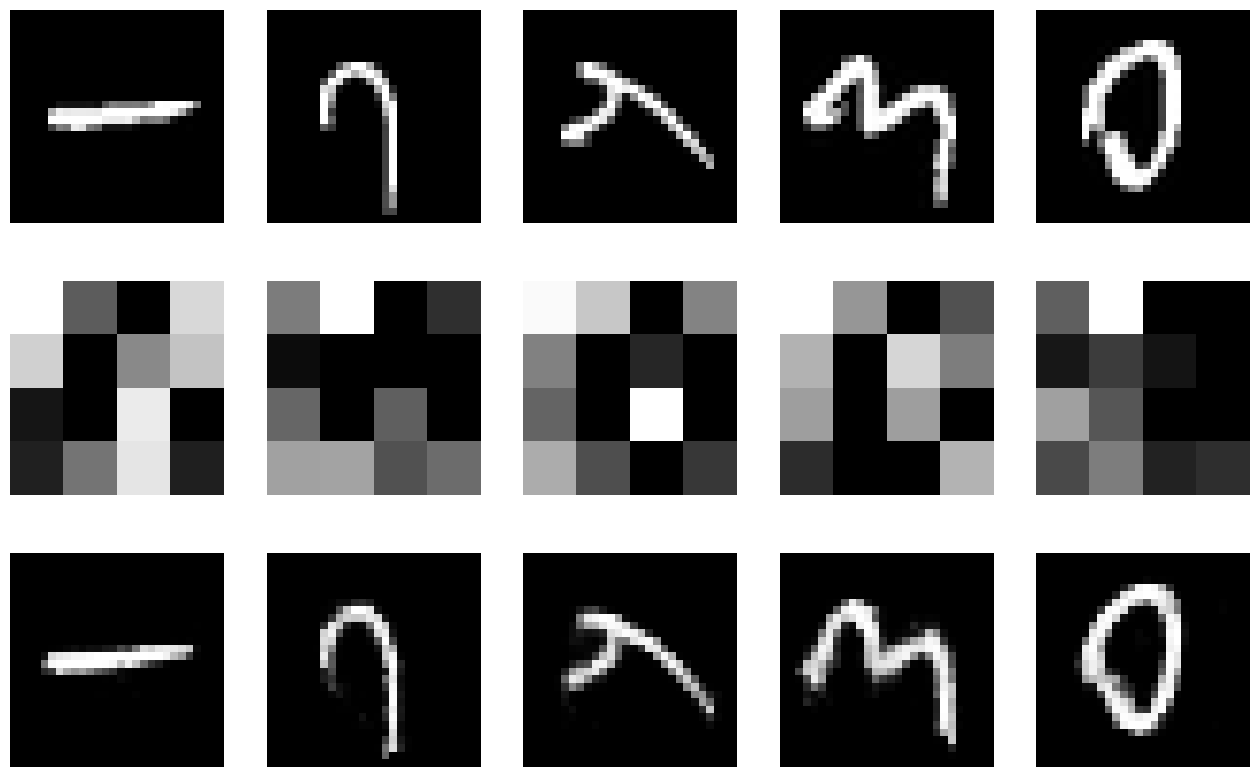

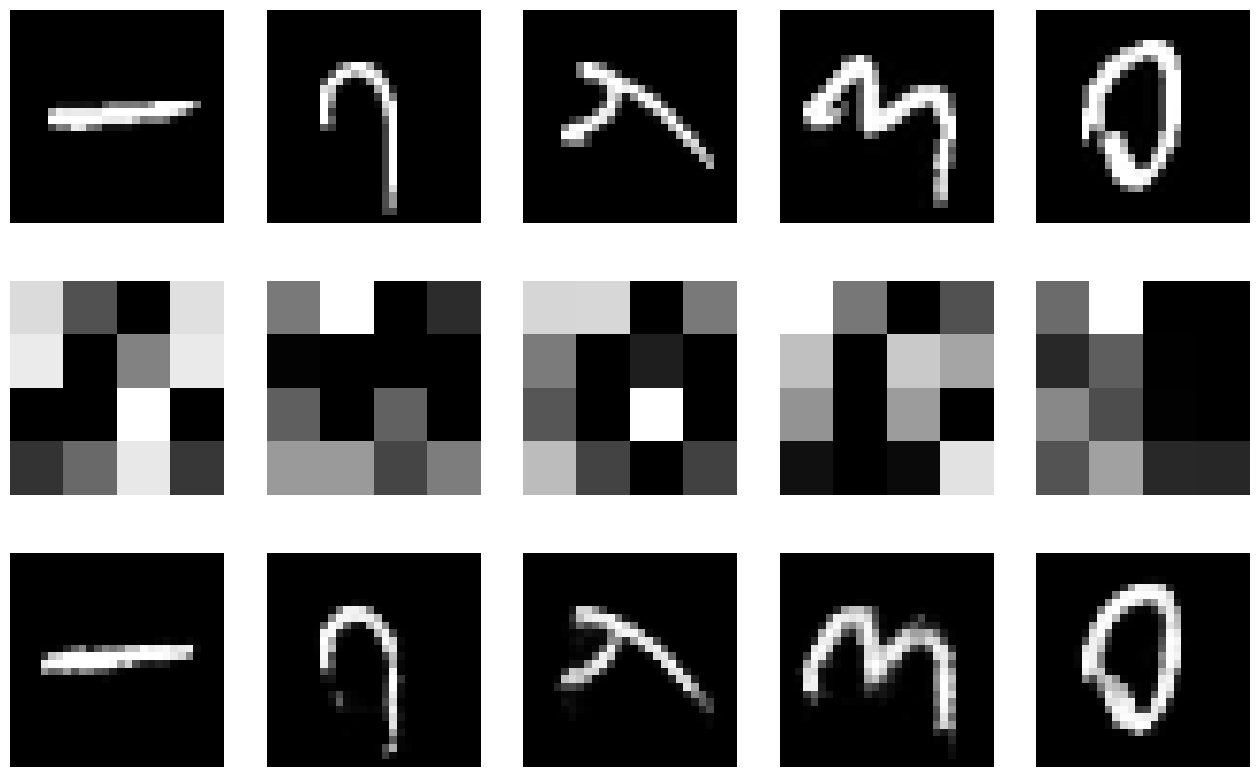

In [ ]:
plot_images(img_data,dict(list(autoencoders3.items())[1:]))
df_encoded_pars3[df_encoded_pars3["Loss Function"]=="mean_squared_error"]

We rejected Models 3, 4, 5 and 6 because their reconstructions were not detailed enough. All four used Sigmoid, ReLU and MSE with model 6 having a different optimizer. Models 3, 4 and 5 used the Adadelta optimizer and were trained for 50, 100 and 150 epochs. Increasing the epochs did not help the model reconstruct better. In all three, the simple digits (the flat stroke, the hook and the 0) were rebuilt a bit somewhat clearly. Switching the optimizer still did not fix the problem. we rejected Models 3–6 and kept the encoders that produced fuller, more accurate digits.

In [104]:
for key in range(3,7):
    if key in autoencoders3:
        autoencoders3.pop(key)
        df_encoded_pars3.drop(key,inplace=True)
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam
11,150,sigmoid,relu,0.0168335,mean_squared_error,adam


,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
9,50,sigmoid,relu,0.0151574,mean_squared_error,adam
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam
11,150,sigmoid,relu,0.0168335,mean_squared_error,adam


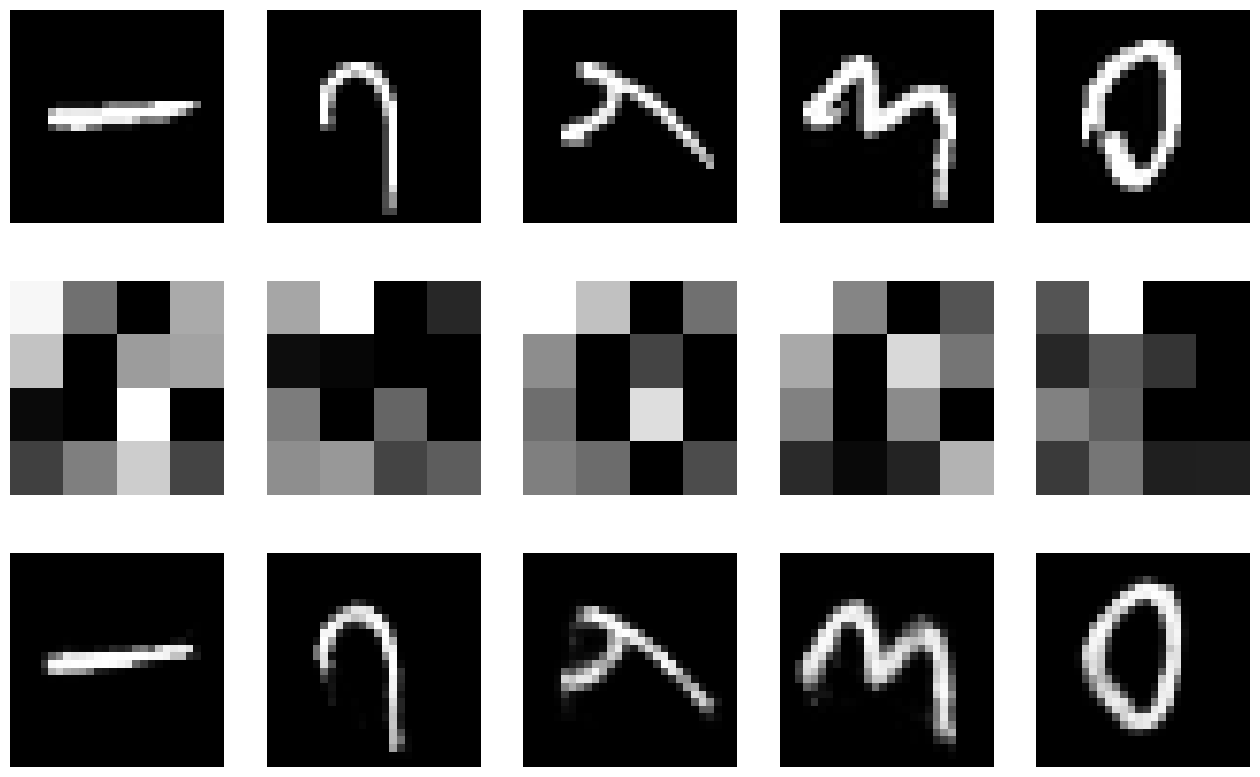

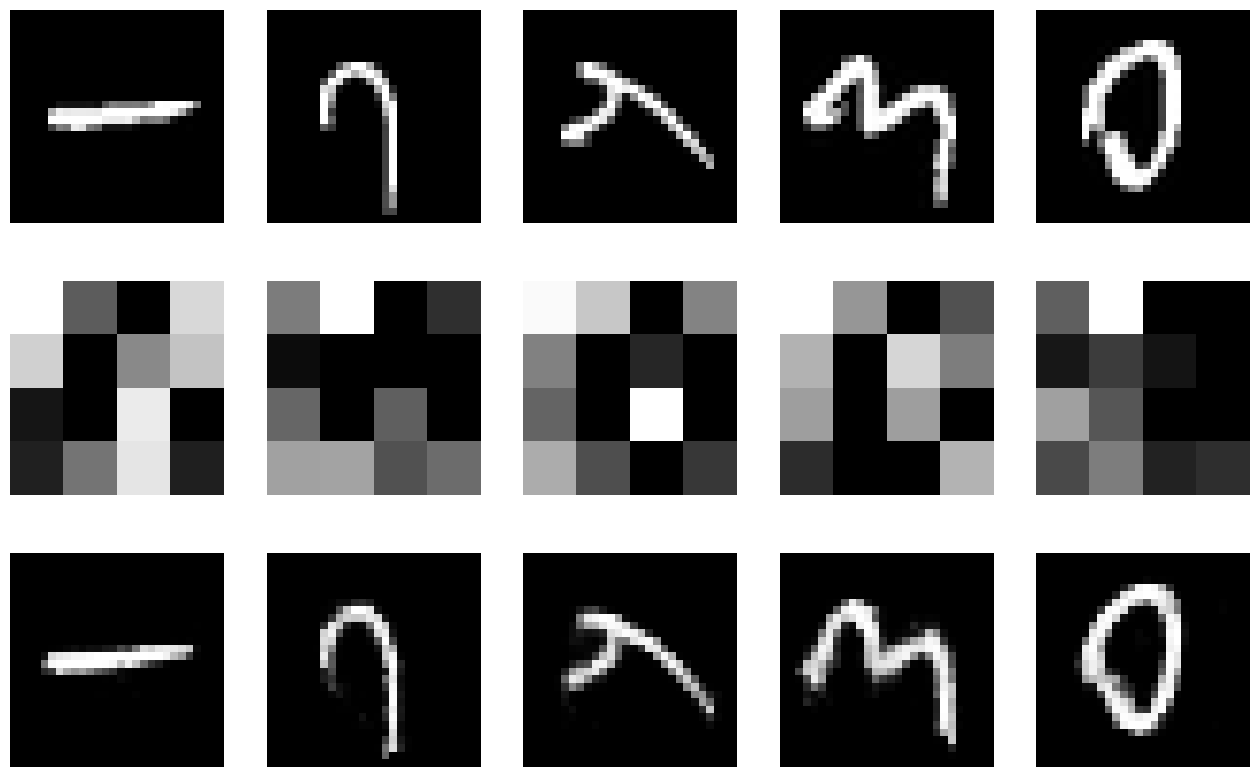

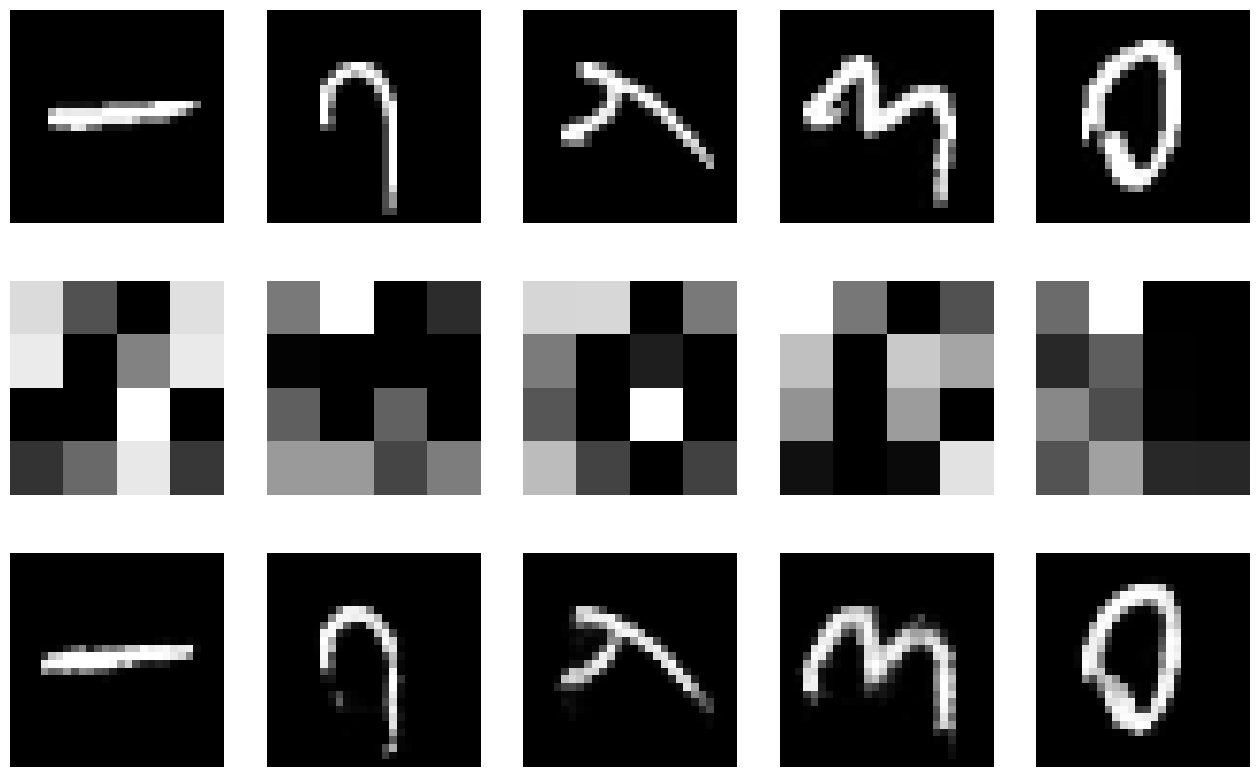

In [113]:
plot_images(img_data,dict(list(autoencoders3.items())[-3:]))
df_encoded_pars3[df_encoded_pars3["Optimizer"]=="adam"]

Of the models using optimizer **Adam**, the second version that ran over 100 epochs produced the best reconstructions. The one which ran over only 50 epochs had trailing pixels in some of the images causing some images to appear like they had missing lines. This noise mostly disappeared when trained over 100 epochs instead and the images became more defined. Between the 100 and 150 epoch versions of this encoder, there was negligible improvement. While some of the corners or sharp edges became more defined, the test loss on unseen images also increased. This leads us to reject the 150 epoch version as the improvements it provided in reconstruction quality were not worth the increased test loss and training time.

In [114]:
for key in [9,11]:
    if key in autoencoders3:
        autoencoders3.pop(key)
        df_encoded_pars3.drop(key,inplace=True)
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam


,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
2,150,sigmoid,relu,0.0987474,binary_crossentropy,adagrad
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
8,150,sigmoid,relu,0.0153049,mean_squared_error,adagrad


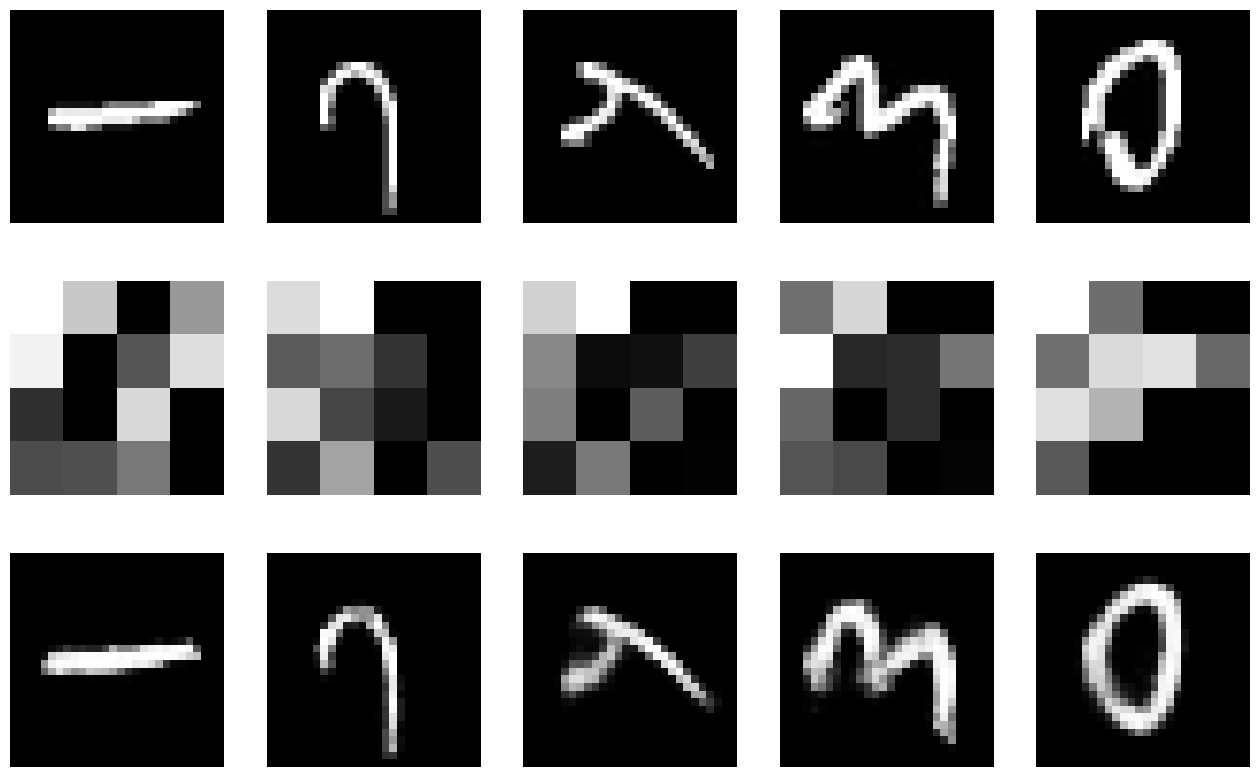

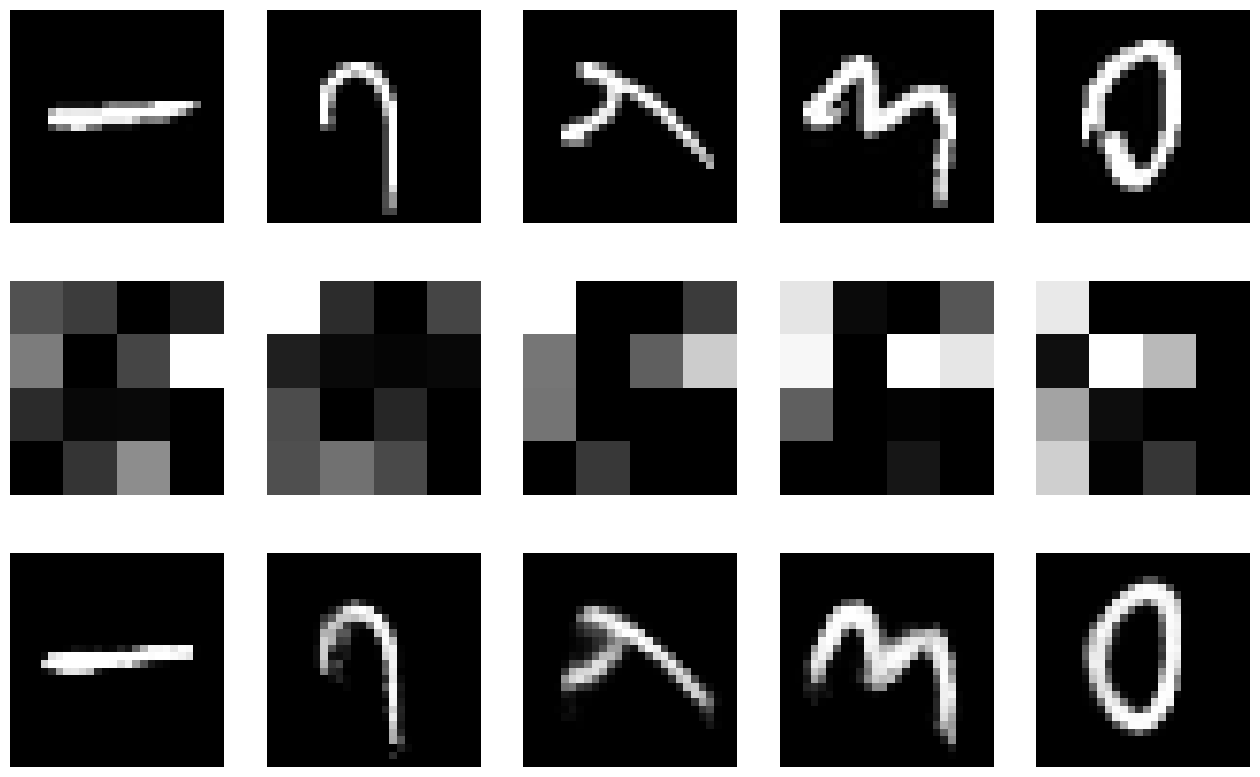

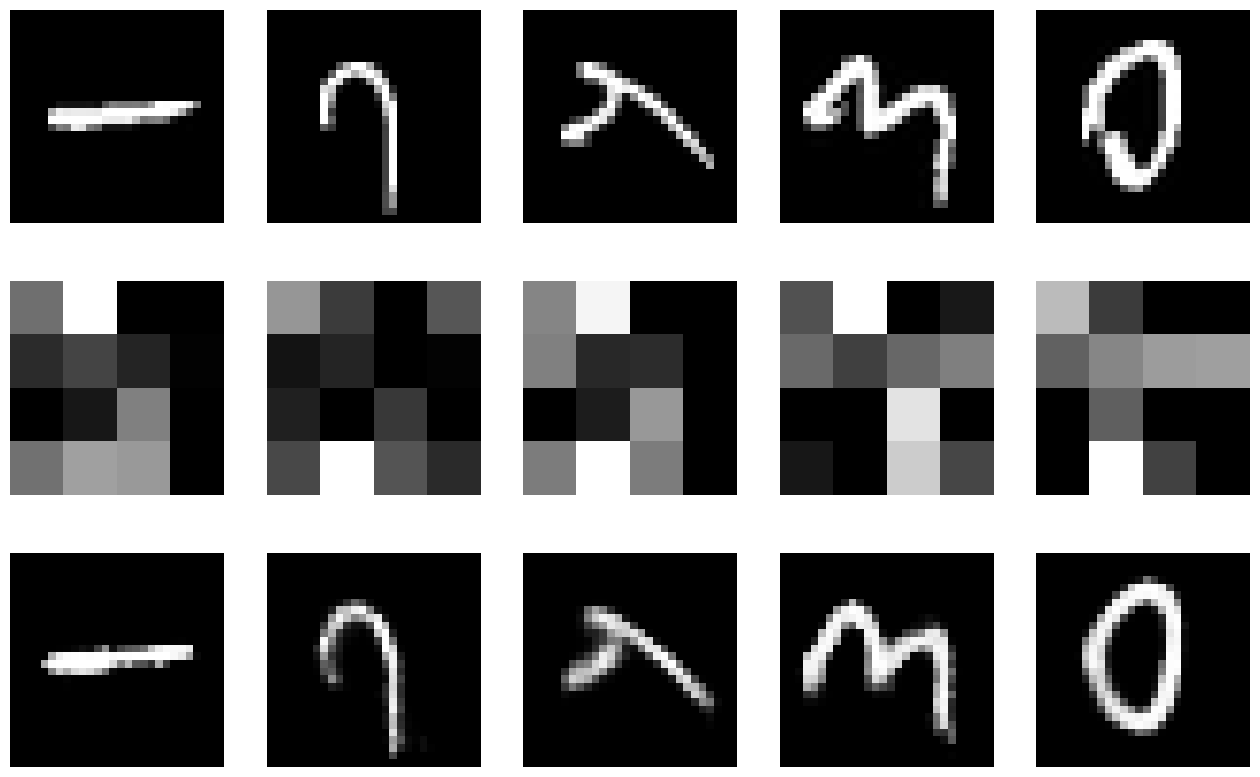

In [115]:
plot_images(img_data,dict(list(autoencoders3.items())[:3]))
df_encoded_pars3[df_encoded_pars3["Optimizer"]=="adagrad"]

For the remaining models that used the optimizer **Adagrad**, the first one uses the loss function **Binary Crossentropy** while the last 2 both use **MSE** and only differ in number of epochs. Between the two **MSE** versions, the one trained over 100 epochs produced sharper reconstructions with the shapes being slightly clearer. Given that the second was trained for more epochs yet its **RMSE** test loss improved by less than 1%, along with the better reconstructions of the 100 epoch model, we decided to reject this version. When comparing our remaining **Adagrad/MSE** encoder with the **Adagrad/Binary Crossentropy** encoder, although the reconstructions by both models were equally impressive, with the **Adagrad/MSE** version producing a sharper image 4 and **Adagrad/Binary Crossentropy** producing a cleaner image 2, the **MSE** encoder achieved a similar result while trained over less epochs. Finally, the **Adagrad/MSE** offers a better overall balance of training efficiency vs reconstruction quality as opposed to **Binary Crossentropy** which needed 150 epochs to achive similar visual fidelity for our given encoder architecture. For this reason we elected to reject the **Adagrad/Binary Crossentropy** encoder.

In [116]:
for key in [2,8]:
    if key in autoencoders3:
        autoencoders3.pop(key)
        df_encoded_pars3.drop(key,inplace=True)
df_encoded_pars3

,Epochs,Final Activation,Hidden Activation,Loss,Loss Function,Optimizer
7,100,sigmoid,relu,0.0153303,mean_squared_error,adagrad
10,100,sigmoid,relu,0.0157517,mean_squared_error,adam


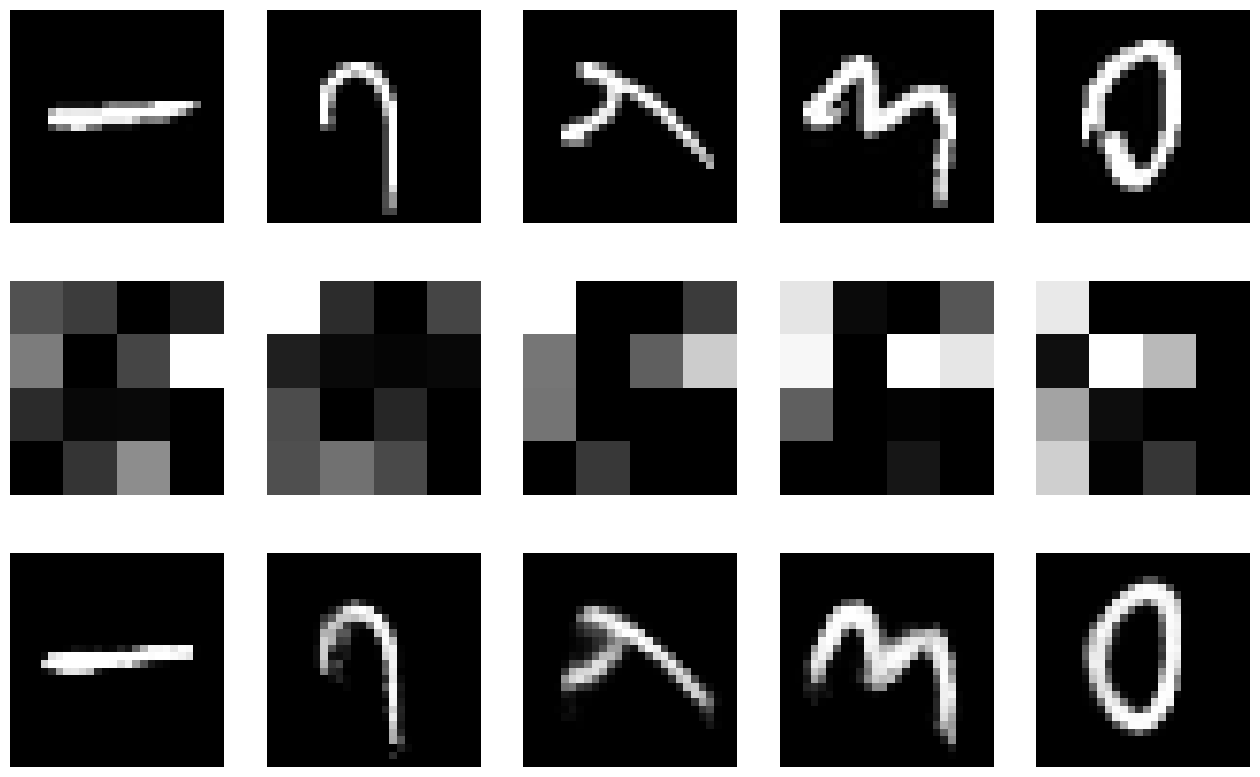

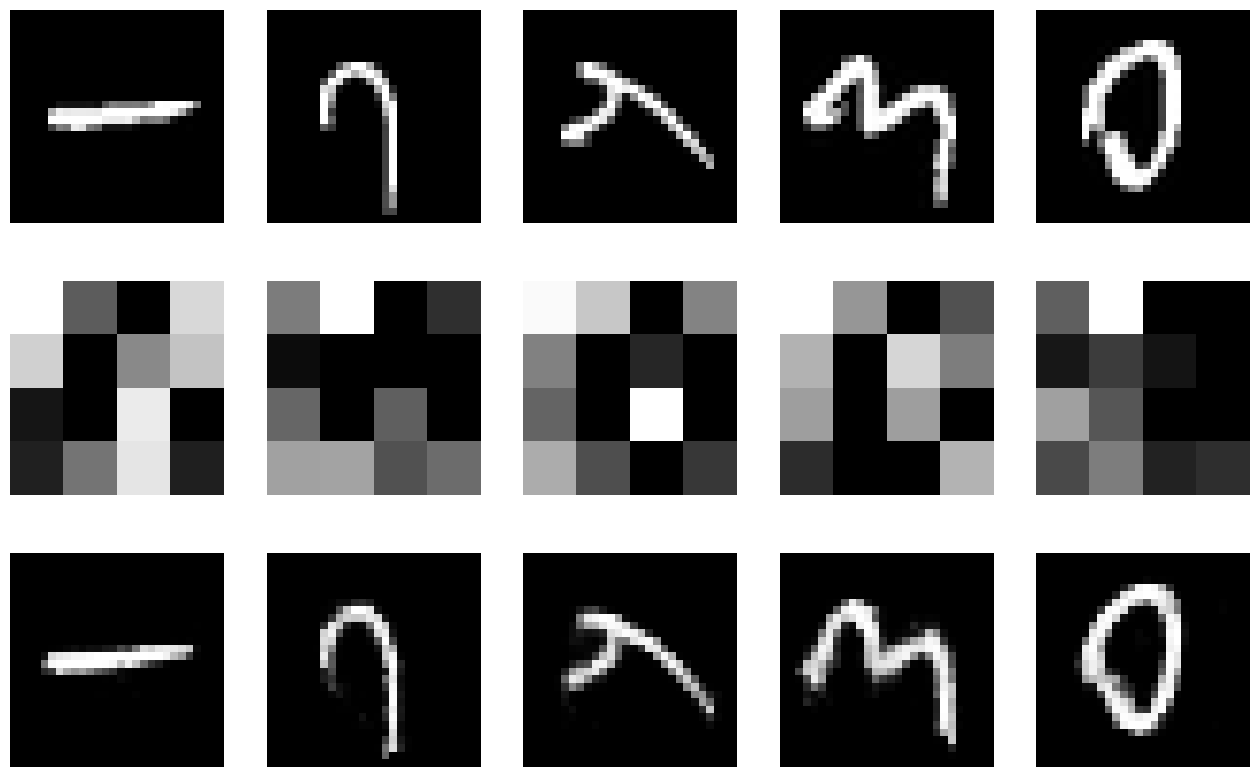

In [117]:
plot_images(img_data,autoencoders3)

Between these two final models, they both use the same activation functions of **Sigmoid/ReLu** and **MSE** for the loss function. Both remaining models ran for 100 epochs with the only difference between the two being the optimizer used.  
Despite the **RMSE** test loss for the encoder using Optimizer **Adagrad** being relatively lower by 1.37%, the visual reconstruction quality of the **Adam** encoder is much cleaner. The images after reconstruction are sharper, having a better defined shape and cleaner edges. They also have less noise around the digits, resulting in less visual blur. Given that the only difference between the two is the optimizer, we will select the **Sigmoid/ReLu/MSE/Adam** encoder as our final version as it has the best reconstruction quality out of all the parameter configurations we tested across the three iterations, using our given encoding architecture.

## Final Selection

Epochs                              100
Final Activation                sigmoid
Hidden Activation                  relu
Loss                          0.0157517
Loss Function        mean_squared_error
Optimizer                          adam
Name: 10, dtype: object

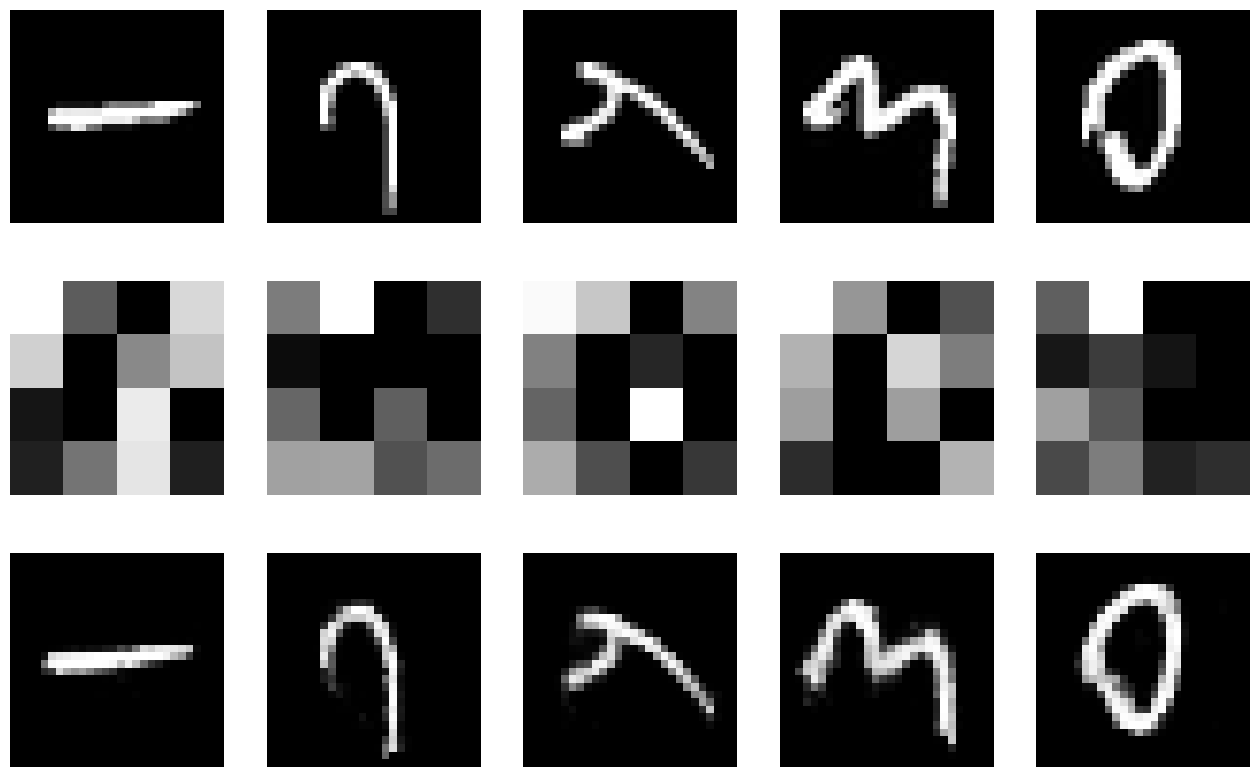

In [122]:
autoencoder = autoencoders3[10]
df_autoencoder_pars = df_encoded_pars3.loc[10]
plot_images(img_data,{1:autoencoder})
df_autoencoder_pars

## Autoencoder Reconstruction Performance

Our selected autoencoder, when tested on unseen images, resulted in a test loss of `0.0157517` using **MSE** or `~0.1255` **RMSE**. Since our values have been normalized between 0 and 1, this means our error is approximately 12.55% of the full greyscale colour range. From comparing the reconstructed images to the originals, the digits' shape and edges are clearly defined, with only gaps spanning 1 to 2 pixels being lost. Additionally, the reconstructed images appear dimmer compared to before encoding. They also tend to have slightly more noise at the ends of each stroke. This is more notable in the second digit as the vertical part on the left appears to have trailing gray pixels. The originals also have a lot more contrast between the black background and the white digit, making edges more sharply defined. All that said, our encoder manages to preserve the identity of each digit, making them instantly recognizable at a glance.

## Encoding Storage Efficiency

## Acknowledgement of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  

Load and Check Data - Sebastian Levy and Miracle Okojie  
Normalize Data and Visualizations - Sebastian Levy  
Prepare Data for Encoding - Sebastian Levy  
Data Observations and Analysis - Sebastian Levy, Idongesit Orok, Miracle Okojie  
Encoder Architechture - Sebastian Levy  
Encoder Iterations - Sebastian Levy  
Encoder Iteration Analysys - Sebastian Levy, Idongesit Orok, Miracle Okojie  
Encoder Selections - Sebastian Levy, Idongesit Orok, Miracle Okojie  
Autoencoder Reconstruction Performance - Sebastian Levy  
Encoding Storage Efficiency -   

We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.